# Decision Tree

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import plot_tree
from matplotlib.pylab import rcParams

In [2]:
iris=load_iris()

X=iris.data
y=iris.target

X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.2)

clf=DecisionTreeClassifier()
clf.fit(X_train,y_train)

y_pred=clf.predict(X_test)
print("Accuracy Score",accuracy_score(y_test,y_pred))

Accuracy Score 0.9666666666666667


[Text(0.5, 0.9166666666666666, 'x[3] <= 1.65\ngini = 0.663\nsamples = 120\nvalue = [35, 40, 45]'),
 Text(0.2, 0.75, 'x[3] <= 0.8\ngini = 0.524\nsamples = 76\nvalue = [35, 39, 2]'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.1, 0.5833333333333334, 'gini = 0.0\nsamples = 35\nvalue = [35, 0, 0]'),
 Text(0.3, 0.5833333333333334, 'x[2] <= 4.95\ngini = 0.093\nsamples = 41\nvalue = [0, 39, 2]'),
 Text(0.2, 0.4166666666666667, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]'),
 Text(0.4, 0.4166666666666667, 'x[3] <= 1.55\ngini = 0.444\nsamples = 3\nvalue = [0, 1, 2]'),
 Text(0.3, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.5, 0.25, 'x[1] <= 2.85\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]'),
 Text(0.4, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(0.6, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.8, 0.75, 'x[2] <= 4.85\ngini = 0.044\nsamples = 44\nvalue = [0, 1, 43]'),
 Text(0.65, 0.8333333333333333, '  False'),


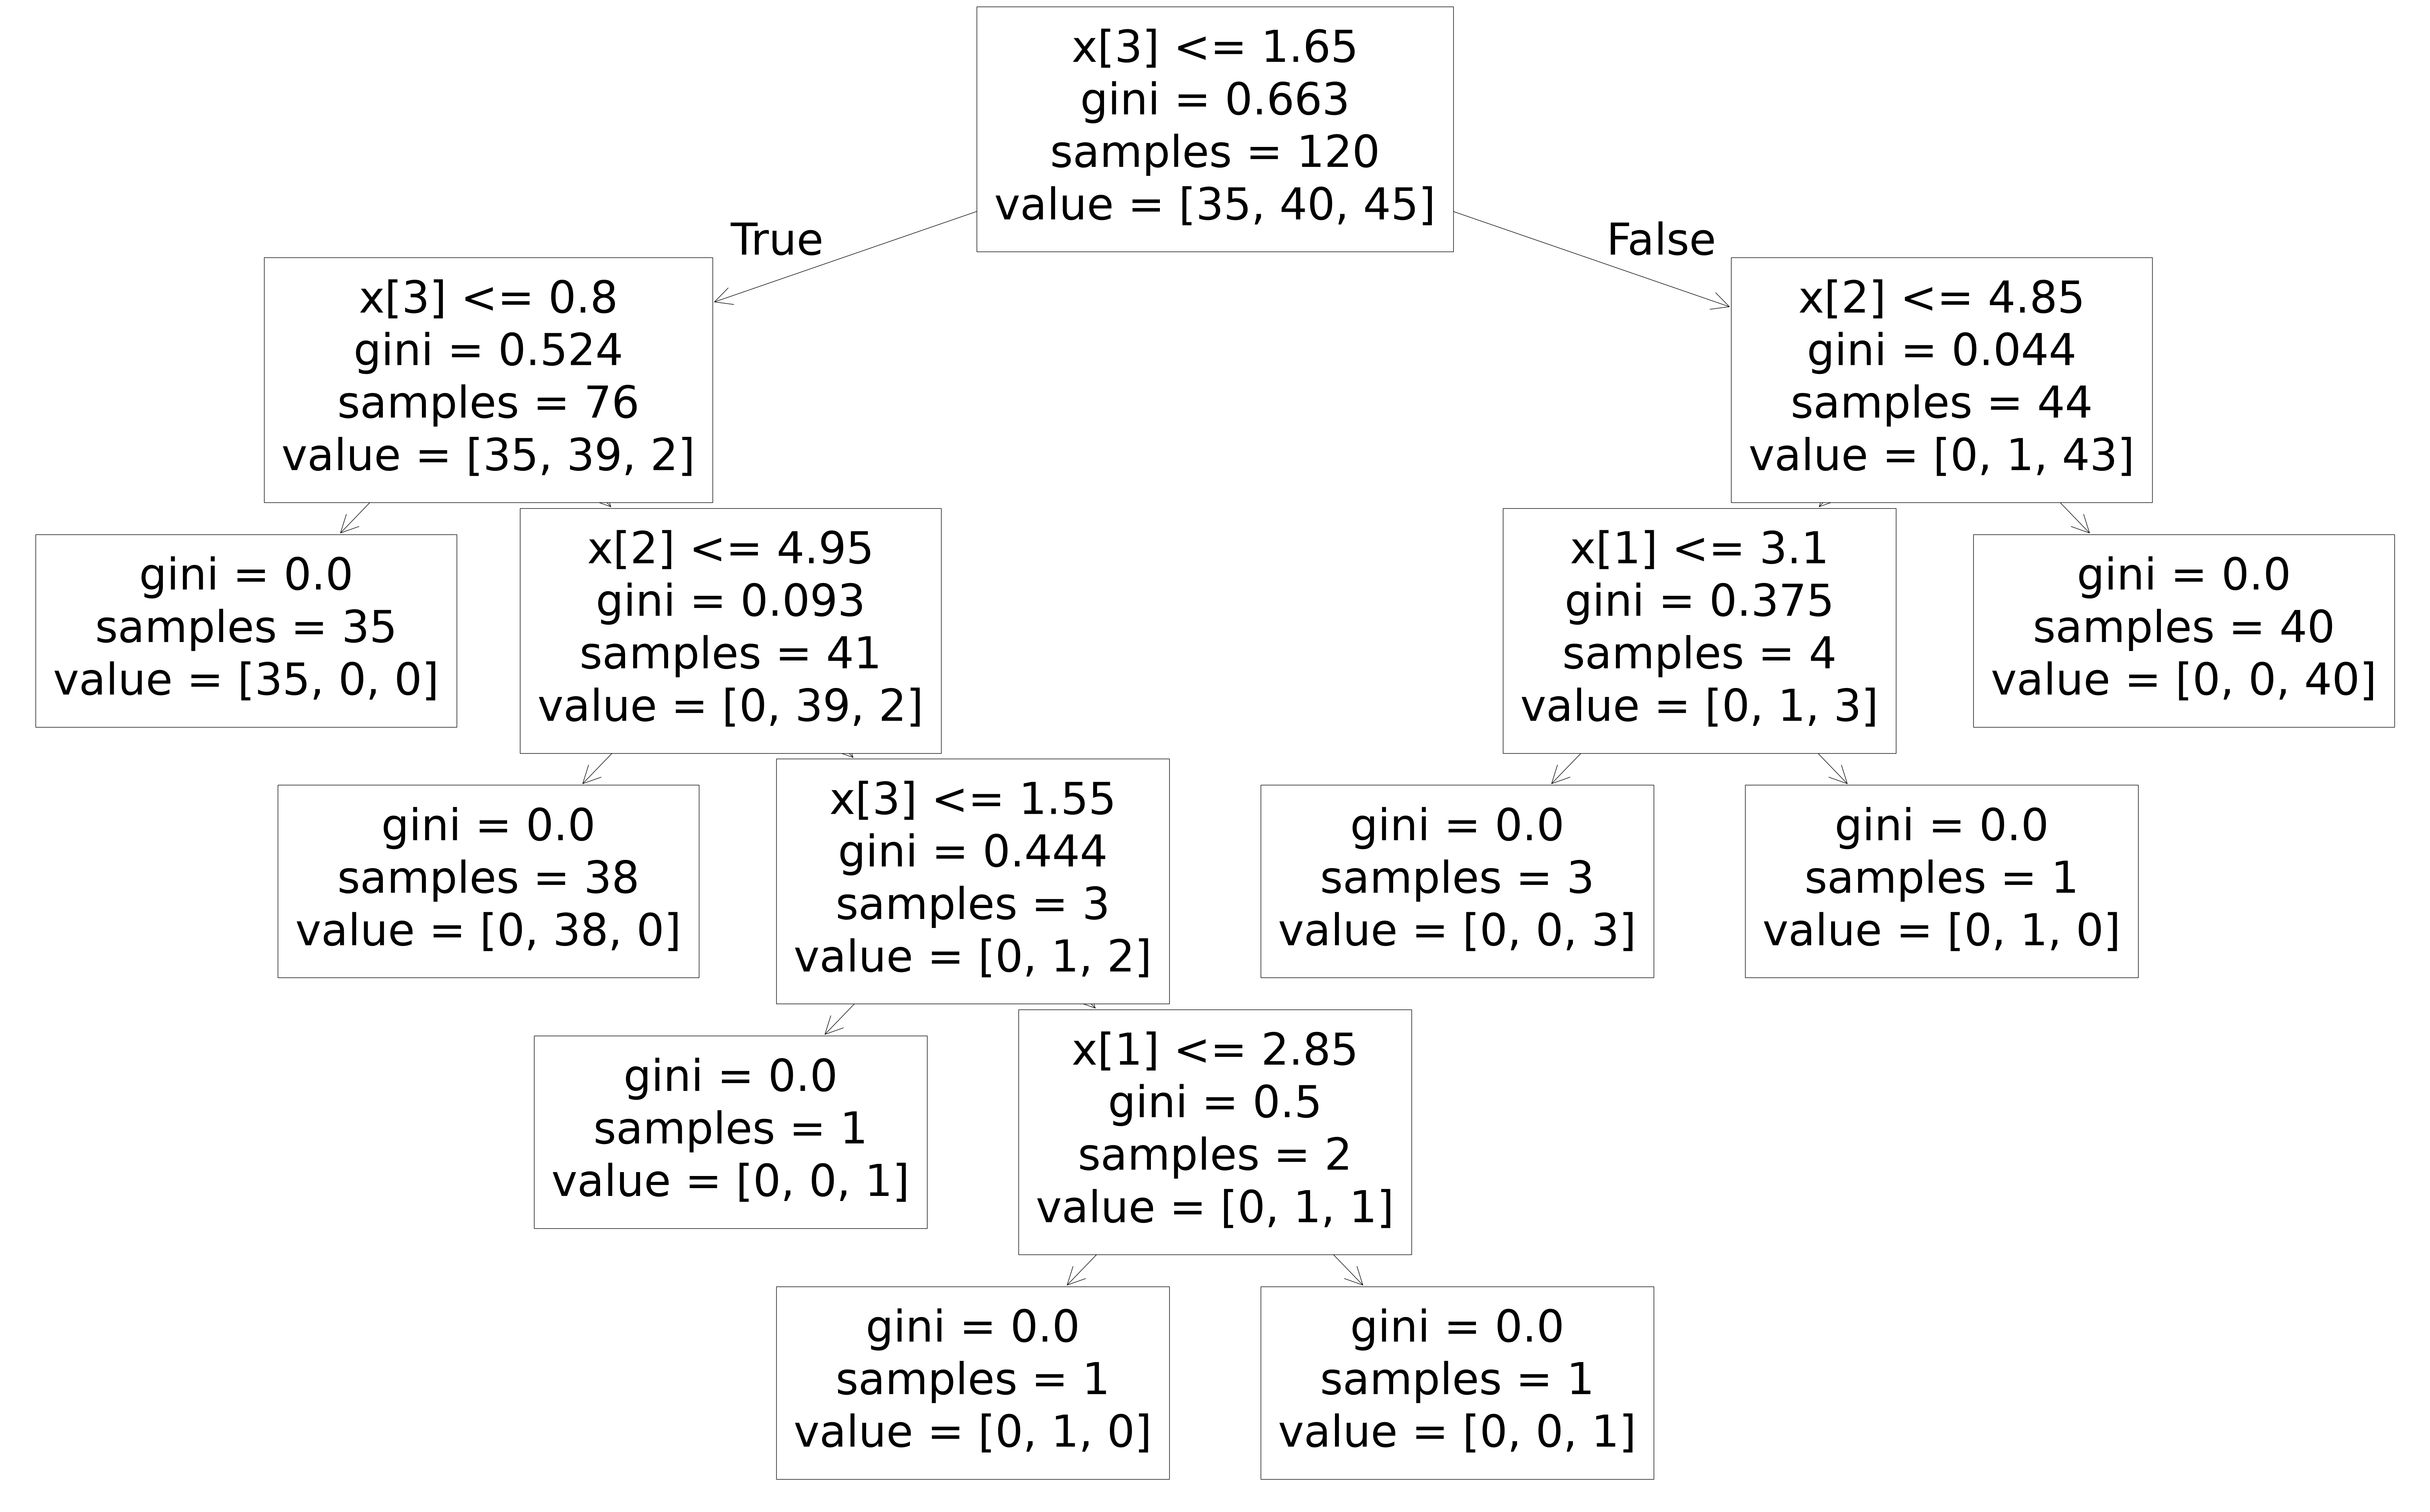

In [3]:
rcParams['figure.figsize'] = 80,50
plot_tree(clf)

## Regression Tree

In [4]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import GridSearchCV

In [5]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data)

df.columns = housing.feature_names
df.head(7)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25


In [6]:
X = df
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

rt = DecisionTreeRegressor(criterion='squared_error', max_depth=5)
rt.fit(X_train,y_train)

y_pred = rt.predict(X_test)
print("R2 Score",r2_score(y_test,y_pred))

R2 Score 0.5997321244428706


# Ensemble

## 1) Voting Ensemble

In [7]:
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import VotingClassifier

In [8]:
df = sns.load_dataset('iris')
df.head()

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1032)>

In [11]:
# Label encode Species
encoder = LabelEncoder()
df['species'] = encoder.fit_transform(df['species'])

#This is done to make it binary ie only two values as answers
new_df = df[df['species'] != 0][['sepal_length','sepal_width','species']]


X = df.iloc[:,0:2]
y = df.iloc[:,-1]

clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = KNeighborsClassifier()


#Accuracy of each model separetely
print("Accuracy of each model separetely")
estimators = [('lr',clf1),('rf',clf2),('knn',clf3)]

for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))

KeyError: 'species'

### Hard Voting

In [12]:
vc = VotingClassifier(estimators=estimators,voting='hard')
x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

NameError: name 'estimators' is not defined

### Soft Voting

In [13]:
vc1 = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc1,X,y,cv=10,scoring='accuracy')
print(np.round(np.mean(x),2))

NameError: name 'estimators' is not defined

### Weighted voting

In [14]:
for i in range(1,4):
    for j in range(1,4):
        for k in range(1,4):
            vc = VotingClassifier(estimators=estimators,voting='soft',weights=[i,j,k])
            x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
            print("for i={},j={},k={} Accuracy".format(i,j,k),np.round(np.mean(x),2))

NameError: name 'estimators' is not defined

## Classifiers of Same Algo
They are same algortihms but with different tuning settings

In [15]:
import numpy as np
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

In [16]:
#Custom Datasets
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=2)

In [17]:
svm1 = SVC(probability=True, kernel='poly', degree=1)
svm2 = SVC(probability=True, kernel='poly', degree=2)
svm3 = SVC(probability=True, kernel='poly', degree=3)
svm4 = SVC(probability=True, kernel='poly', degree=4)
svm5 = SVC(probability=True, kernel='poly', degree=5)

estimators = [('svm1',svm1),('svm2',svm2),('svm3',svm3),('svm4',svm4),('svm5',svm5)]

for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))

vc1 = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc1,X,y,cv=10,scoring='accuracy')
print("Voting Classifier Accuracy",np.round(np.mean(x),2))

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutoria

svm1 0.85


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutoria

svm2 0.85


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutoria

svm3 0.89


... (3 outputs left out)

svm5 0.86


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutoria

Voting Classifier Accuracy 0.93


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Voting Regressor

In [18]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import cross_val_score

In [19]:
housing = fetch_california_housing()

X = housing.data
y = housing.target


lr = LinearRegression()
dt = DecisionTreeRegressor(random_state=42)
knn = KNeighborsRegressor()

estimators = [('lr', lr), ('dt', dt), ('knn', knn)]


for estimator in estimators:
    scores = cross_val_score(estimator[1], X, y, scoring='r2', cv=10)

    print(estimator[0], np.round(np.mean(scores), 2))


vr = VotingRegressor(estimators)

scores = cross_val_score(vr, X, y, scoring='r2', cv=10)

print("Voting Regressor", np.round(np.mean(scores), 2))

# Weighted Voting
for i in range(1, 4):
    for j in range(1, 4):
        for k in range(1, 4):

            vr = VotingRegressor(estimators, weights=[i, j, k])

            scores = cross_val_score(vr, X, y, scoring='r2', cv=10)

            print("For i={}, j={}, k={} Accuracy".format(i, j, k), np.round(np.mean(scores), 2))

lr 0.51
dt 0.24
knn -0.14
Voting Regressor 0.48
For i=1, j=1, k=1 Accuracy 0.48
For i=1, j=1, k=2 Accuracy 0.39
For i=1, j=1, k=3 Accuracy 0.31
For i=1, j=2, k=1 Accuracy 0.48
For i=1, j=2, k=2 Accuracy 0.43
For i=1, j=2, k=3 Accuracy 0.38
For i=1, j=3, k=1 Accuracy 0.46
For i=1, j=3, k=2 Accuracy 0.44
For i=1, j=3, k=3 Accuracy 0.41
For i=2, j=1, k=1 Accuracy 0.52
For i=2, j=1, k=2 Accuracy 0.45
For i=2, j=1, k=3 Accuracy 0.39
For i=2, j=2, k=1 Accuracy 0.52
For i=2, j=2, k=2 Accuracy 0.48
For i=2, j=2, k=3 Accuracy 0.43
For i=2, j=3, k=1 Accuracy 0.51
For i=2, j=3, k=2 Accuracy 0.49
For i=2, j=3, k=3 Accuracy 0.45
For i=3, j=1, k=1 Accuracy 0.53
For i=3, j=1, k=2 Accuracy 0.48
For i=3, j=1, k=3 Accuracy 0.43
For i=3, j=2, k=1 Accuracy 0.54
For i=3, j=2, k=2 Accuracy 0.51
For i=3, j=2, k=3 Accuracy 0.47
For i=3, j=3, k=1 Accuracy 0.53
For i=3, j=3, k=2 Accuracy 0.51
For i=3, j=3, k=3 Accuracy 0.48


### Using the same algorithm

In [20]:
dt1 = DecisionTreeRegressor(max_depth=1)
dt2 = DecisionTreeRegressor(max_depth=3)
dt3 = DecisionTreeRegressor(max_depth=5)
dt4 = DecisionTreeRegressor(max_depth=7)
dt5 = DecisionTreeRegressor(max_depth=None)

estimators = [('dt1',dt1),('dt2',dt2),('dt3',dt3),('dt4',dt4),('dt5',dt5)]

for estimator in estimators:
  scores = cross_val_score(estimator[1],X,y,scoring='r2',cv=10)
  print(estimator[0],np.round(np.mean(scores),2))

vr = VotingRegressor(estimators)
scores = cross_val_score(vr,X,y,scoring='r2',cv=10)
print("Voting Regressor",np.round(np.mean(scores),2))

dt1 0.13
dt2 0.36
dt3 0.43
dt4 0.47
dt5 0.23
Voting Regressor 0.5


## 2) Bagging

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [22]:
df = sns.load_dataset('iris')
df.sample(5)

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1032)>

In [23]:
# Label encode Species
encoder = LabelEncoder()
df['species'] = encoder.fit_transform(df['species'])

#This is done to make it binary ie only two values as answers
df = df[df['species'] != 0][['sepal_width','petal_length','species']]


plt.scatter(df['sepal_width'],df['petal_length'],c=df['species'],cmap='winter')

KeyError: 'species'

In [24]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)    #Taking only 10 rows from first 60
df_val = df.iloc[60:80,:].sample(5)    #Taking only 5 rows from 60 to 80 rows
df_test = df.iloc[80:,:].sample(5)    #Taking only 5 rows from last 20



X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [25]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print("Accuracy",accuracy_score(y_test,y_pred))

# Different Data for Same Tree model
df_bag1 = df_train.sample(8,replace=True)    #Taking 8 rows where rows can be repeated
df_bag2 = df_train.sample(8,replace=True)
df_bag3 = df_train.sample(8,replace=True)

# Dataset 1
X1 = df_bag1.iloc[:, 0:2]
y1 = df_bag1.iloc[:, -1]

# Dataset 2
X2 = df_bag2.iloc[:, 0:2]
y2 = df_bag2.iloc[:, -1]

# Dataset 3
X3 = df_bag3.iloc[:, 0:2]
y3 = df_bag3.iloc[:, -1]

# Tree Models
dt_bag1 = DecisionTreeClassifier()
dt_bag2 = DecisionTreeClassifier()
dt_bag3 = DecisionTreeClassifier()

In [26]:
evaluate(dt_bag1,X1,y1)

ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [27]:
evaluate(dt_bag2,X2,y2)

ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [28]:
evaluate(dt_bag3,X3,y3)

ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [ ]:
df_test

,sepal_width,petal_length,species
57,2.4,3.3,1
58,2.9,4.6,1
92,2.6,4.0,1
61,3.0,4.2,1
86,3.1,4.7,1


In [ ]:
print("Predictor 1",dt_bag1.predict(np.array([3.0,4.9]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.6,4.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.8,6.1]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [1]
Predictor 3 [2]


c:\Coding\Arificial Intelligence\Machine Learning Tutorial\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Coding\Arificial Intelligence\Machine Learning Tutorial\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Coding\Arificial Intelligence\Machine Learning Tutorial\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


#### Pasting -> Same as Bagging but without replacement that means that rows will not repeat
#### Random Subspaces -> Data is given with changes not in rows but in columns that ie every model gets a different combination of columns aka column sampling
#### Random Patches -> Both rows and cols combination are given aka row+col sampling

### Using Bagging Classifier Library

In [29]:
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

In [30]:
X,y = make_classification(n_samples=10000, n_features=10,n_informative=3)

In [31]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print("Accuracy without using Bagging",accuracy_score(y_test,y_pred))



bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=500, max_samples=0.5, bootstrap=True, random_state=42)
#n_estimators total 500 trees used ie 500 models
#max_samples each gets only 50% of the data
#bootstrap=True row repetition allowed

bag.fit(X_train,y_train)
y_pred = bag.predict(X_test)

print("Accuracy using Bagging", accuracy_score(y_test,y_pred))

Accuracy without using Bagging 0.935
Accuracy using Bagging 0.957


- For pasting -> bootstrap=False
- For Random Subspaces -> max_samples=1.0 & max_features=0.5
- For Random Patches -> max_samples=0.25 & max_features=0.5
- To check OOB Score -> oob_score=True

### Bagging Regressor

In [32]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingRegressor

In [33]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data)

df.head()

,0,1,2,3,4,5,6,7
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [34]:
X_housing, Y_housing = housing.data, housing.target

In [35]:
X_train, X_test, Y_train, Y_test = train_test_split(X_housing, Y_housing , train_size=0.80, test_size=0.20, random_state=123)
print('Train/Test Sets Sizes : ',X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

lr = LinearRegression()
dt = DecisionTreeRegressor()
knn = KNeighborsRegressor()

lr.fit(X_train,Y_train)
dt.fit(X_train,Y_train)
knn.fit(X_train,Y_train)

y_pred1 = lr.predict(X_test)
y_pred2 = dt.predict(X_test)
y_pred3 = knn.predict(X_test)

print("R^2 score for LR",r2_score(Y_test,y_pred1))
print("R^2 score for DT",r2_score(Y_test,y_pred2))
print("R^2 score for KNN",r2_score(Y_test,y_pred3))

bag_regressor = BaggingRegressor(random_state=1)
bag_regressor.fit(X_train, Y_train)

Y_preds = bag_regressor.predict(X_test)

print("R^2 score for Bag Regressor",r2_score(Y_test,Y_preds))
print('Training Coefficient of R^2 : %.3f'%bag_regressor.score(X_train, Y_train))
print('Test Coefficient of R^2 : %.3f'%bag_regressor.score(X_test, Y_test))

Train/Test Sets Sizes :  (16512, 8) (4128, 8) (16512,) (4128,)
R^2 score for LR 0.6104546894797869
R^2 score for DT 0.5959345436522365
R^2 score for KNN 0.16261917827057237
R^2 score for Bag Regressor 0.7943315100523031
Training Coefficient of R^2 : 0.963
Test Coefficient of R^2 : 0.794


## Random Forest 

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

In [37]:
df = pd.read_csv('DataSets/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [38]:
X = df.iloc[:,0:-1]
y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

rf = RandomForestClassifier(oob_score=True)
gb = GradientBoostingClassifier()
svc = SVC()

gb.fit(X_train,y_train)
y_predgb = gb.predict(X_test)
print("Accuracy of Gradient Boosting",accuracy_score(y_test,y_predgb))

svc.fit(X_train,y_train)
y_predsvc = svc.predict(X_test)
print("Accuracy of SVC",accuracy_score(y_test,y_predsvc))

rf.fit(X_train,y_train)
y_predrf = rf.predict(X_test)
print("Accuracy of Random Forest with tuning",accuracy_score(y_test,y_predrf))


print("Cross Validation Score of Random Forest",np.mean(cross_val_score(RandomForestClassifier(max_samples=0.75),X,y,cv=10,scoring='accuracy')))

print("OOB Score of Random Forest",rf.oob_score_)

Accuracy of Gradient Boosting 0.9317073170731708
Accuracy of SVC 0.6829268292682927
Accuracy of Random Forest with tuning 0.9853658536585366
Cross Validation Score of Random Forest 0.9950980392156863
OOB Score of Random Forest 0.9951219512195122


### Feature Importance

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

In [40]:
df = pd.read_csv('DataSets/mnist.csv')
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [41]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [42]:
rf = RandomForestClassifier()
rf.fit(X,y)

data = rf.feature_importances_
data

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 2.10999766e-06, 0.00000000e+00,
       0.00000000e+00, 2.15983230e-06, 1.23591229e-05, 6.29958768e-06,
       4.22132799e-06, 2.18007348e-05, 2.19827157e-06, 0.00000000e+00,
       4.65067552e-06, 0.00000000e+00, 1.77868760e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [43]:
#As you can see that sum of numpy every element ie all values of features importance adds up to 0
data.sum()

np.float64(1.0)

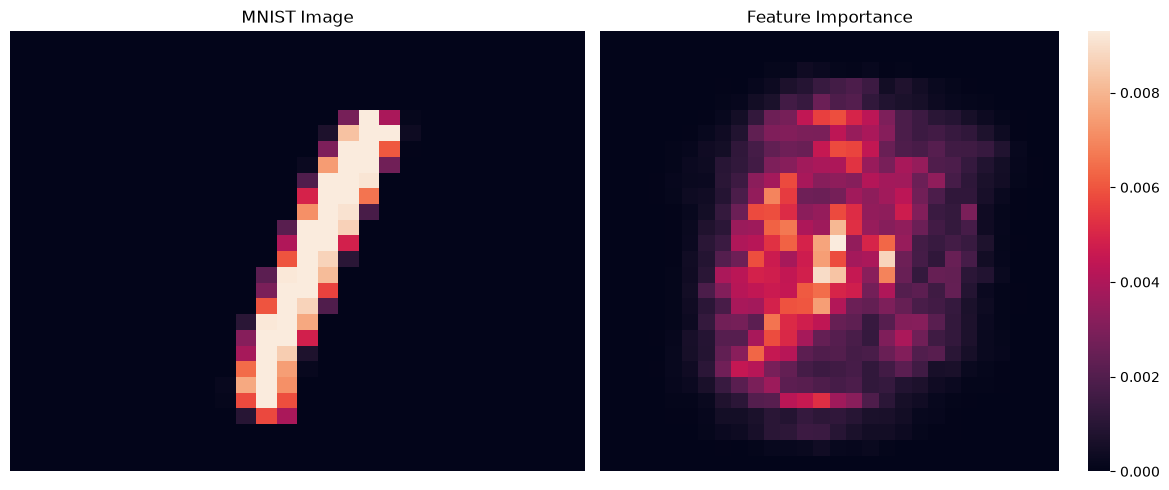

In [44]:
plt.figure(figsize=(12,5))


plt.subplot(1,2,1)
sns.heatmap(X.iloc[5].values.reshape(28,28), cbar=False)
plt.title("MNIST Image")
plt.axis('off')


plt.subplot(1,2,2)
sns.heatmap(rf.feature_importances_.reshape(28,28), cbar=True)
plt.title("Feature Importance")
plt.axis('off')

plt.tight_layout()
plt.show()

## 3) Boosting

## Adaboost

In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [46]:
df = pd.DataFrame()

df['X1'] = [1,2,3,4,5,6,6,7,9,9]
df['X2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] = [1,1,0,1,0,1,0,1,0,0]

df

,X1,X2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='X1', ylabel='X2'>

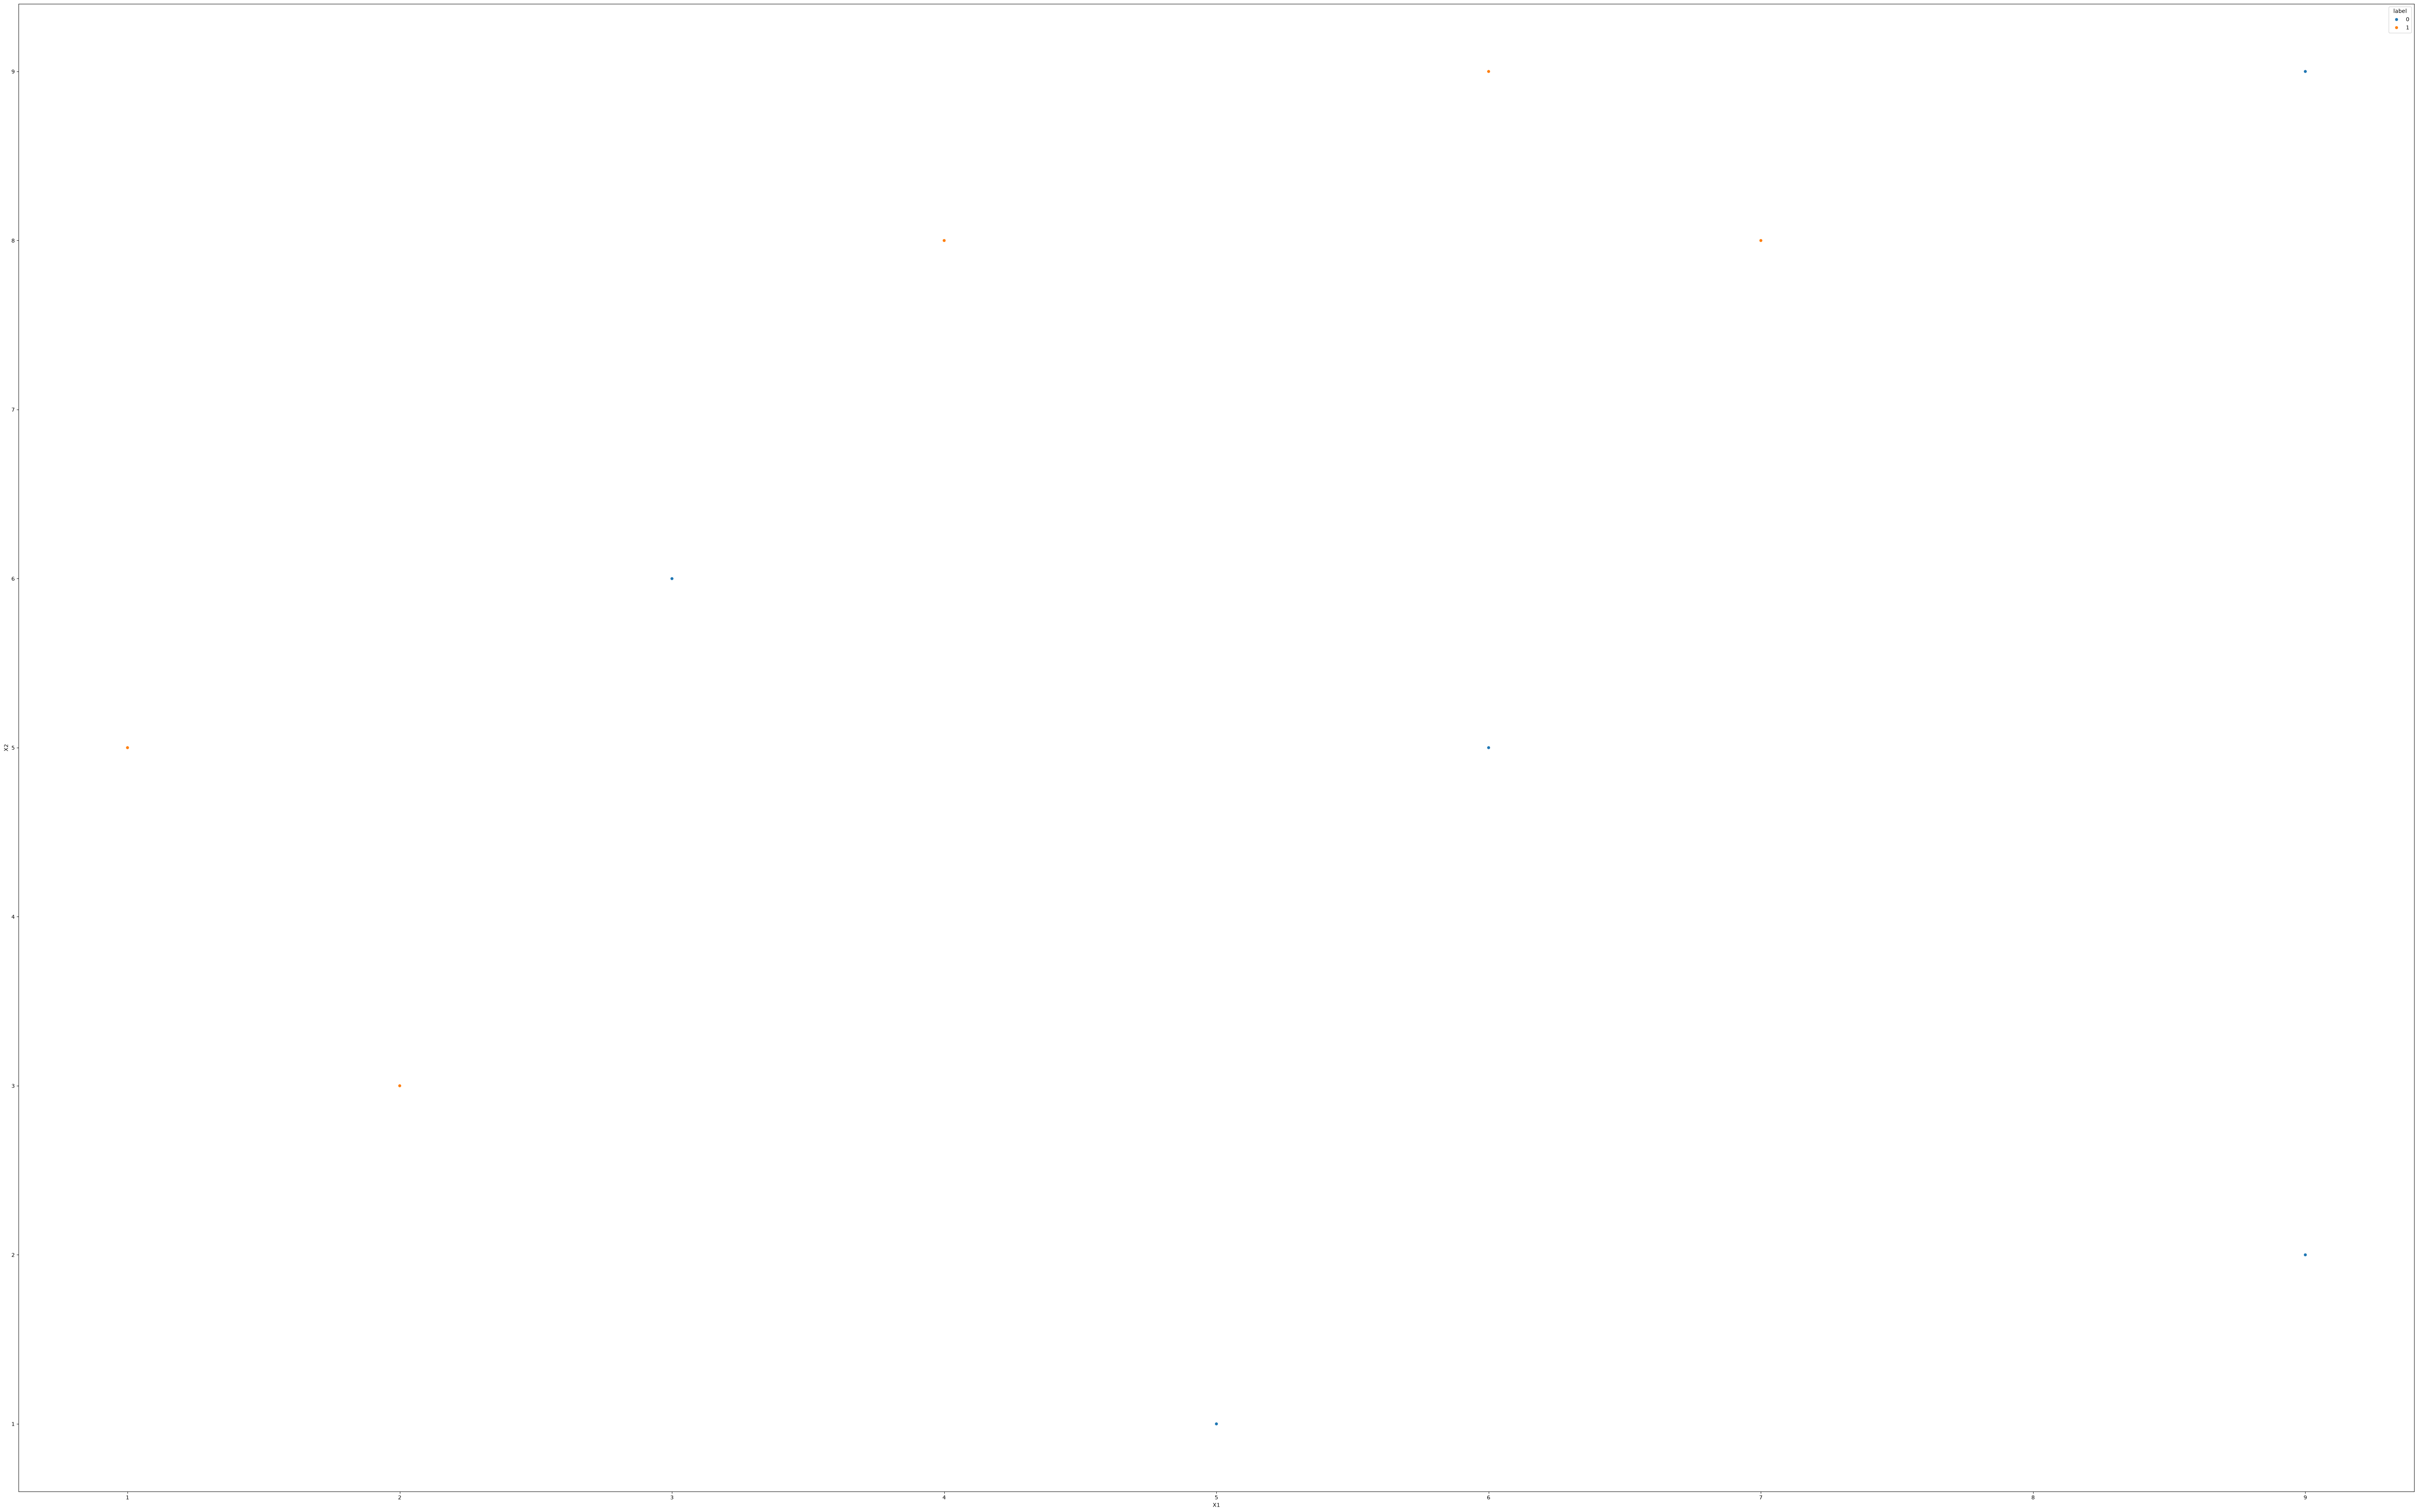

In [47]:
sns.scatterplot(x=df['X1'],y=df['X2'],hue=df['label'])

In [48]:
#Initially all rows have same weight if not then make it so by this
df['weights'] = 1/df.shape[0]

In [49]:
dt1 = DecisionTreeClassifier(max_depth=1)

X = df.iloc[:,0:2].values
y = df.iloc[:,2].values

#step 2 - train data
dt1.fit(X,y)

df['y_pred'] = dt1.predict(X)


# Step 3 - calculate model weight
def calculate_model_weight(error):
  return 0.5*np.log((1-error)/(error))
    
alpha1 = calculate_model_weight(0.3)
print("Weightage of first model",alpha1)


# Step 4 - Update weights
def update_row_weights(row,alpha=0.423):
  if row['label'] == row['y_pred']:
    return row['weights'] * np.exp(-alpha)
  else:
    return row['weights'] * np.exp(alpha)


df['updated_weights'] = df.apply(update_row_weights,axis=1)
print(df)
print("Updates Weight sum",df['updated_weights'].sum())

#As we can see that sum is not 1 so make it 1

df['nomalized_weights'] = df['updated_weights']/df['updated_weights'].sum()
print(df)
print("Normalised Weight sum",round(df['nomalized_weights'].sum(), 10))

df['cumsum_upper'] = np.cumsum(df['nomalized_weights'])    #cummulative sum range
df['cumsum_lower'] = df['cumsum_upper'] - df['nomalized_weights']

print(df[['X1','X2','label','weights','y_pred','updated_weights','cumsum_lower','cumsum_upper']])

Weightage of first model 0.42364893019360184
   X1  X2  label  weights  y_pred  updated_weights
0   1   5      1      0.1       1         0.065508
1   2   3      1      0.1       1         0.065508
2   3   6      0      0.1       0         0.065508
3   4   8      1      0.1       0         0.152653
4   5   1      0      0.1       0         0.065508
5   6   9      1      0.1       0         0.152653
6   6   5      0      0.1       0         0.065508
7   7   8      1      0.1       0         0.152653
8   9   9      0      0.1       0         0.065508
9   9   2      0      0.1       0         0.065508
Updates Weight sum 0.9165153319682015
   X1  X2  label  weights  y_pred  updated_weights  nomalized_weights
0   1   5      1      0.1       1         0.065508           0.071475
1   2   3      1      0.1       1         0.065508           0.071475
2   3   6      0      0.1       0         0.065508           0.071475
3   4   8      1      0.1       0         0.152653           0.166559
4   5 

[Text(0.5, 0.75, 'x[0] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [5, 3]'),
 Text(0.625, 0.5, '  False')]

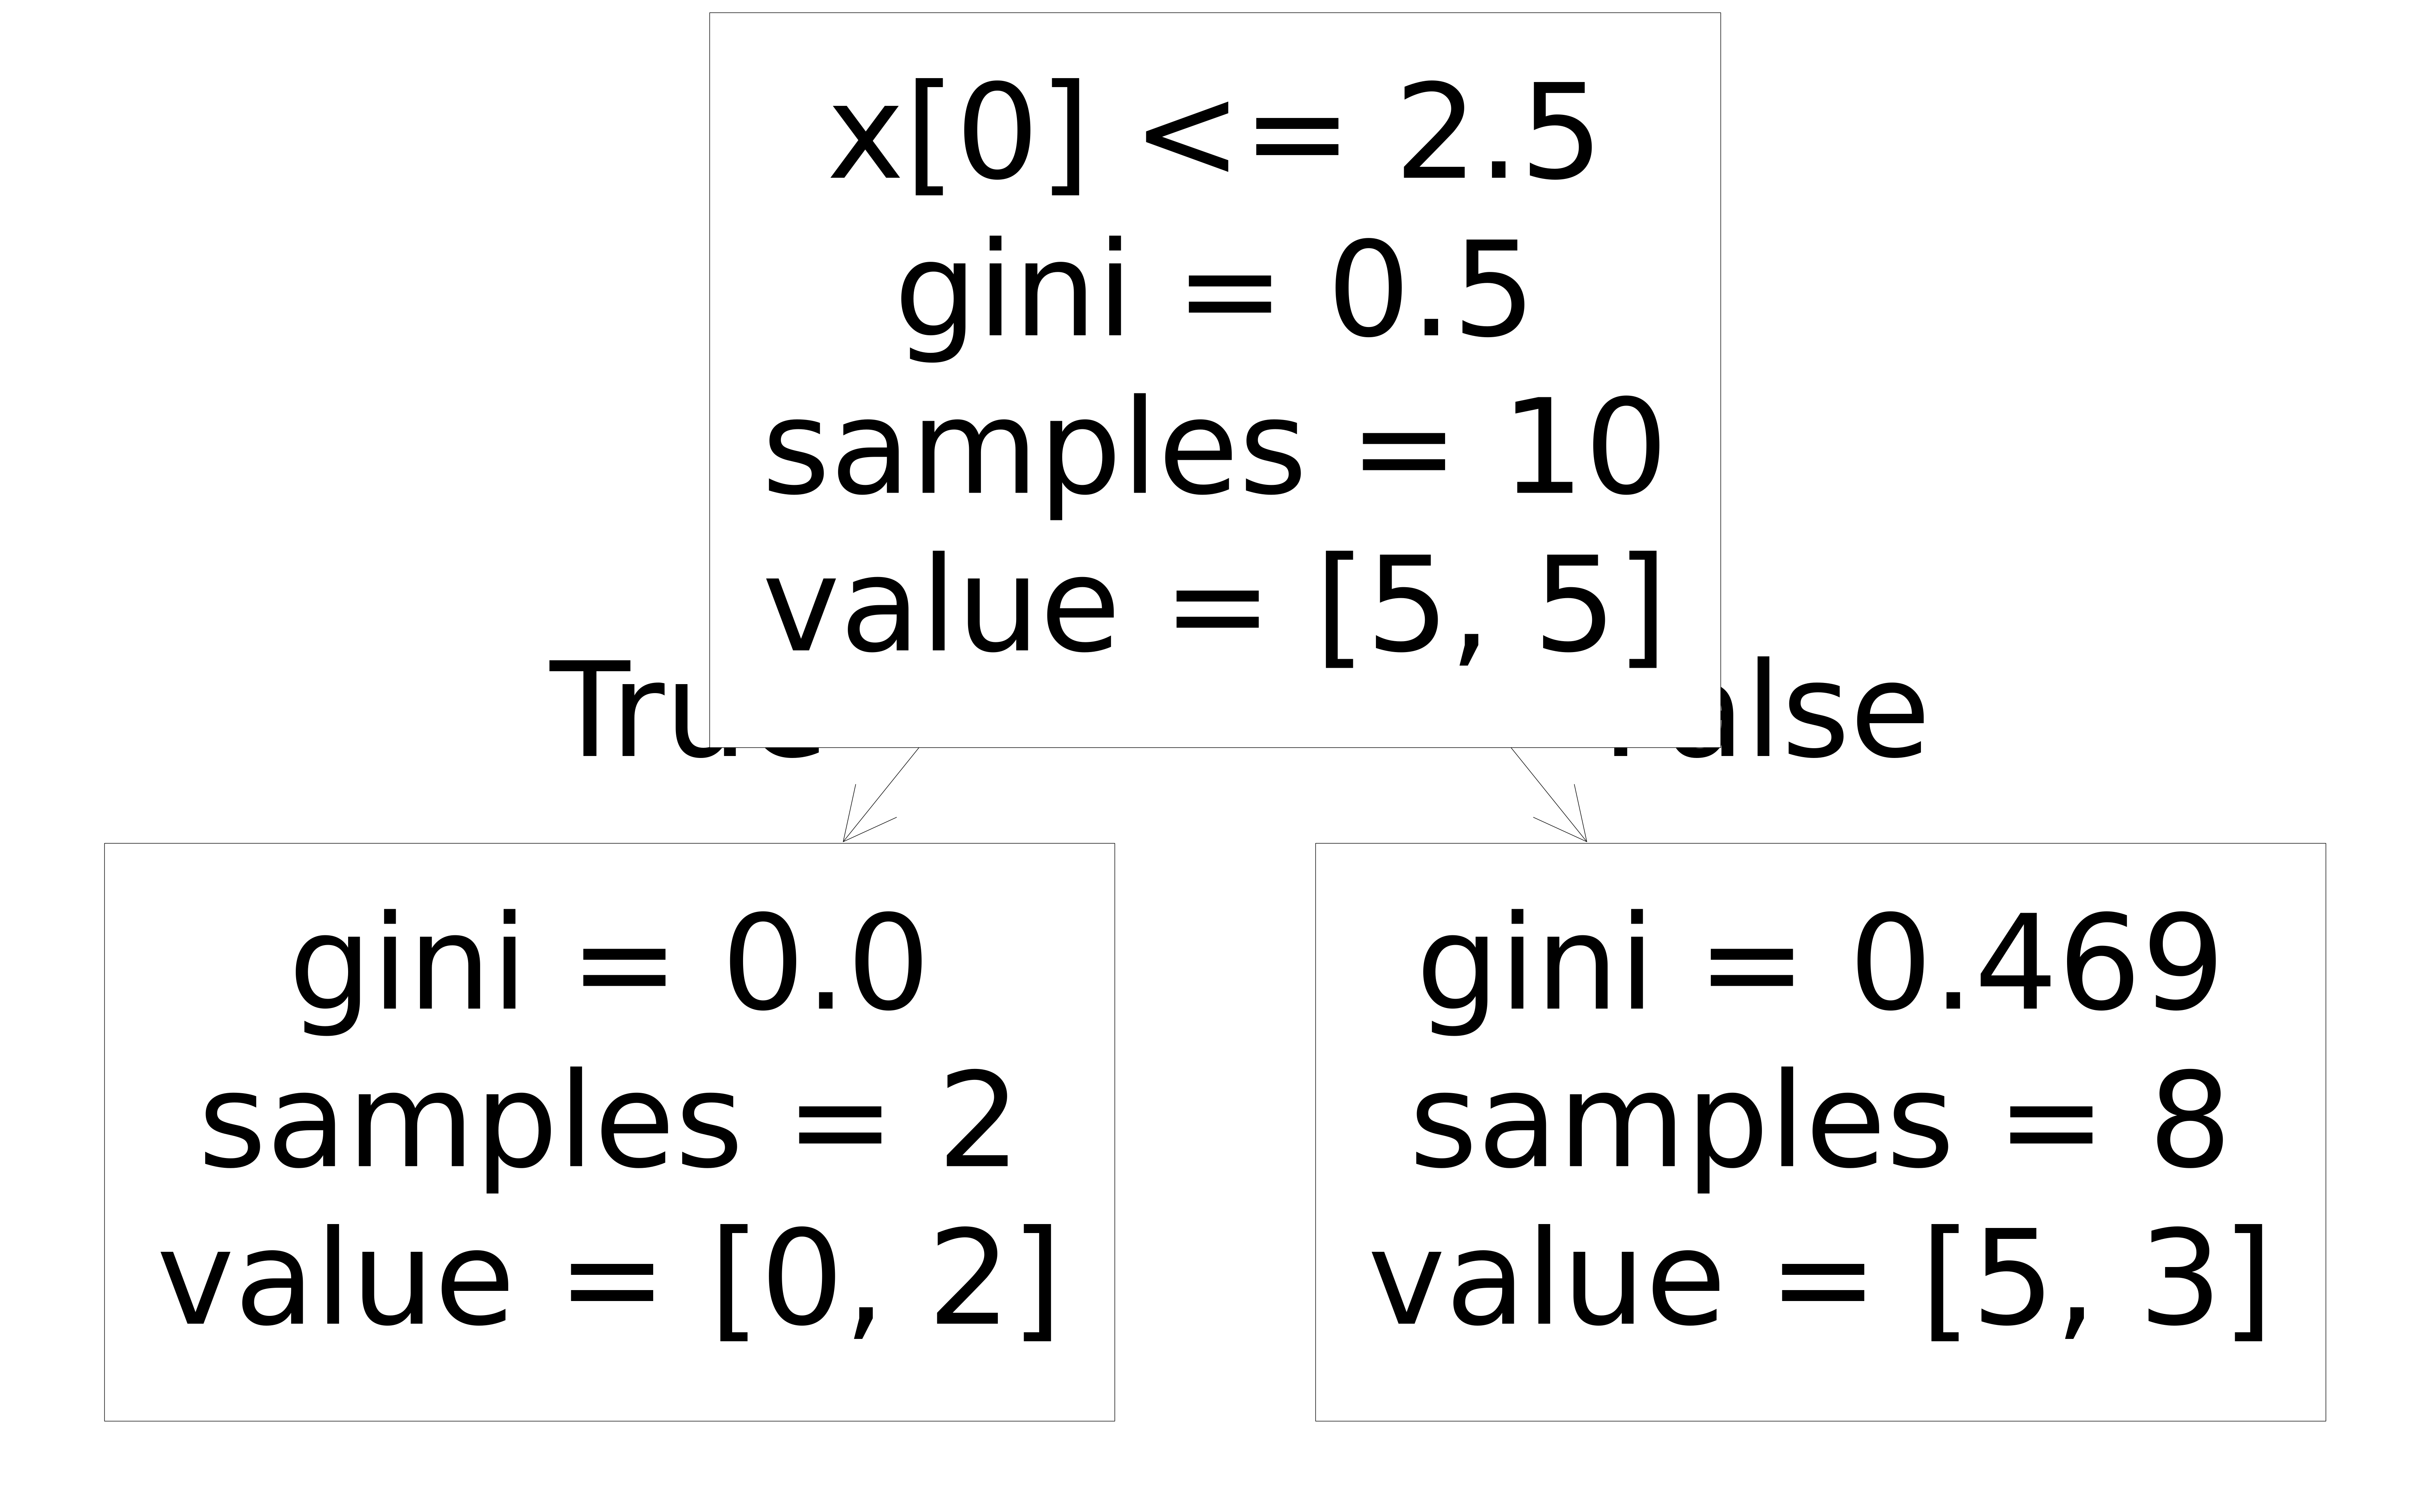

In [50]:
plot_tree(dt1)

<Axes: >

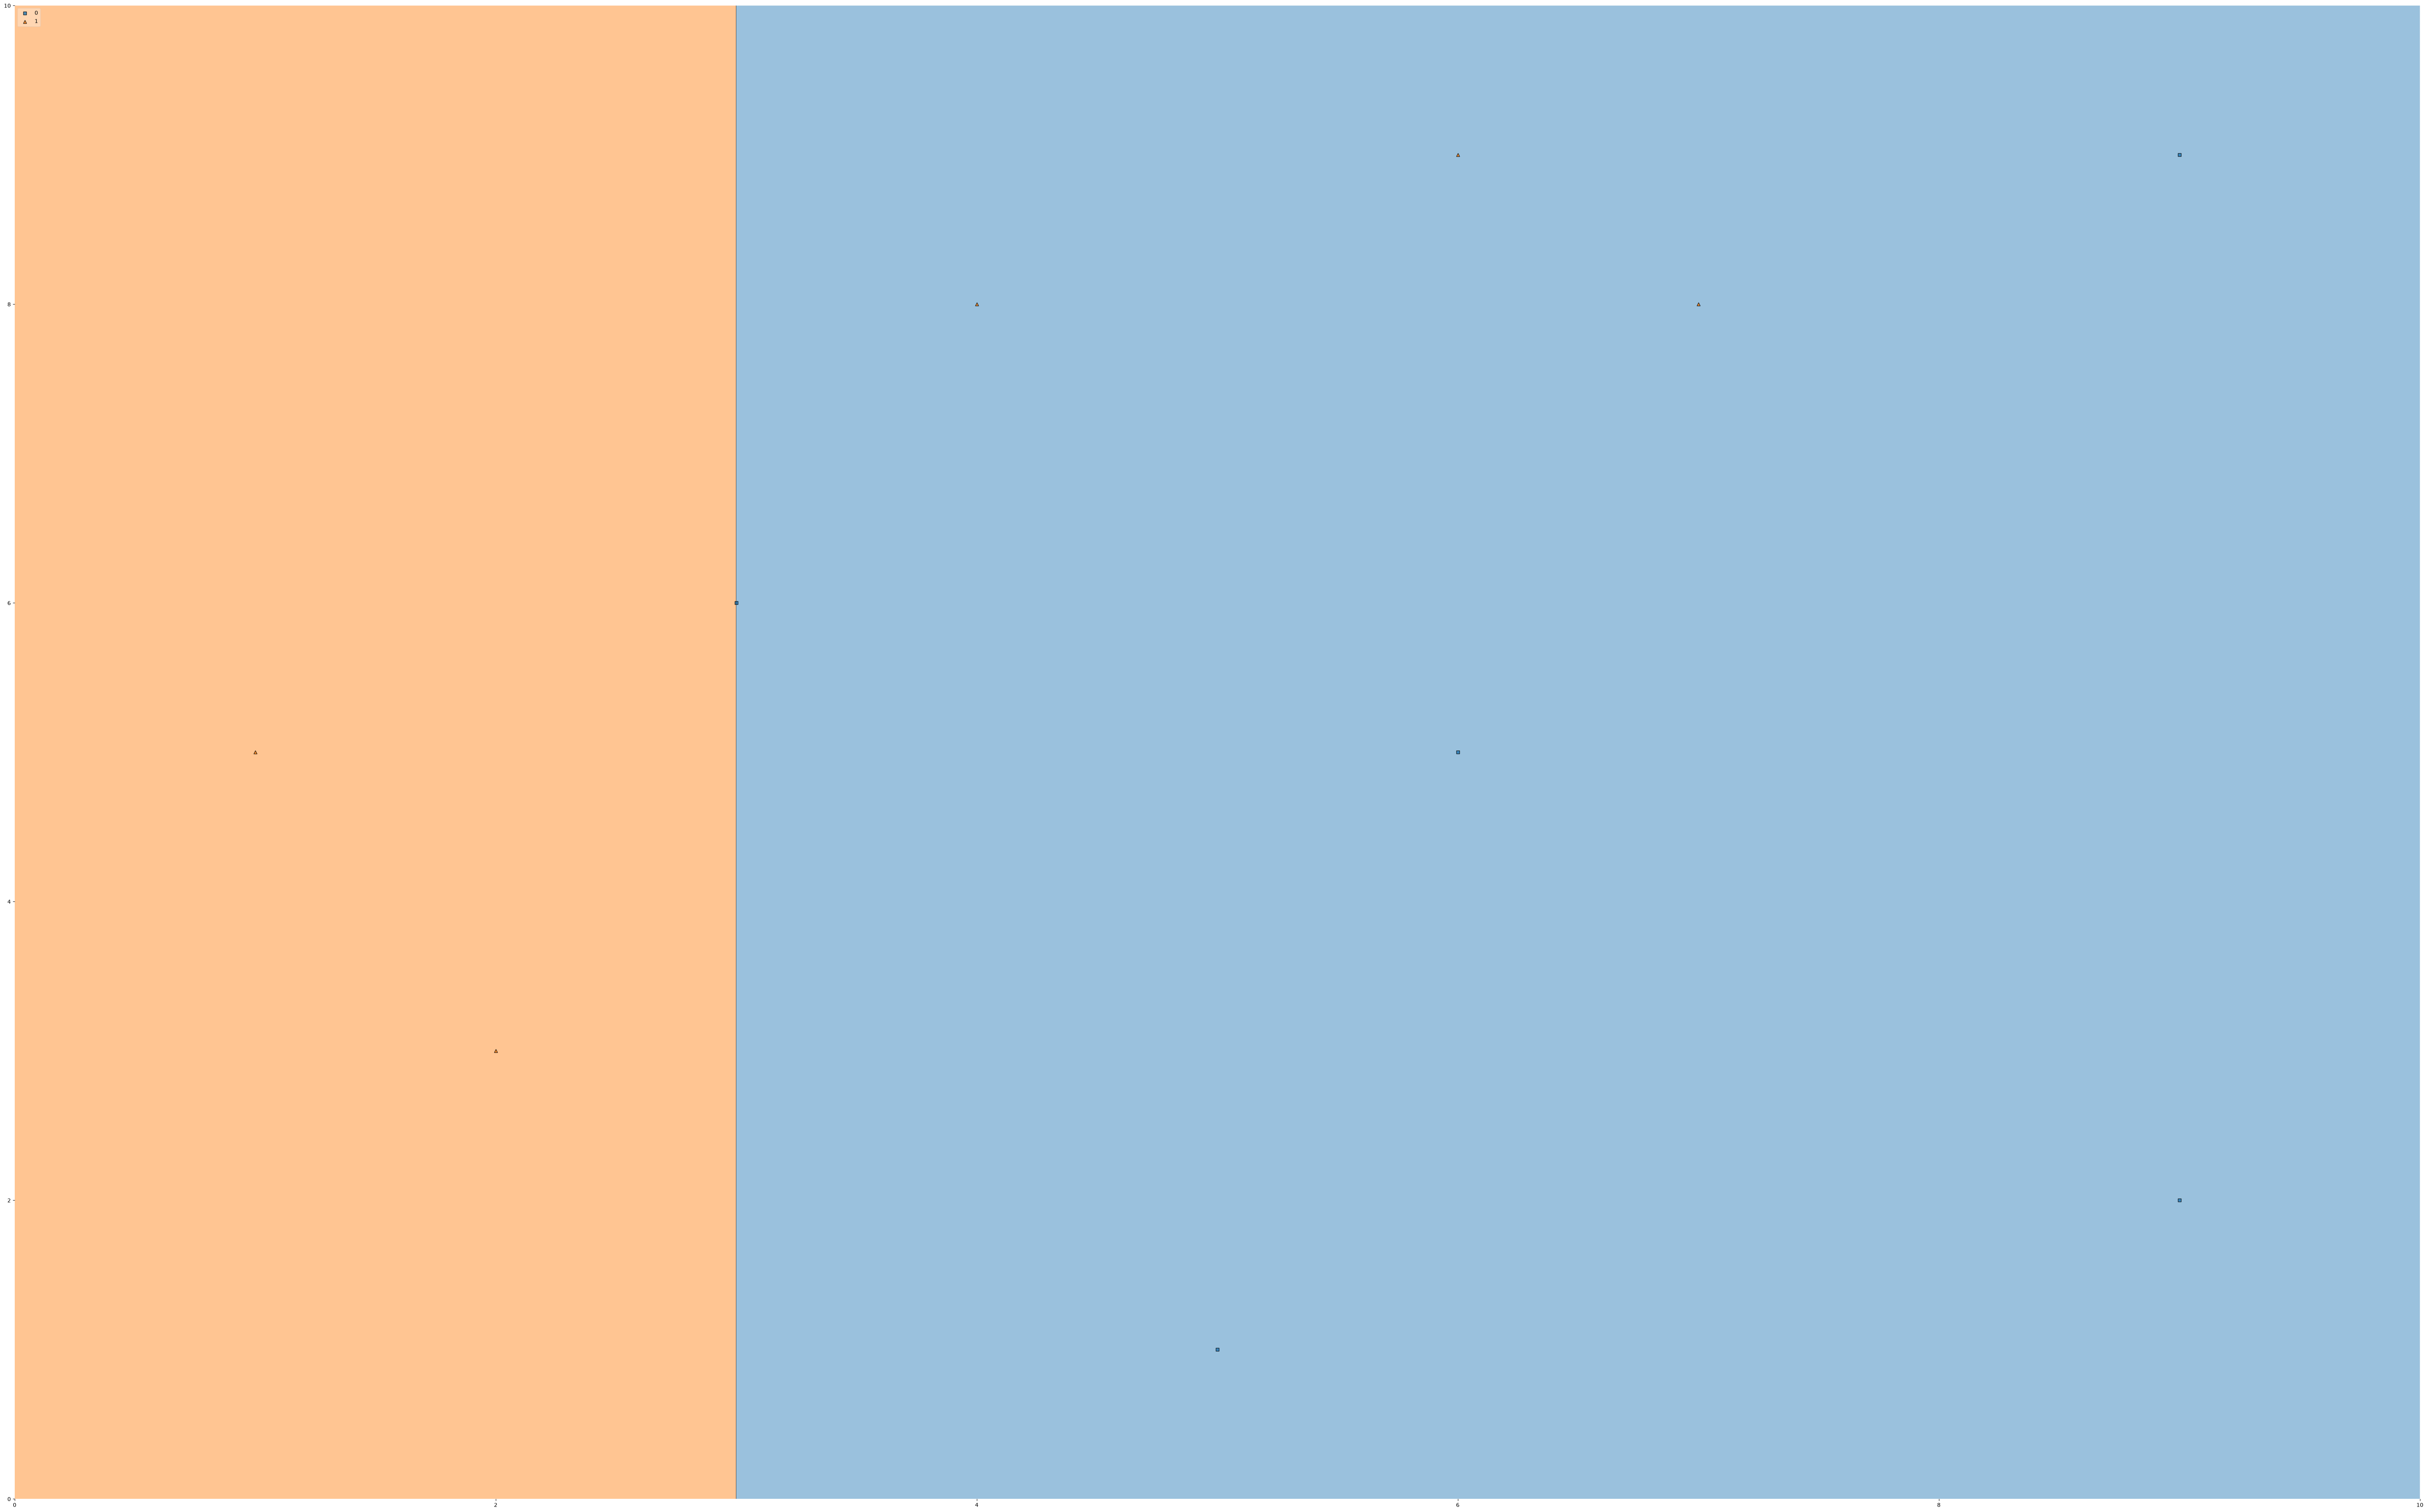

In [51]:
plot_decision_regions(X, y, clf=dt1, legend=2)

In [52]:
#taking dataset 1, creating 10 random numbers, checking in which range they fall in, pushing that row index into indices so that we can send those rows into decision stump 2

def create_new_dataset(df):
  indices = []

  for i in range(df.shape[0]):
    a = np.random.random()
    for index,row in df.iterrows():
      if row['cumsum_upper'] > a and a > row['cumsum_lower']:
        indices.append(index)
  return indices

index_values = create_new_dataset(df)
index_values

[5, 6, 2, 5, 5, 0, 3, 3, 4, 3]

In [53]:
second_df = df.iloc[index_values,[0,1,2,3]]
second_df

,X1,X2,label,weights
5,6,9,1,0.1
6,6,5,0,0.1
2,3,6,0,0.1
5,6,9,1,0.1
5,6,9,1,0.1
0,1,5,1,0.1
3,4,8,1,0.1
3,4,8,1,0.1
4,5,1,0,0.1
3,4,8,1,0.1


In [54]:
X = second_df.iloc[:,0:2].values
y = second_df.iloc[:,2].values

dt2.fit(X,y)

second_df['y_pred'] = dt2.predict(X)

alpha2 = calculate_model_weight(0.1)
print("Weightage of first model",alpha2)

second_df['updated_weights'] = second_df.apply(update_row_weights,axis=1)

second_df['updated_weights'] = second_df.apply(update_row_weights,axis=1)
print(second_df)
print("Updates Weight sum",second_df['updated_weights'].sum())
#As we can see that sum is not 1 so make it 1

second_df['nomalized_weights'] = second_df['updated_weights']/second_df['updated_weights'].sum()
print(second_df)
print("Normalised Weight sum",round(second_df['nomalized_weights'].sum(), 10))

second_df['cumsum_upper'] = np.cumsum(second_df['nomalized_weights'])    #cummulative sum range
second_df['cumsum_lower'] = second_df['cumsum_upper'] - second_df['nomalized_weights']

print(second_df[['X1','X2','label','weights','y_pred','updated_weights','cumsum_lower','cumsum_upper']])

Weightage of first model 1.0986122886681098
   X1  X2  label  weights  y_pred  updated_weights
5   6   9      1      0.1     1.0         0.065508
6   6   5      0      0.1     0.0         0.065508
2   3   6      0      0.1     0.0         0.065508
5   6   9      1      0.1     1.0         0.065508
5   6   9      1      0.1     1.0         0.065508
0   1   5      1      0.1     1.0         0.065508
3   4   8      1      0.1     1.0         0.065508
3   4   8      1      0.1     1.0         0.065508
4   5   1      0      0.1     0.0         0.065508
3   4   8      1      0.1     1.0         0.065508
Updates Weight sum 0.6550786331118063
   X1  X2  label  weights  y_pred  updated_weights  nomalized_weights
5   6   9      1      0.1     1.0         0.065508                0.1
6   6   5      0      0.1     0.0         0.065508                0.1
2   3   6      0      0.1     0.0         0.065508                0.1
5   6   9      1      0.1     1.0         0.065508                0.1
5   6  

In [55]:
# Now many decision stumps will be formed and sign of summation of weight time prediction will be our answer

## Gradient Boosting

### Gradient Boosting using Library

In [56]:
from sklearn.datasets import fetch_california_housing
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [57]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data)

df.columns = housing.feature_names
df.head(7)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25


In [58]:
X = df
y = housing.target

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

gbr = GradientBoostingRegressor()
svr = SVR()
rfr = RandomForestRegressor()
lr = LinearRegression()

gbr.fit(X_train,y_train)
svr.fit(X_train,y_train)
rfr.fit(X_train,y_train)
lr.fit(X_train,y_train)


y_predgbr = gbr.predict(X_test)
y_predsvr = svr.predict(X_test)
y_predrfr = rfr.predict(X_test)
y_predlr = lr.predict(X_test)

print("Accuracy of Gradient Boosting Regressor",r2_score(y_test,y_predgbr))
print("Accuracy of SVR",r2_score(y_test,y_predsvr))
print("Accuracy of Random Forest Regressor",r2_score(y_test,y_predrfr))
print("Accuracy of Linear Regression",r2_score(y_test,y_predlr))

Accuracy of Gradient Boosting Regressor 0.7756302423831822
Accuracy of SVR -0.016485360107176605
Accuracy of Random Forest Regressor 0.8041965780127013
Accuracy of Linear Regression 0.575787706032451


### Gradient Boosting code from scratch

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor

In [60]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

print(X.shape)
print(y.shape)

df = pd.DataFrame()

df['X'] = X.reshape(100)
df['y'] = y

df.head()

(100, 1)
(100,)


,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986


Text(0.5, 1.0, 'X vs Y')

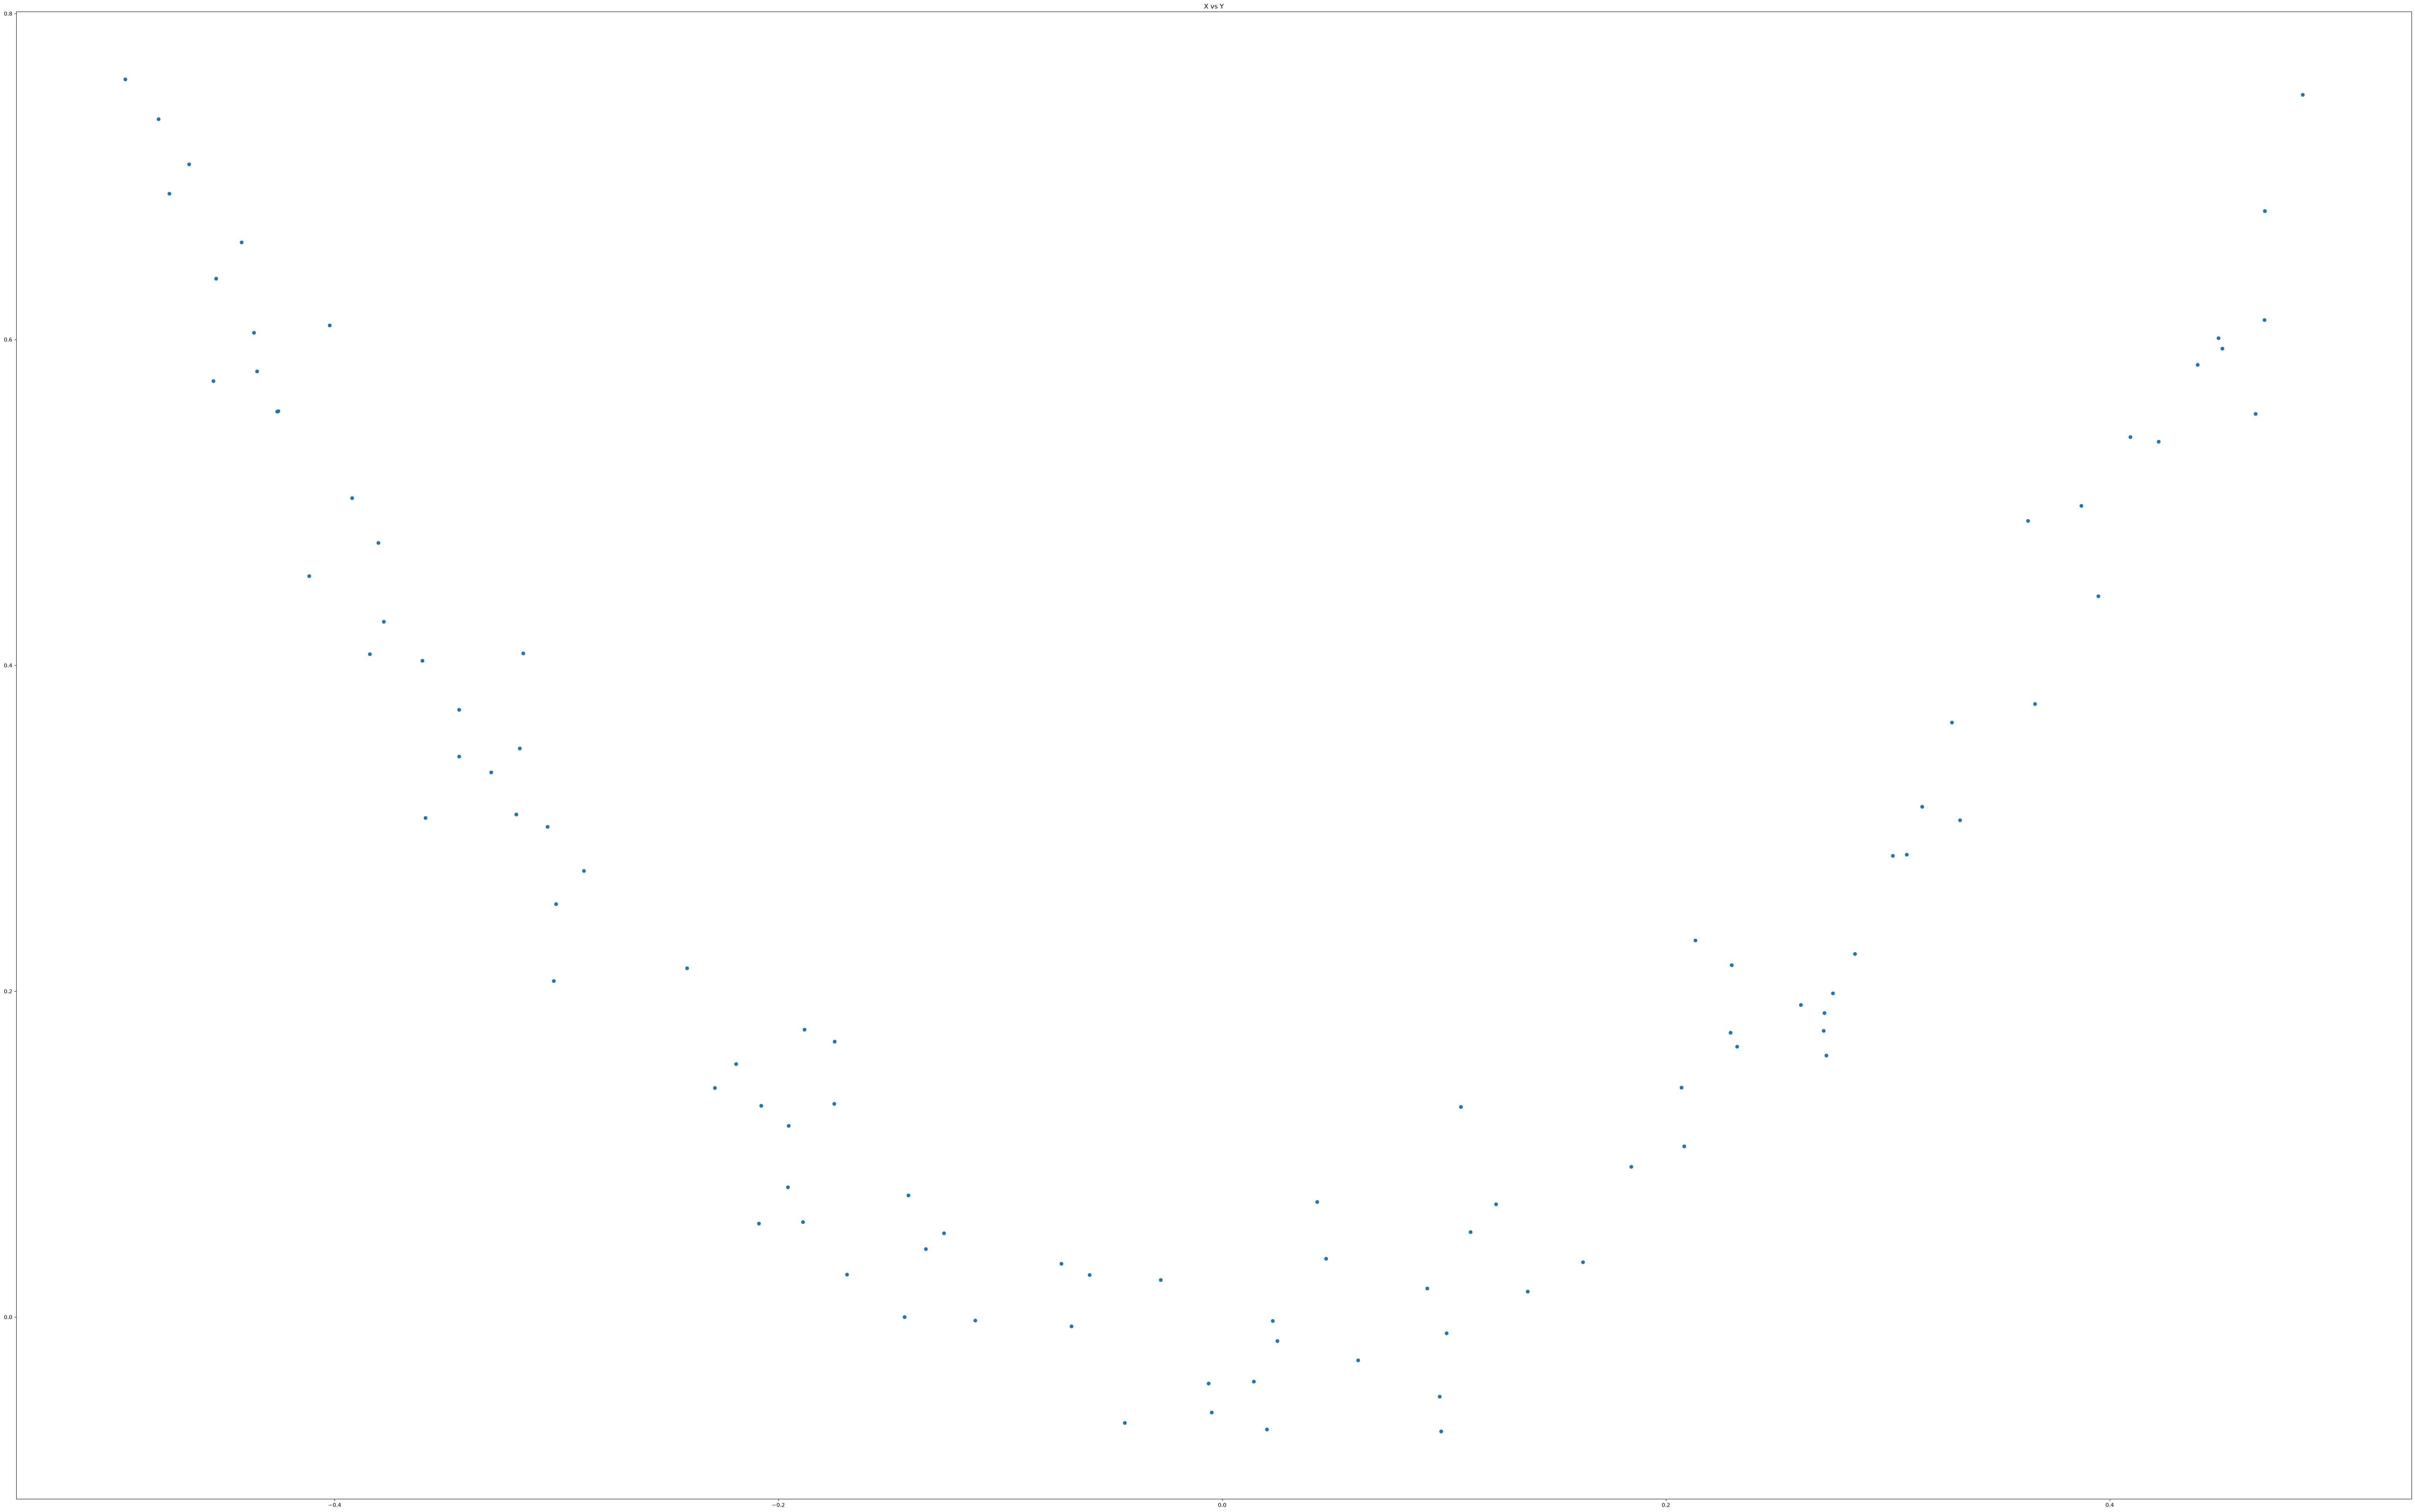

In [61]:
plt.scatter(df['X'],df['y'])
plt.title('X vs Y')

In [62]:
df['pred1'] = df['y'].mean()
df['res1'] = df['y'] - df['pred1']
df.head()

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528


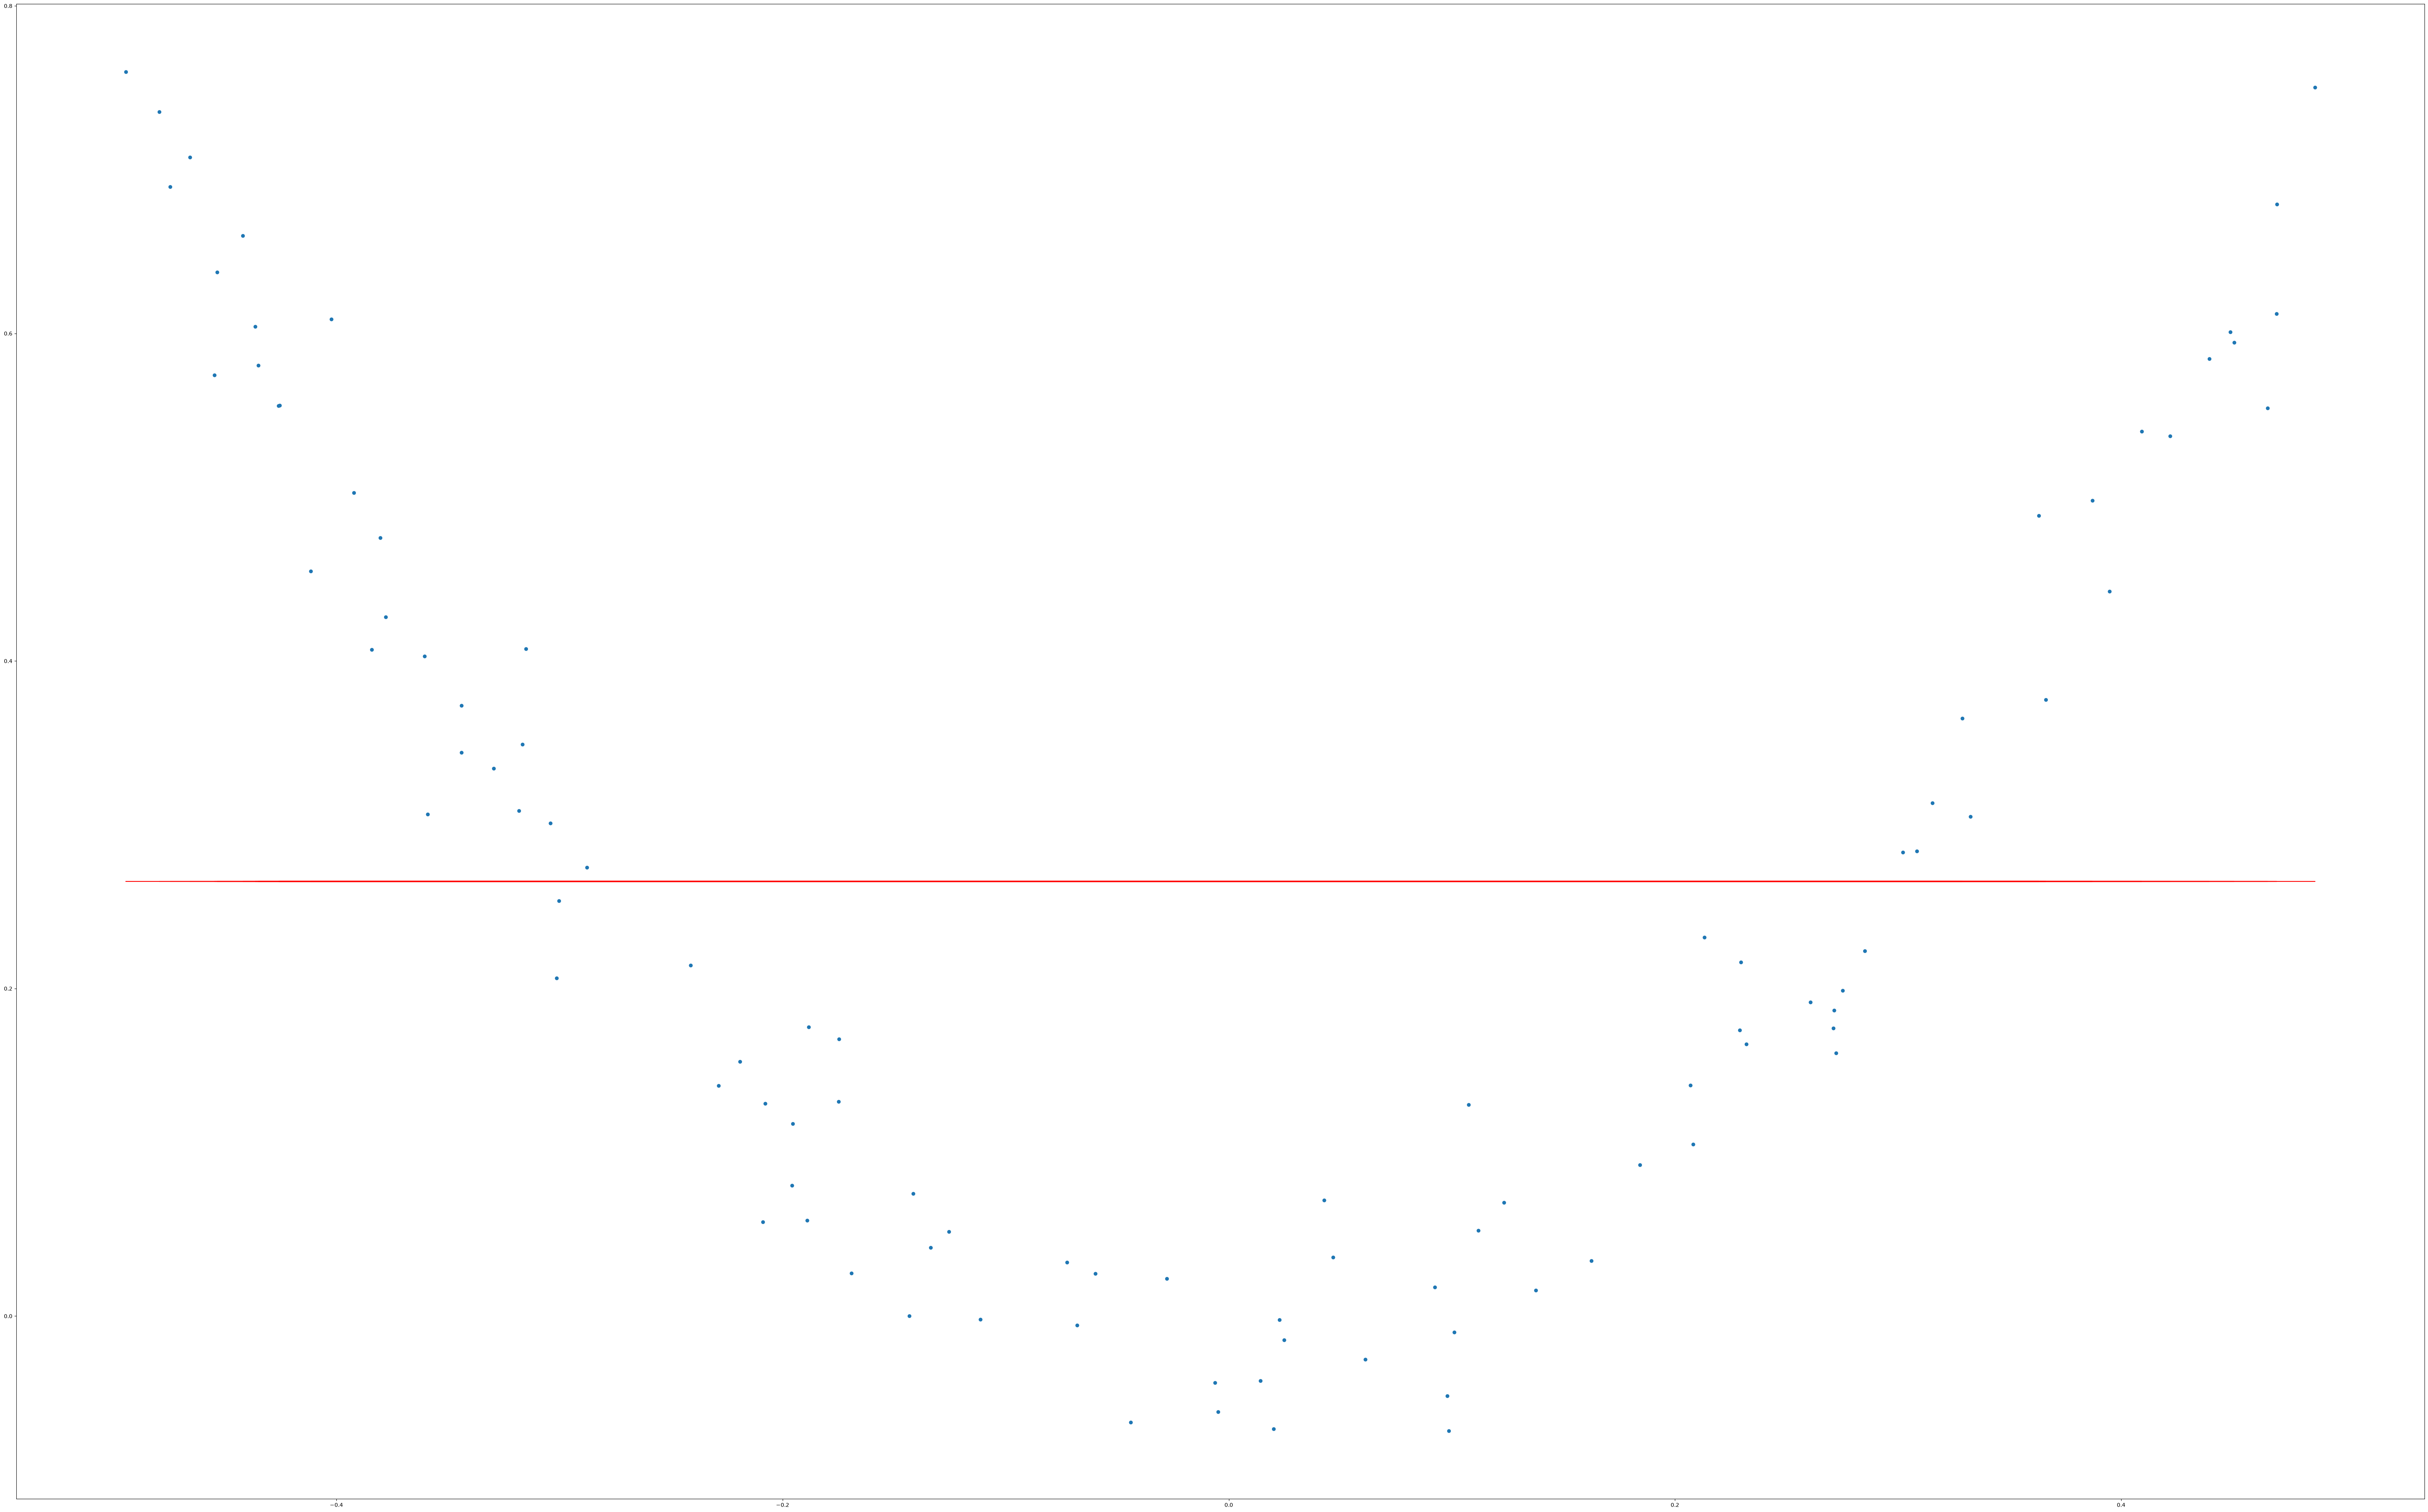

In [63]:
plt.scatter(df['X'],df['y'])
plt.plot(df['X'],df['pred1'],color='red')

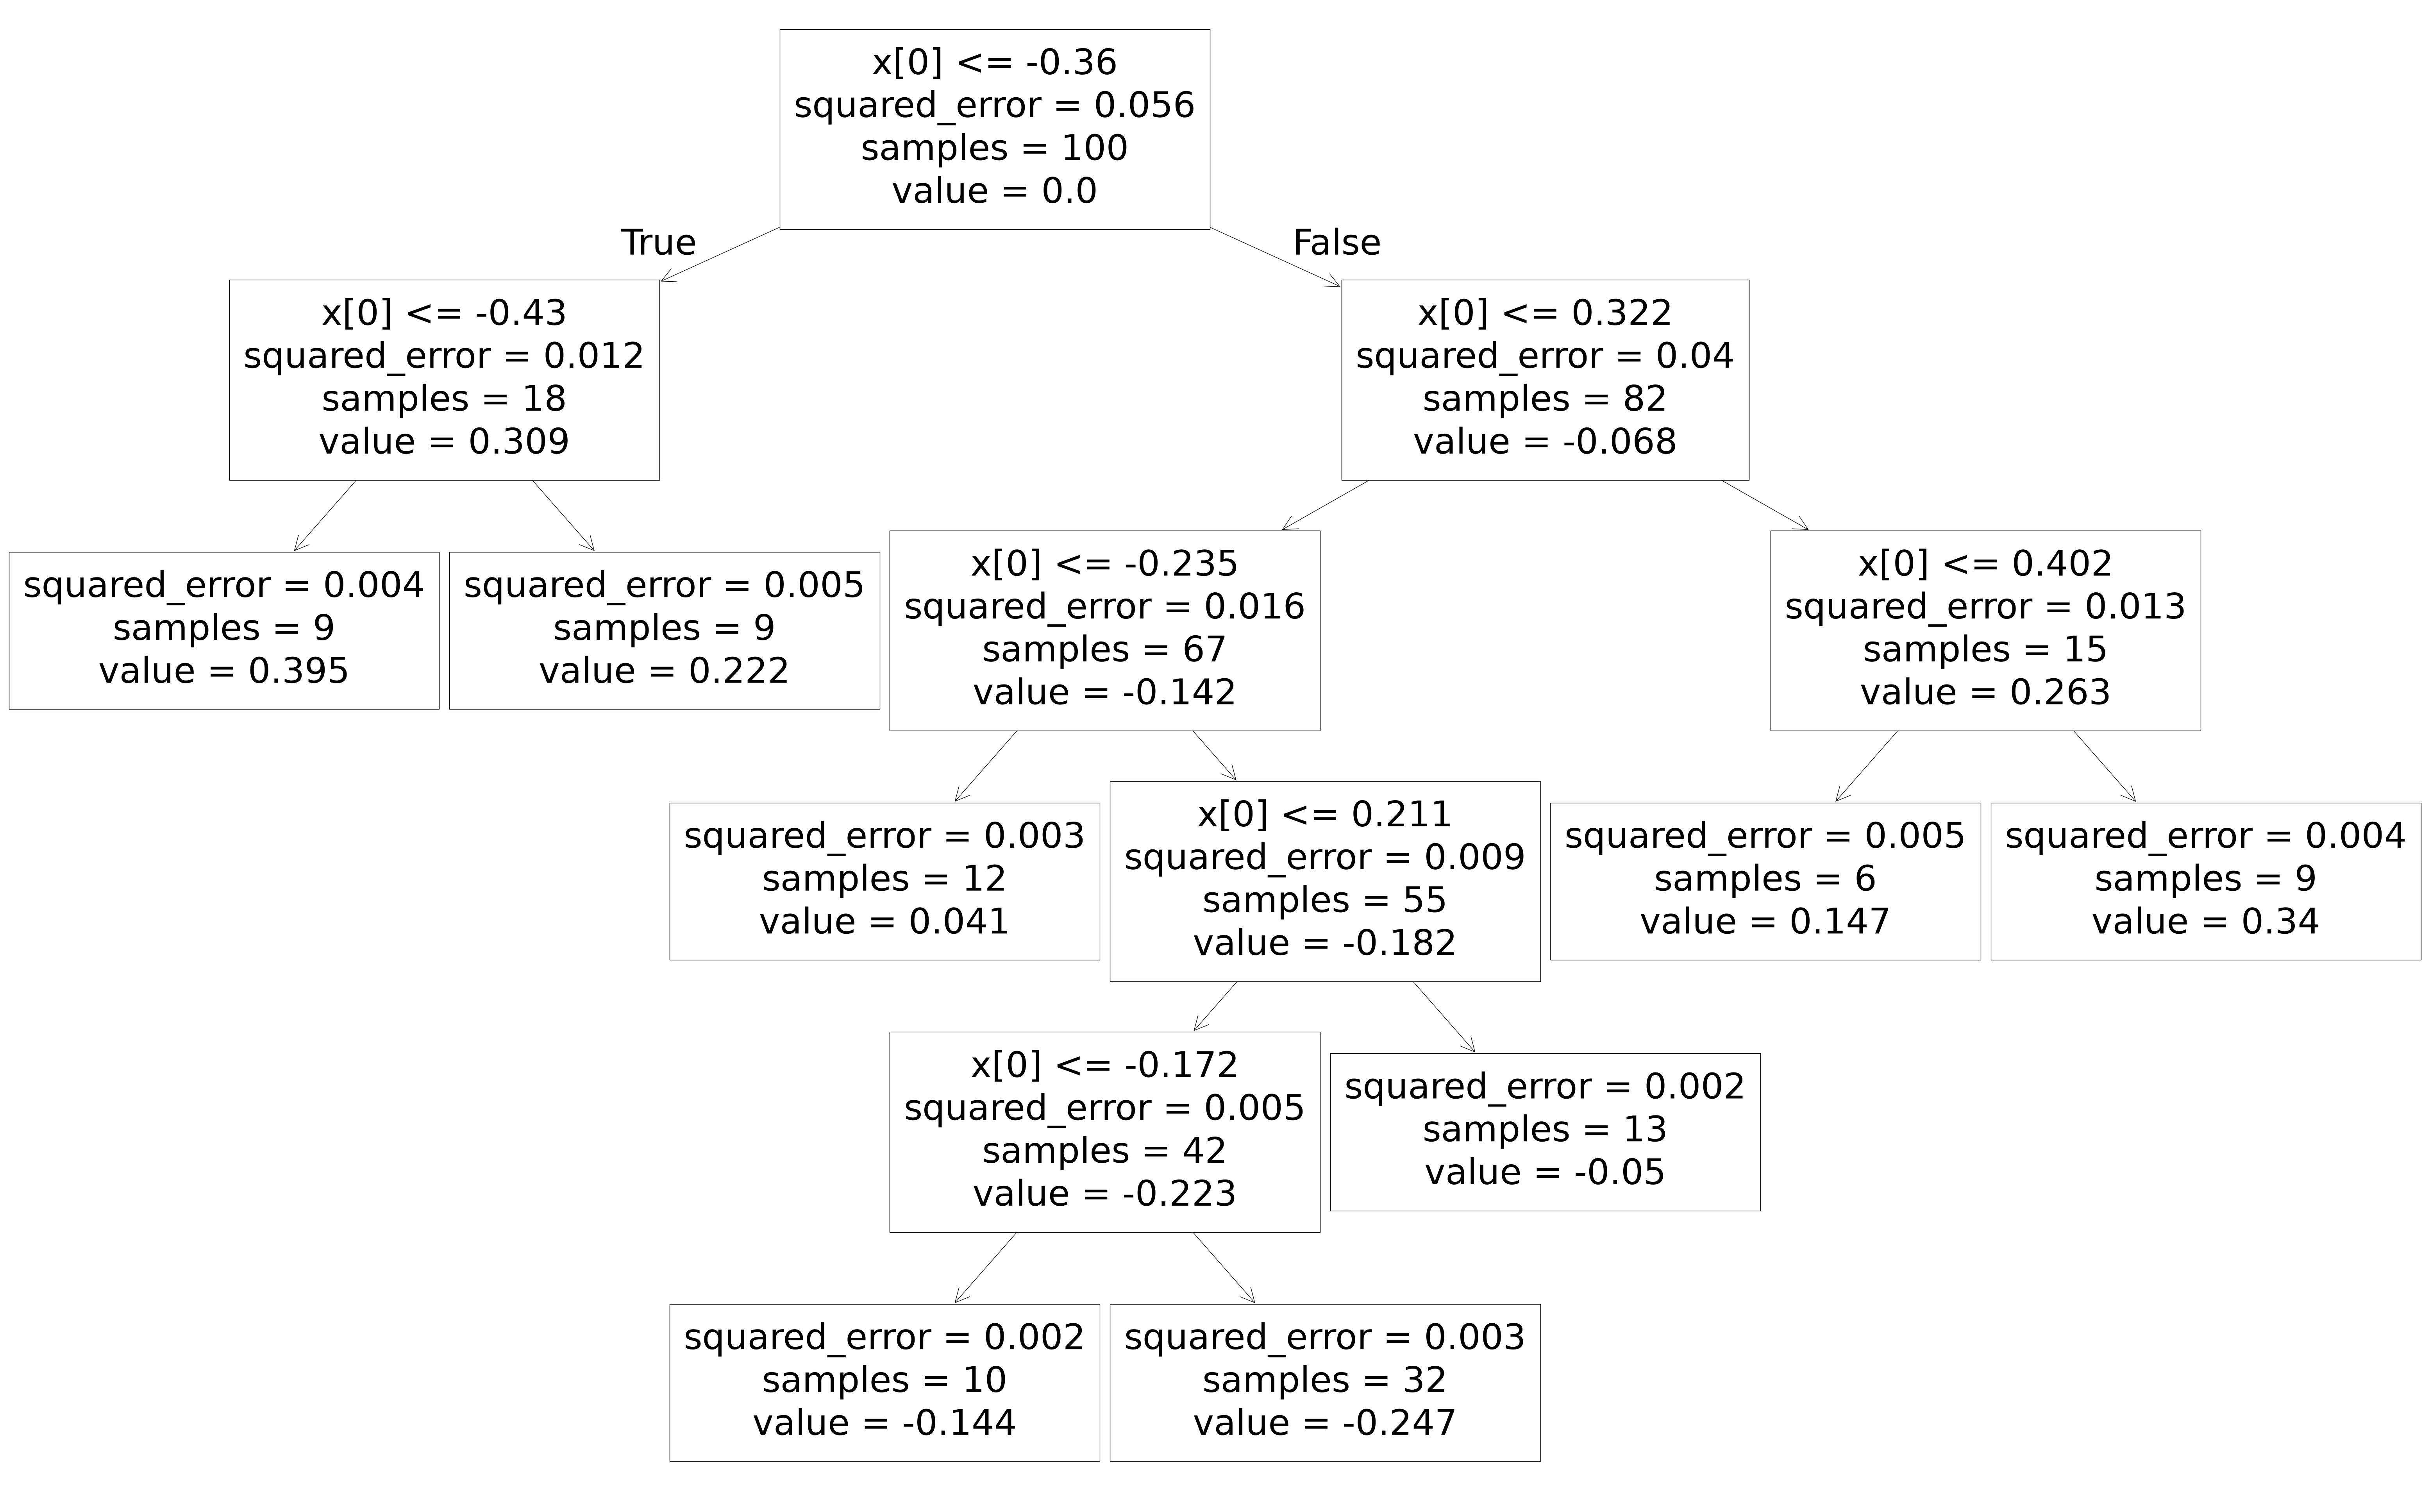

In [64]:
tree1 = DecisionTreeRegressor(max_leaf_nodes=8)
tree1.fit(df['X'].values.reshape(100,1),df['res1'].values)

plot_tree(tree1)
plt.show()

In [65]:
# generating X_test
X_test = np.linspace(-0.5, 0.5, 500)

y_pred = 0.265458 + tree1.predict(X_test.reshape(500, 1))

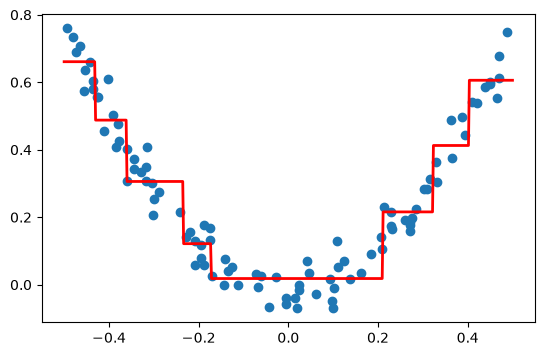

In [66]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])

In [67]:
df['pred2'] = 0.265458 + tree1.predict(df['X'].values.reshape(100,1))
df['res2'] = df['y'] - df['pred2']

df.head()

,X,y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,0.018319,0.033254
1,0.450714,0.594480,0.265458,0.329021,0.605884,-0.011404
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,0.018319,-0.088497
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022


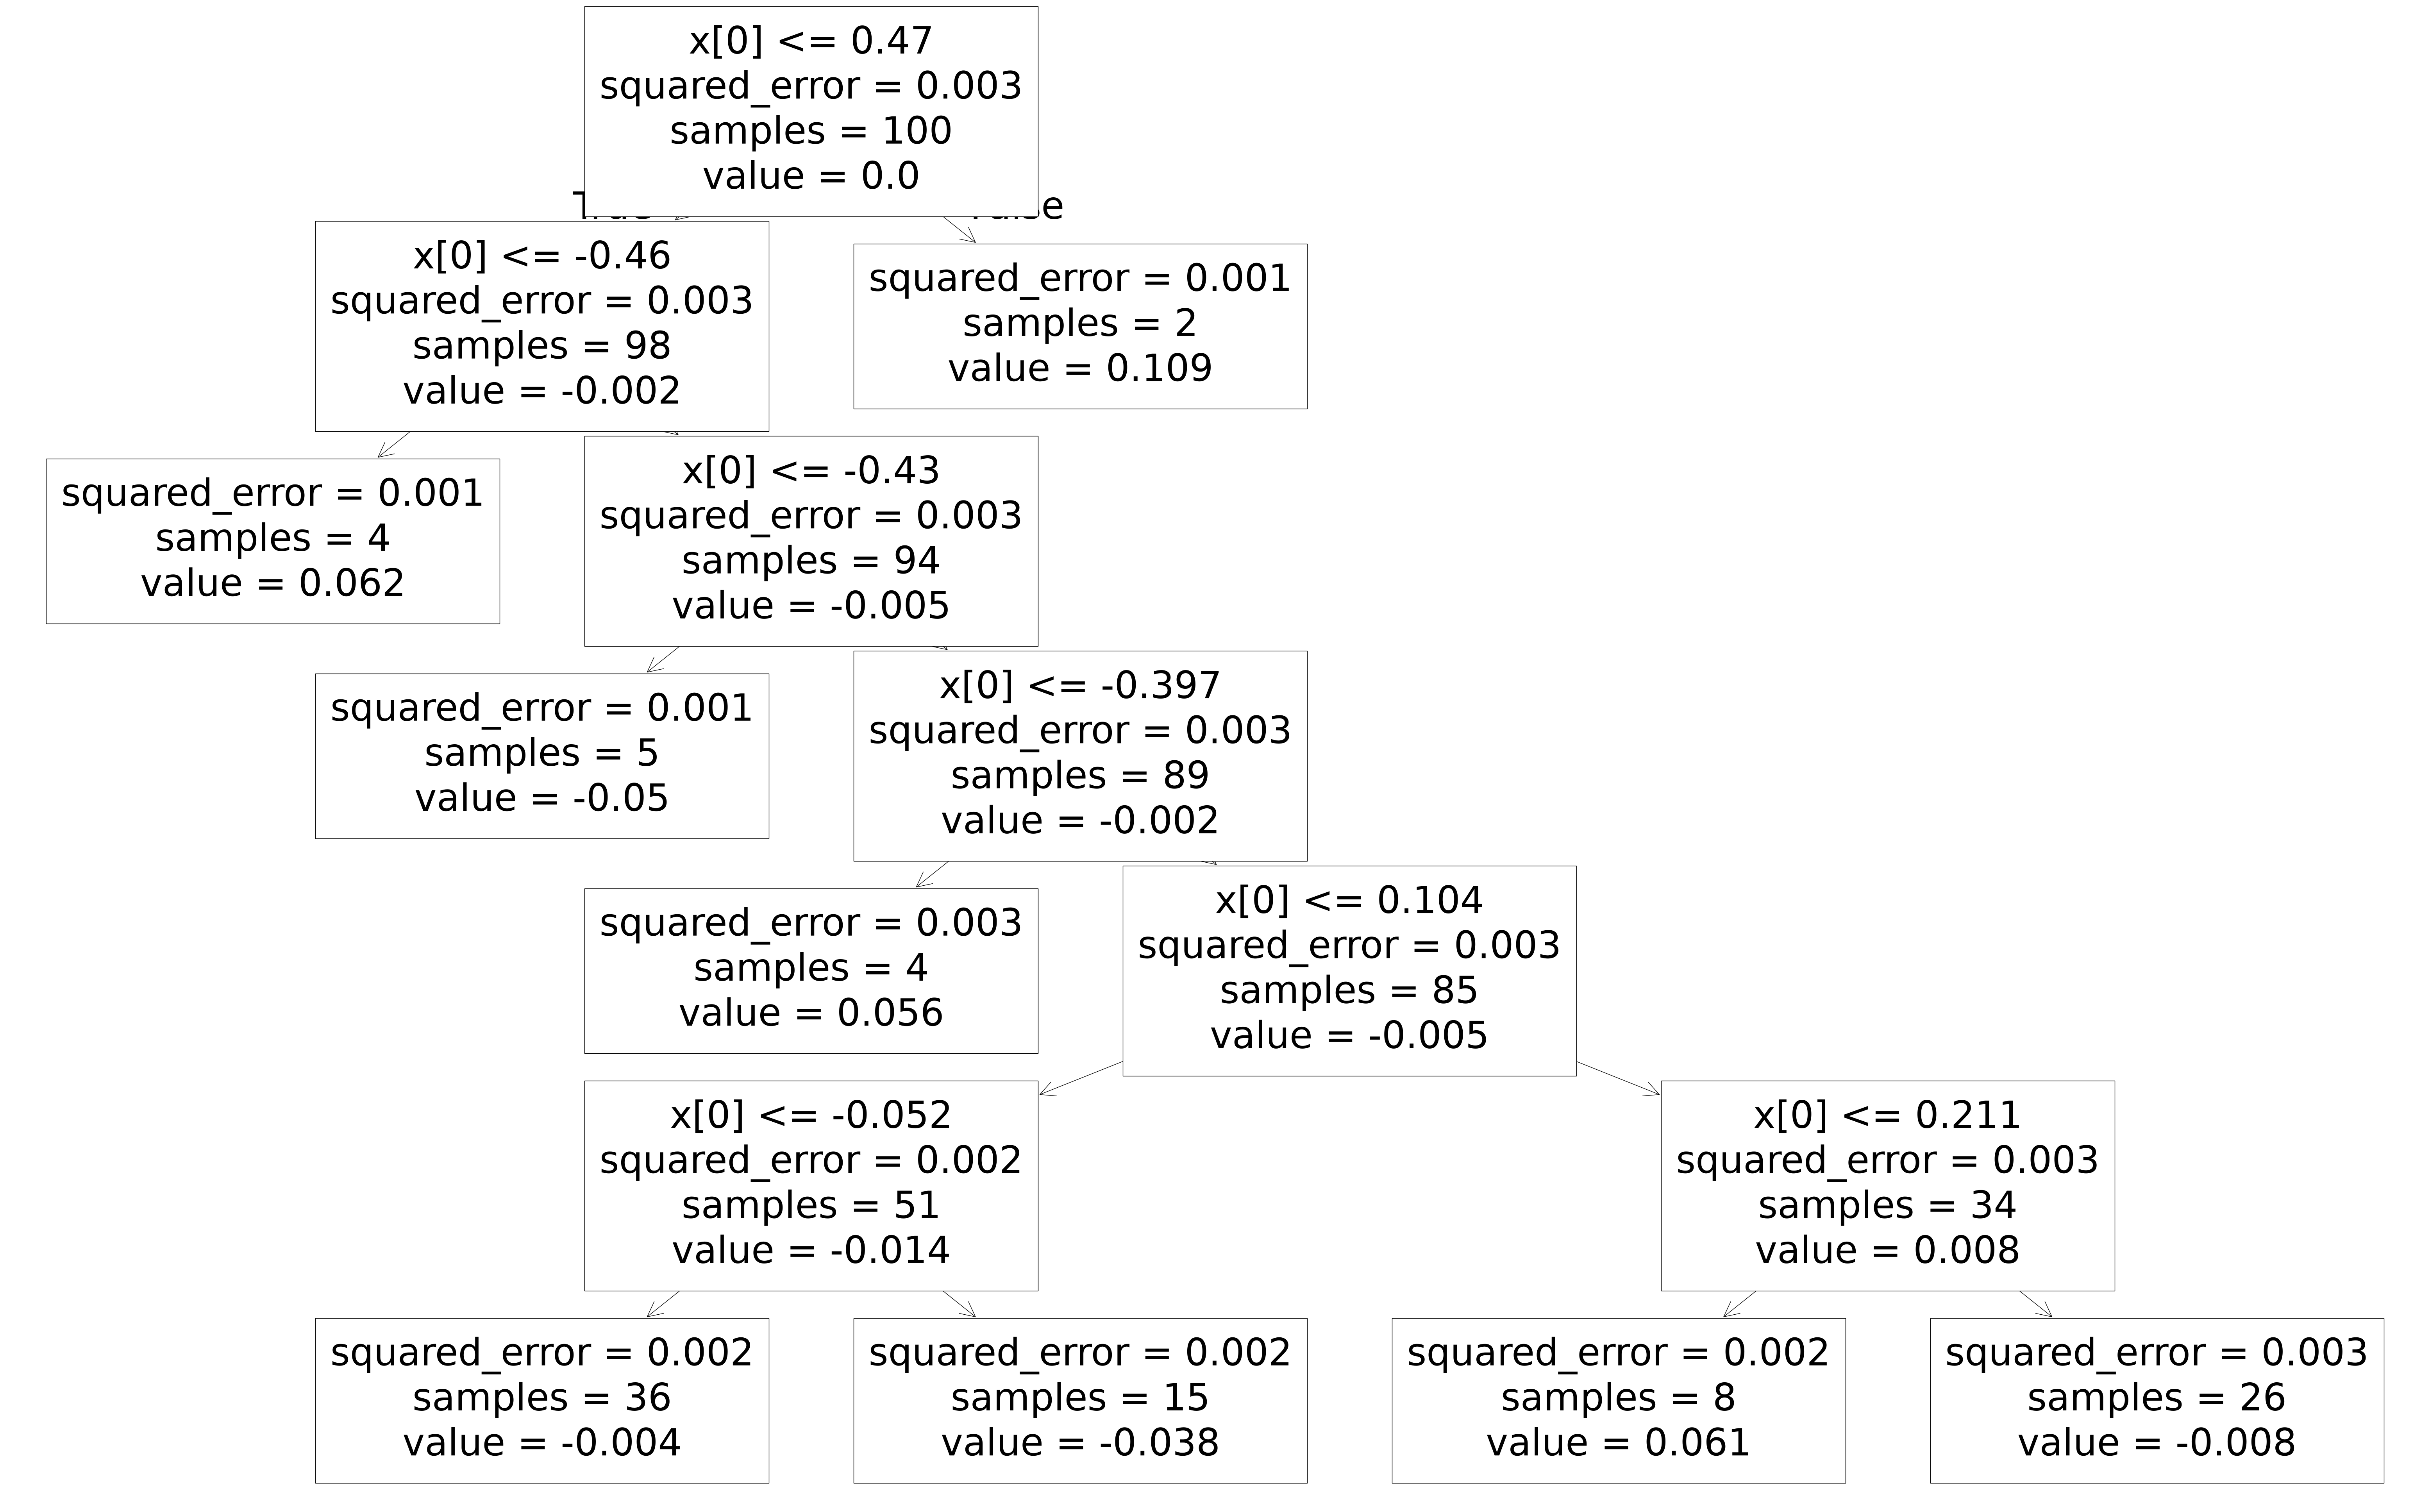

In [68]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=8)
tree2.fit(df['X'].values.reshape(100,1),df['res2'].values)

plot_tree(tree2)
plt.show()

In [69]:
y_pred = 0.265458 + sum(regressor.predict(X_test.reshape(-1, 1)) for regressor in [tree1,tree2])

Text(0.5, 1.0, 'X vs y')

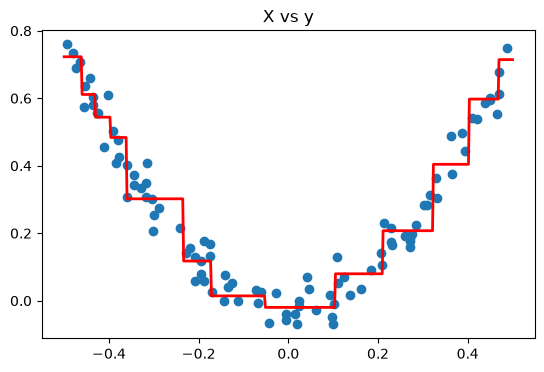

In [70]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])
plt.title('X vs y')

In [71]:
def gradient_boost(X,y,number,lr,count=1,regs=[],foo=None):

  if number == 0:
    return 
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)

5


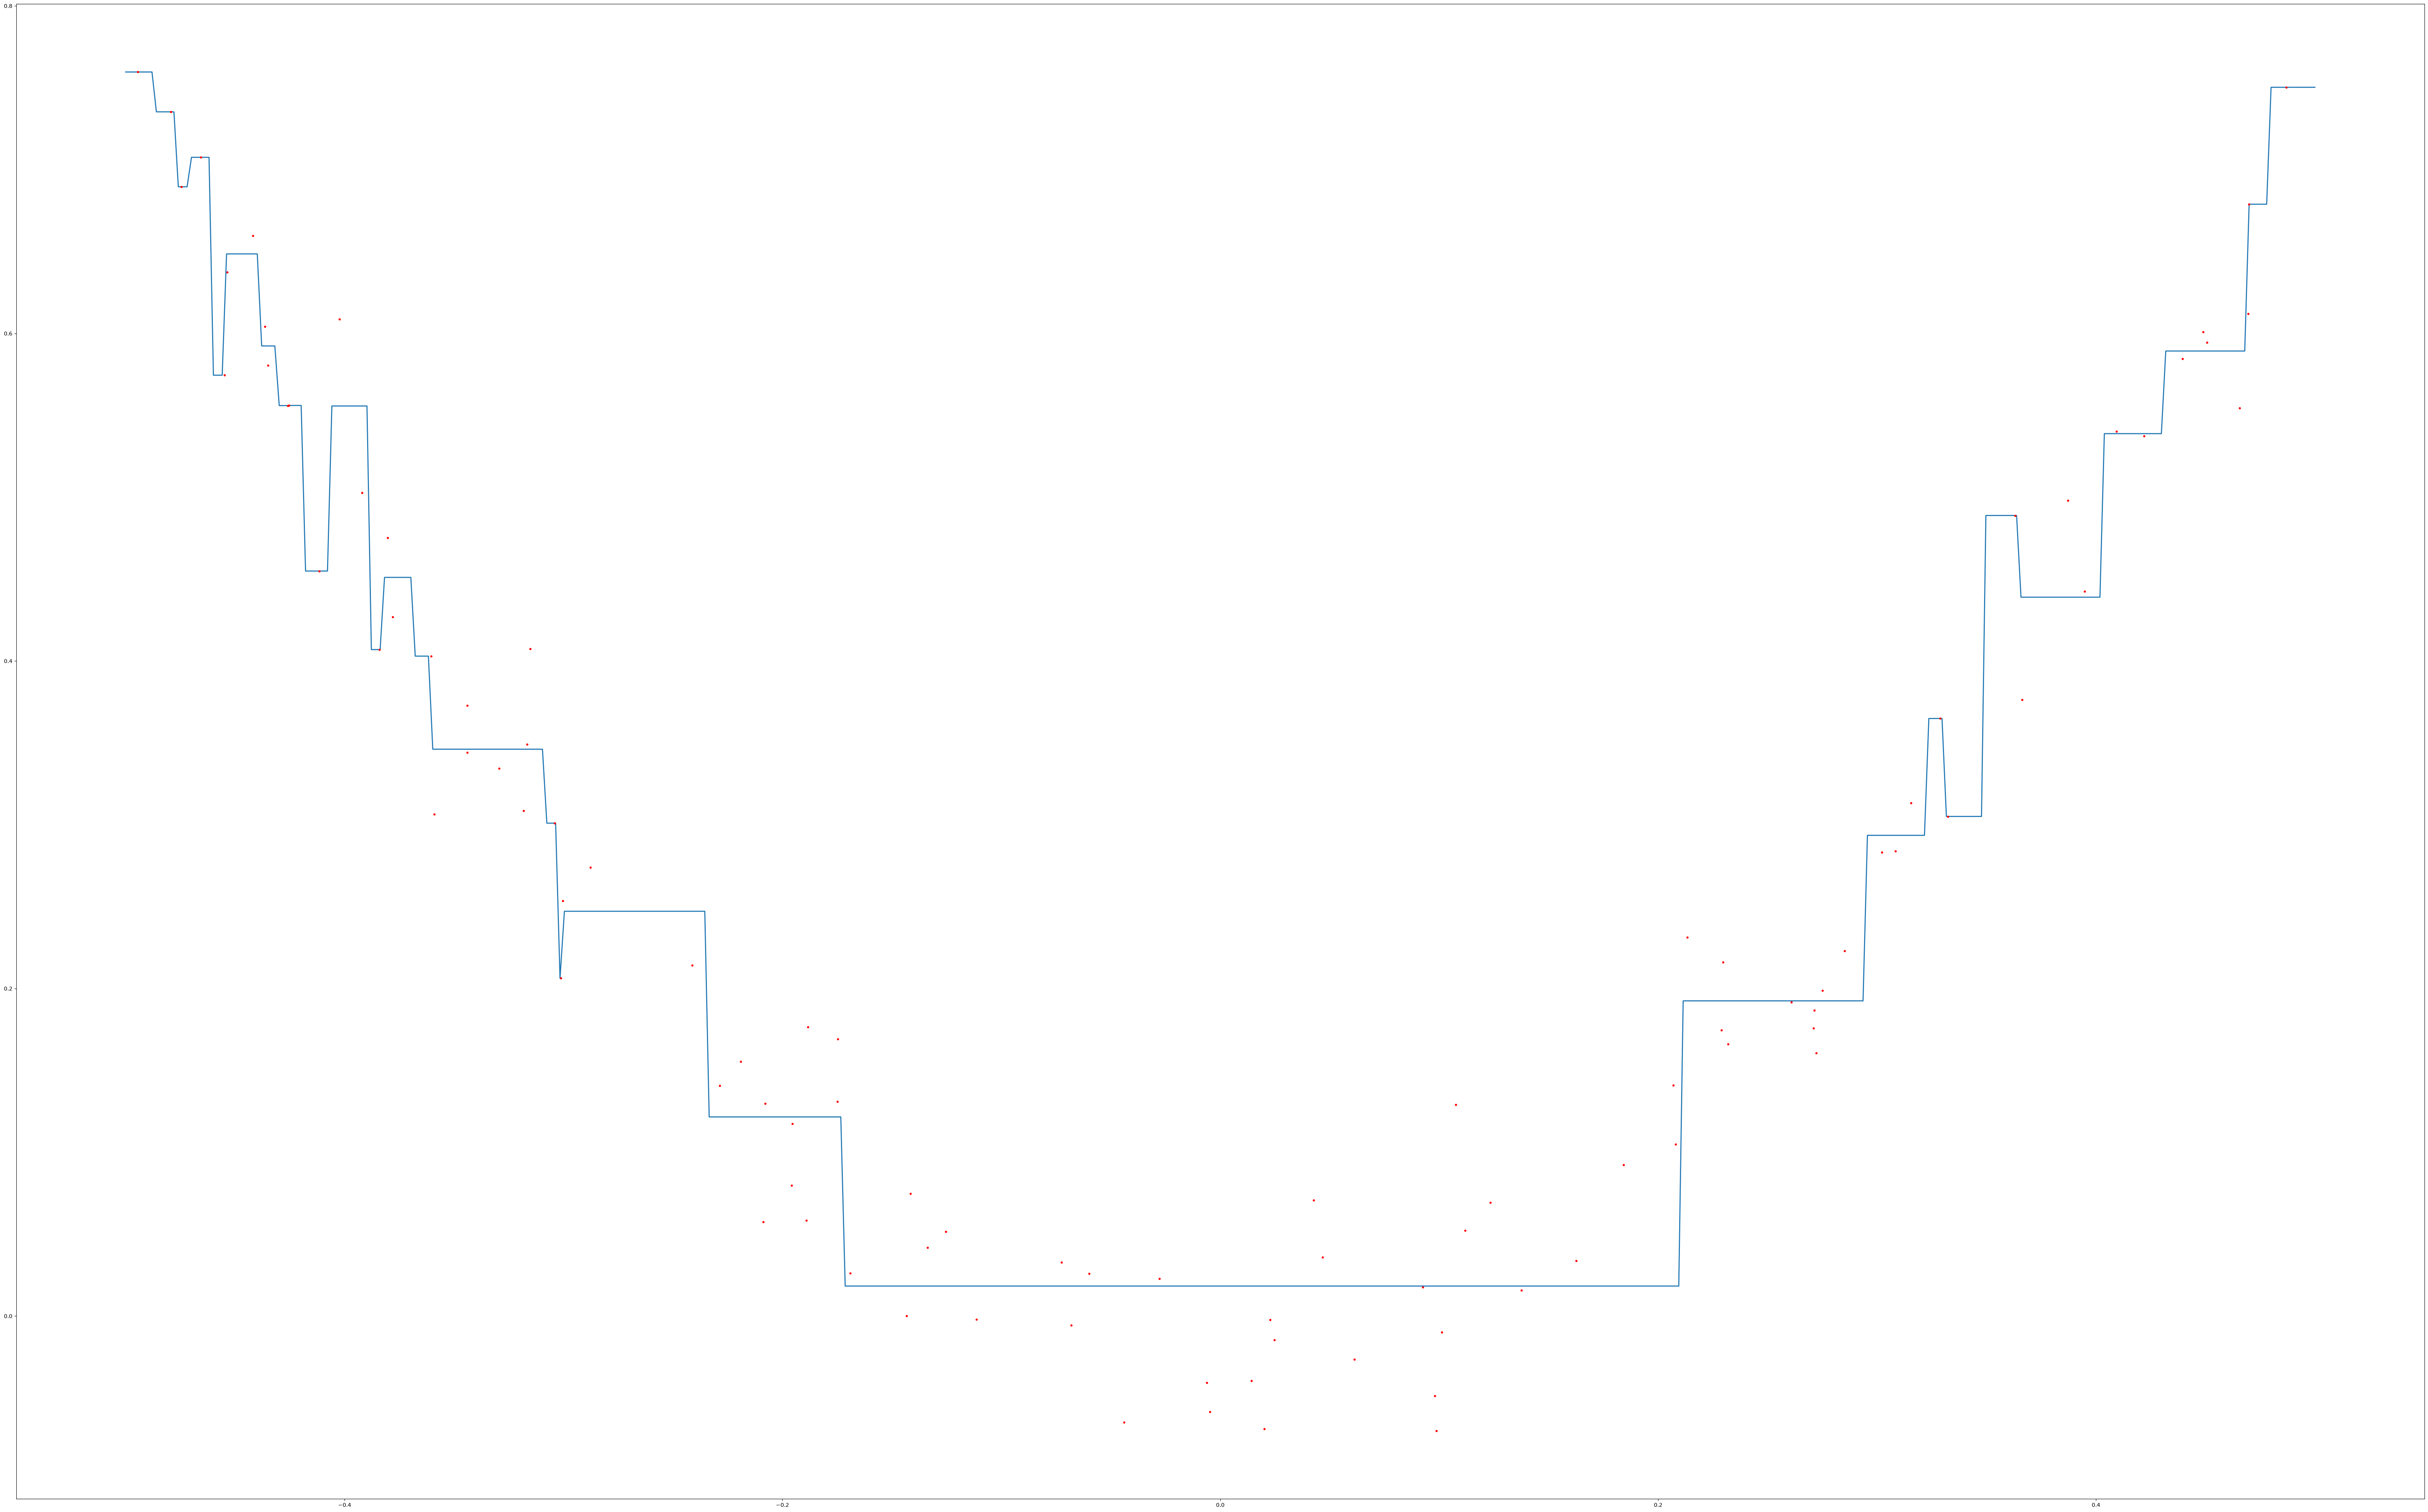

4


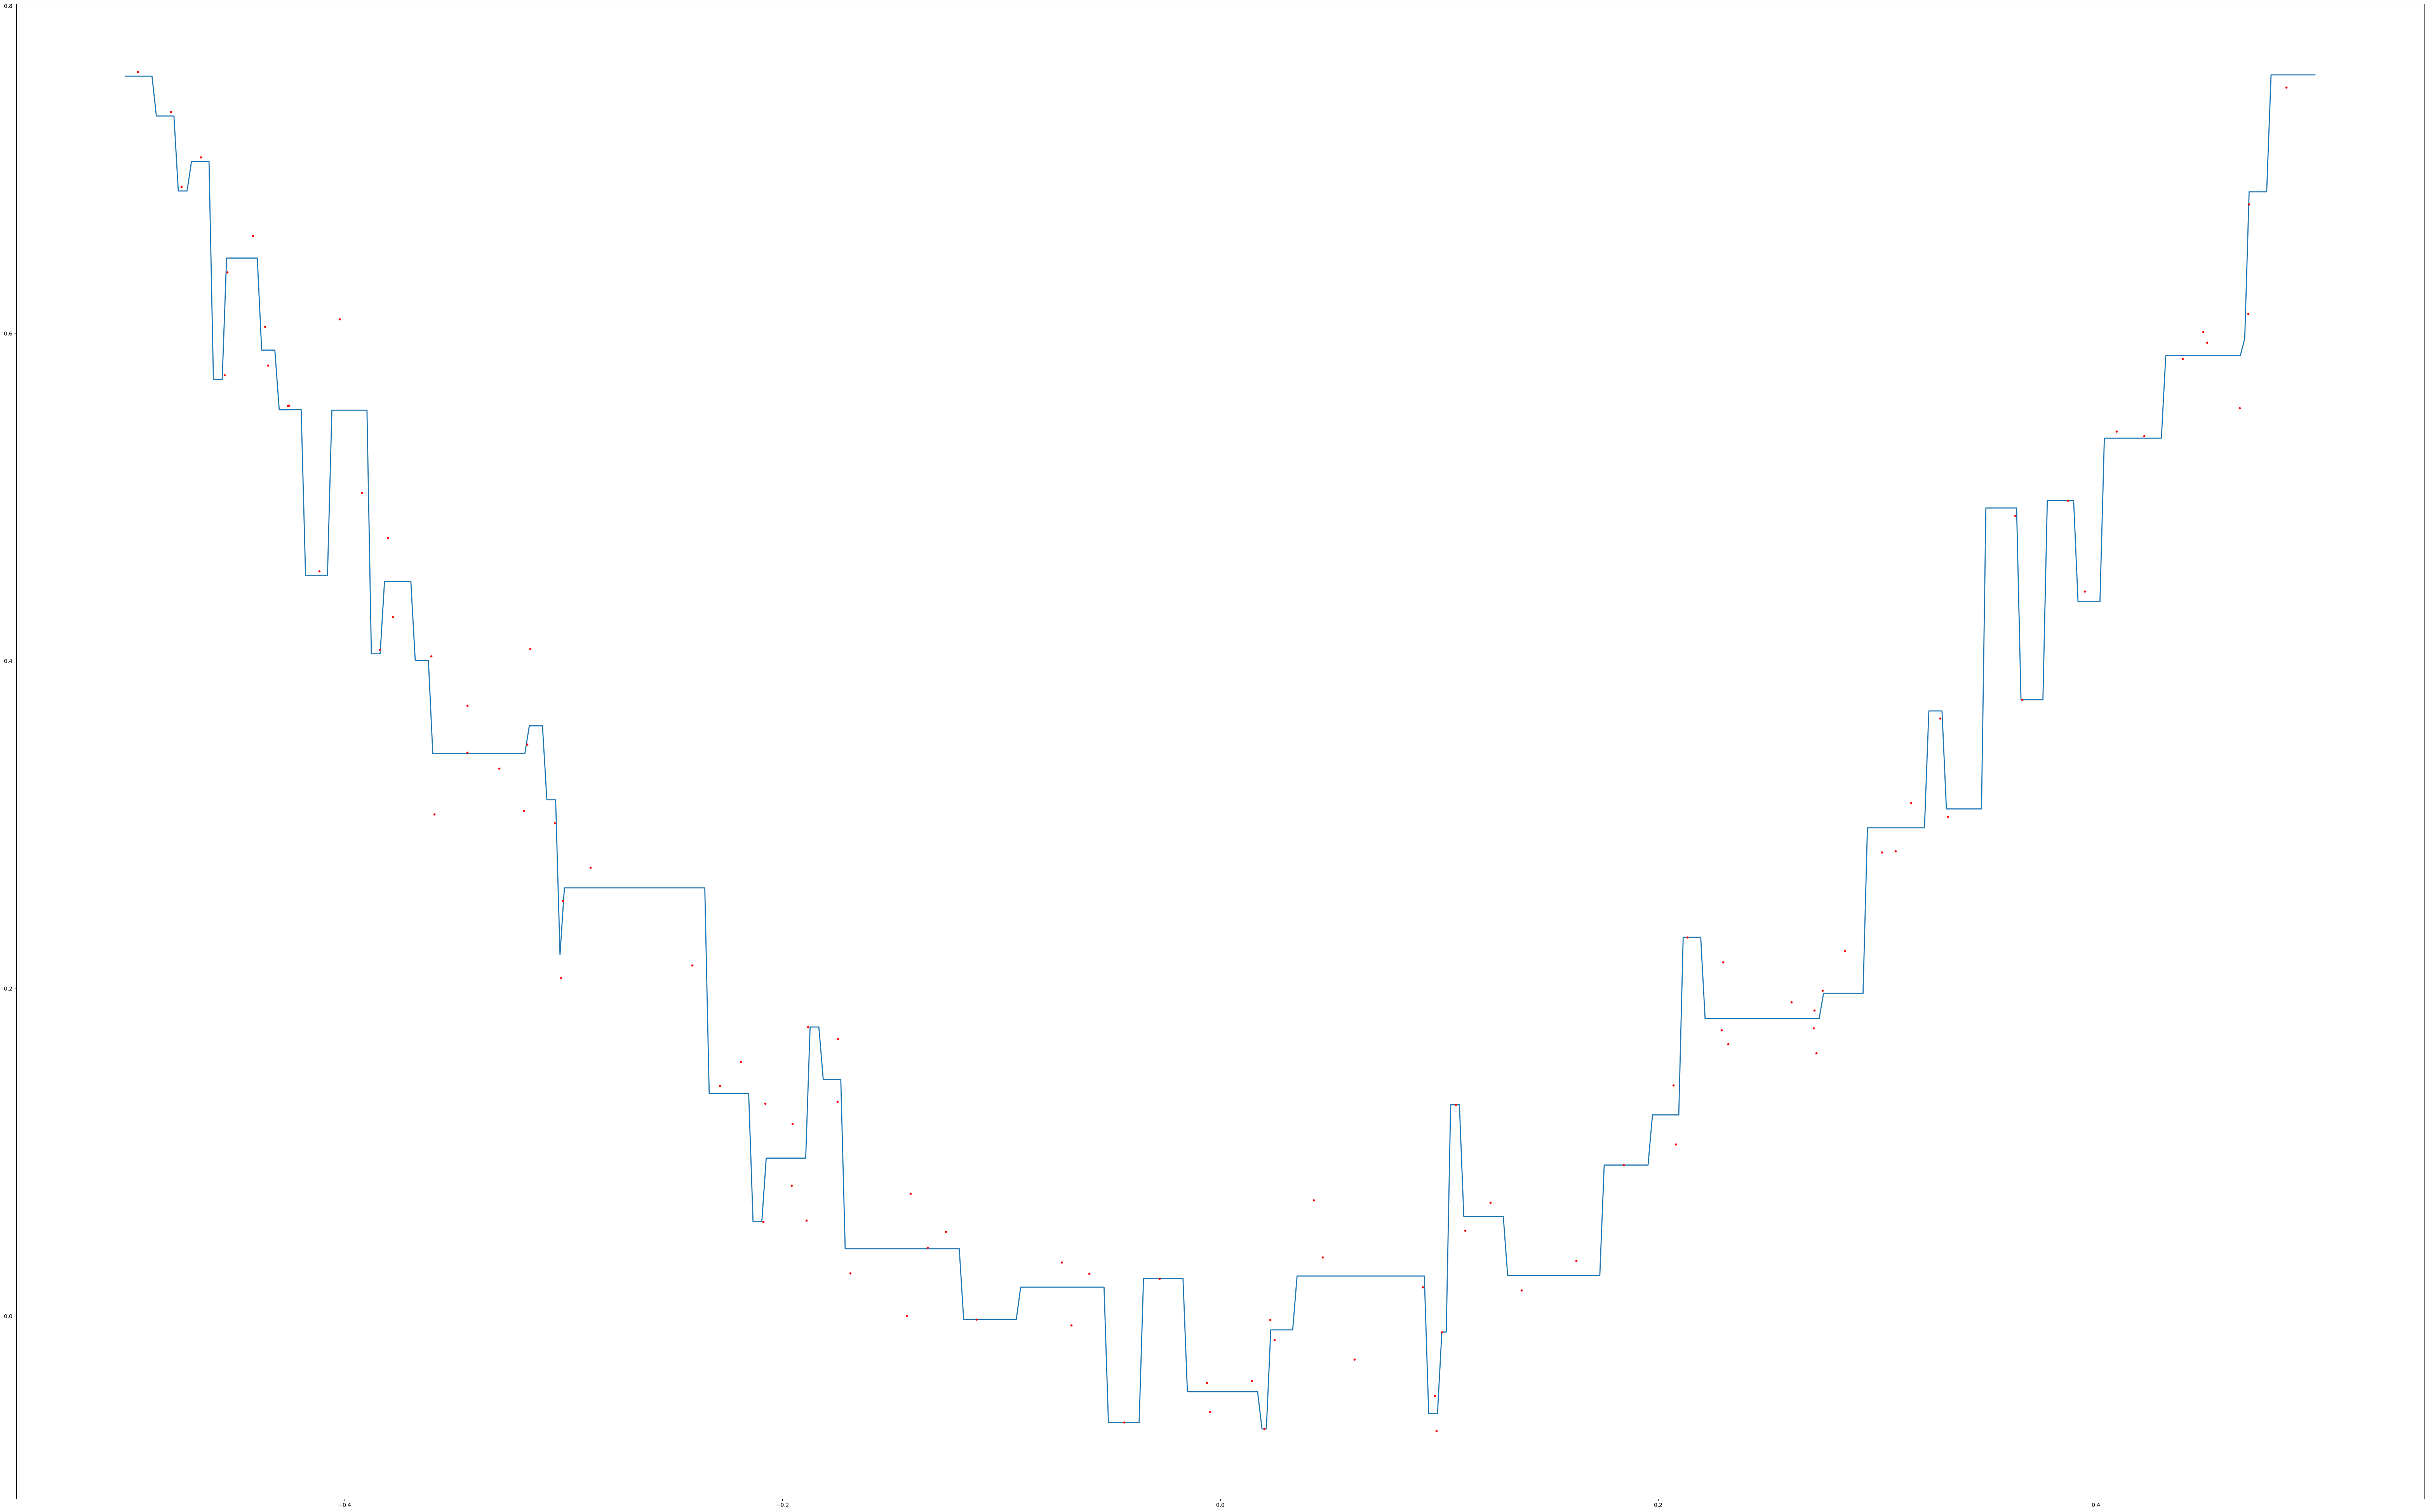

3


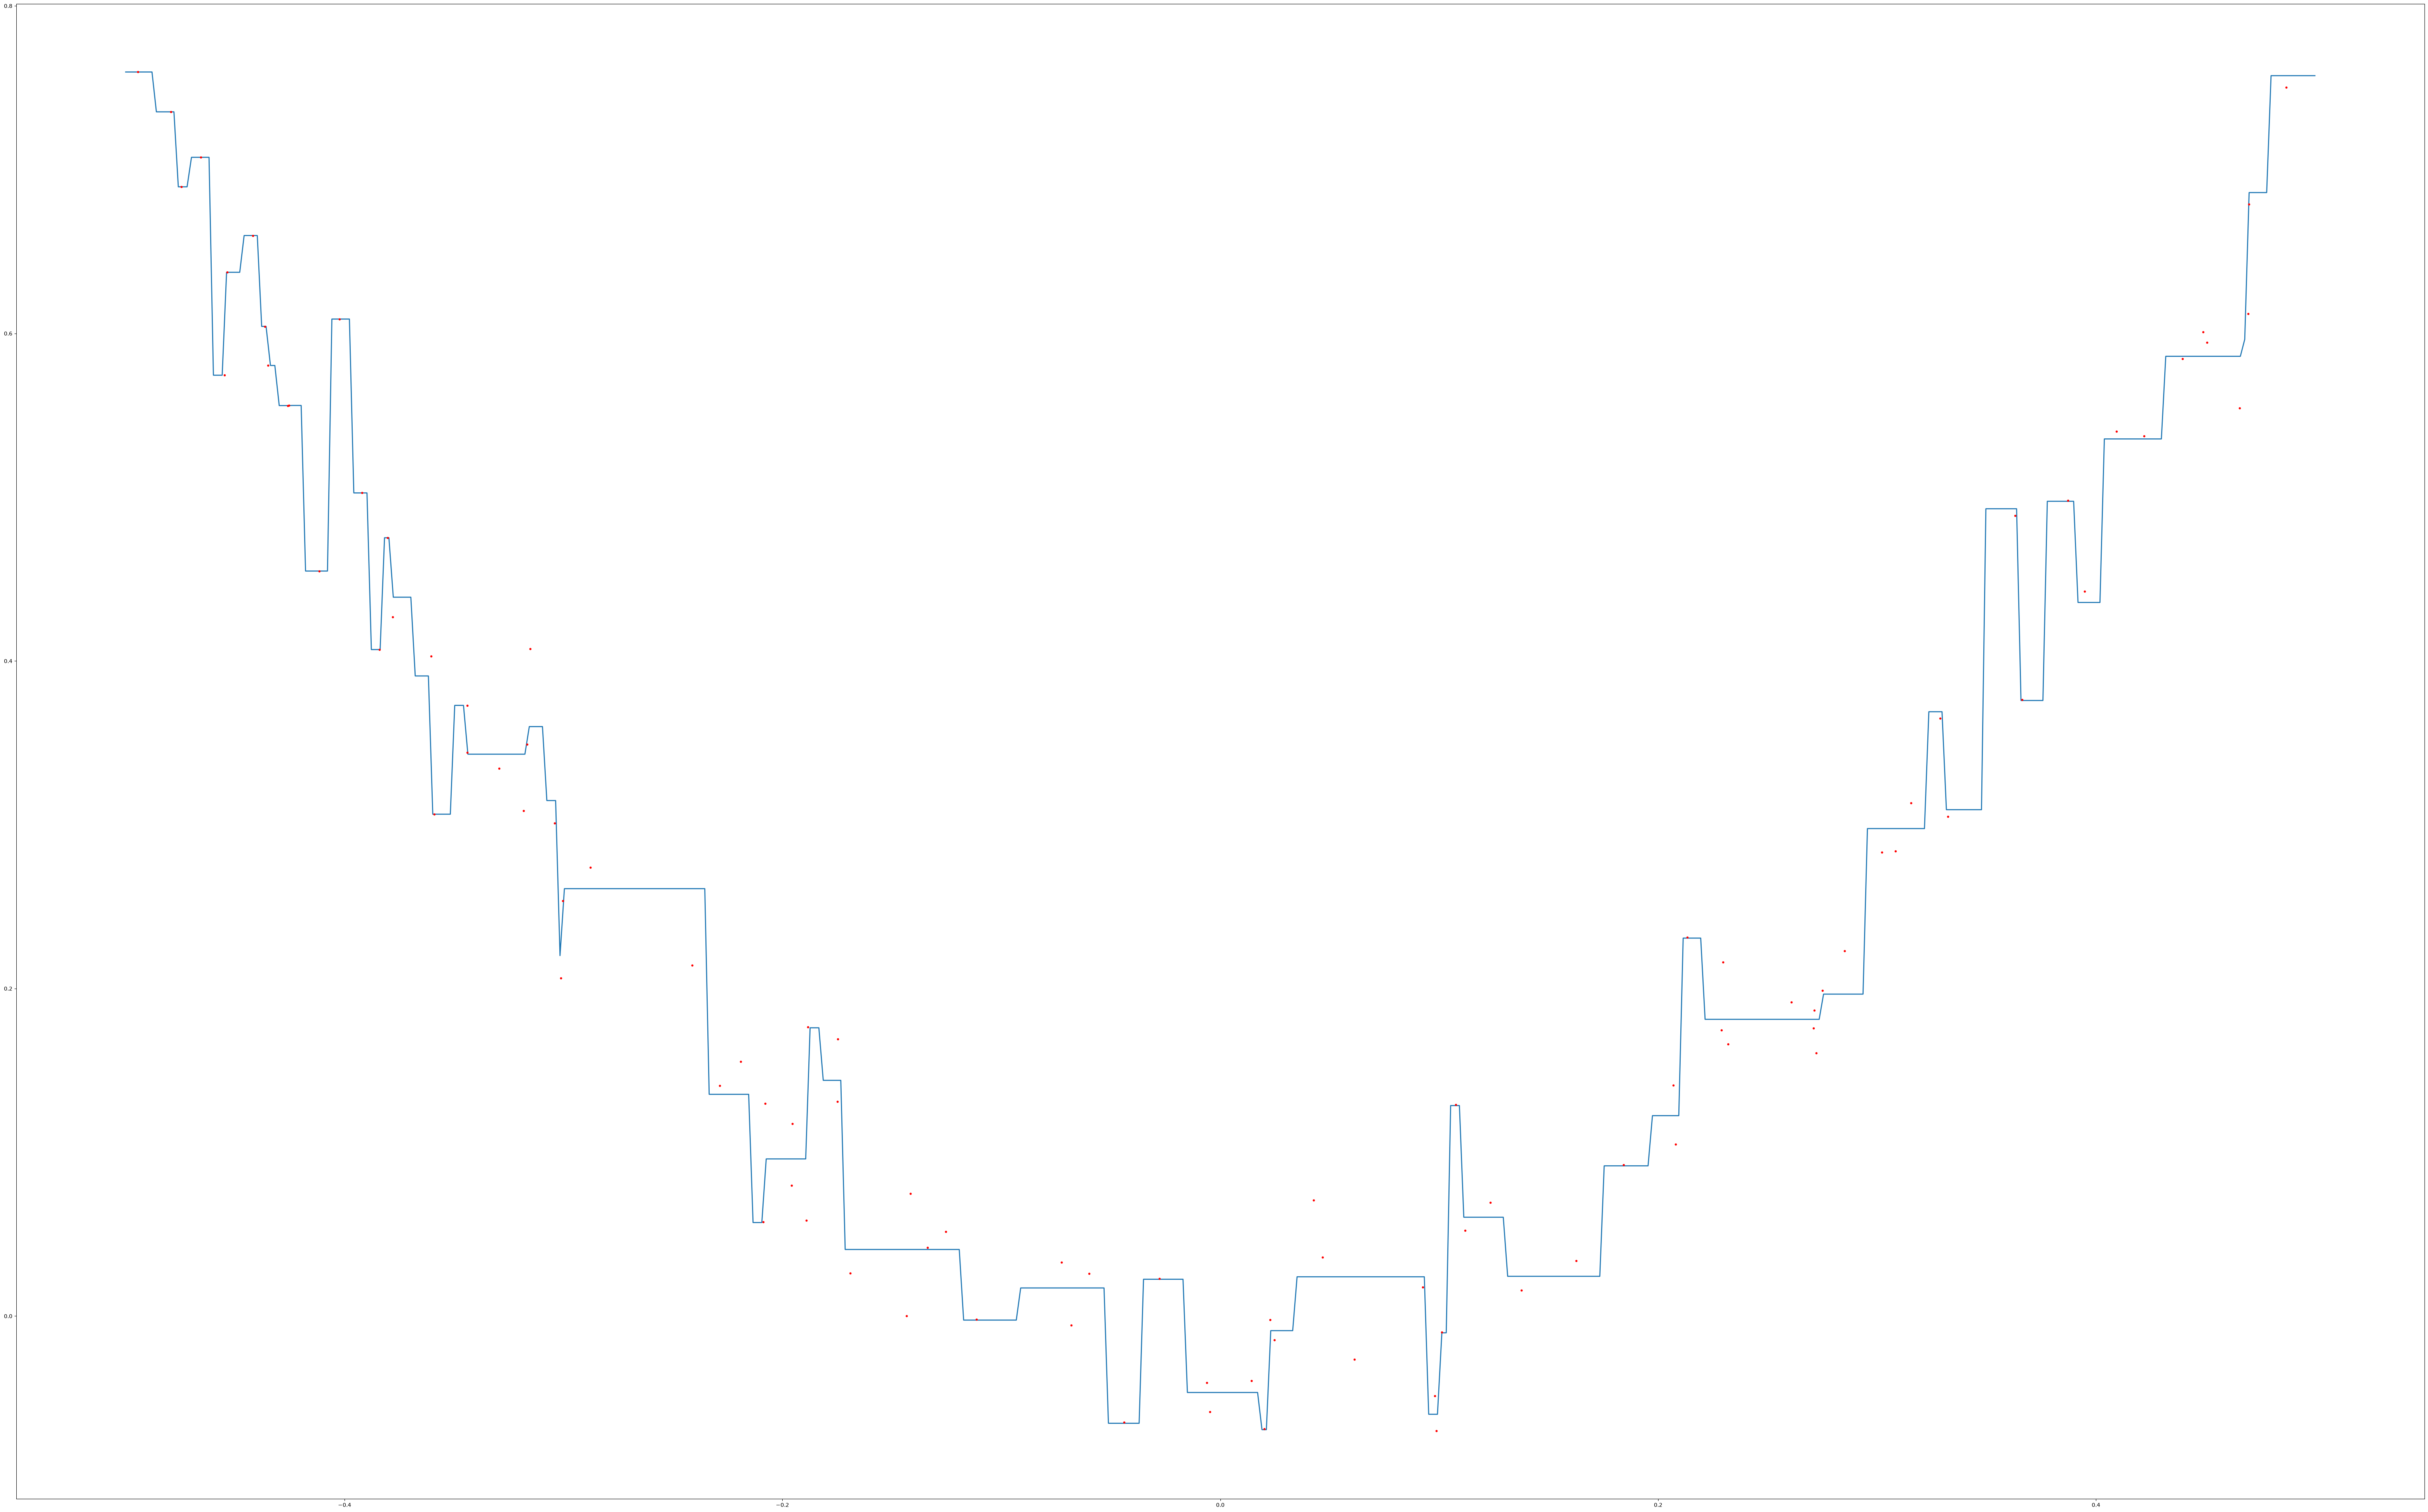

2


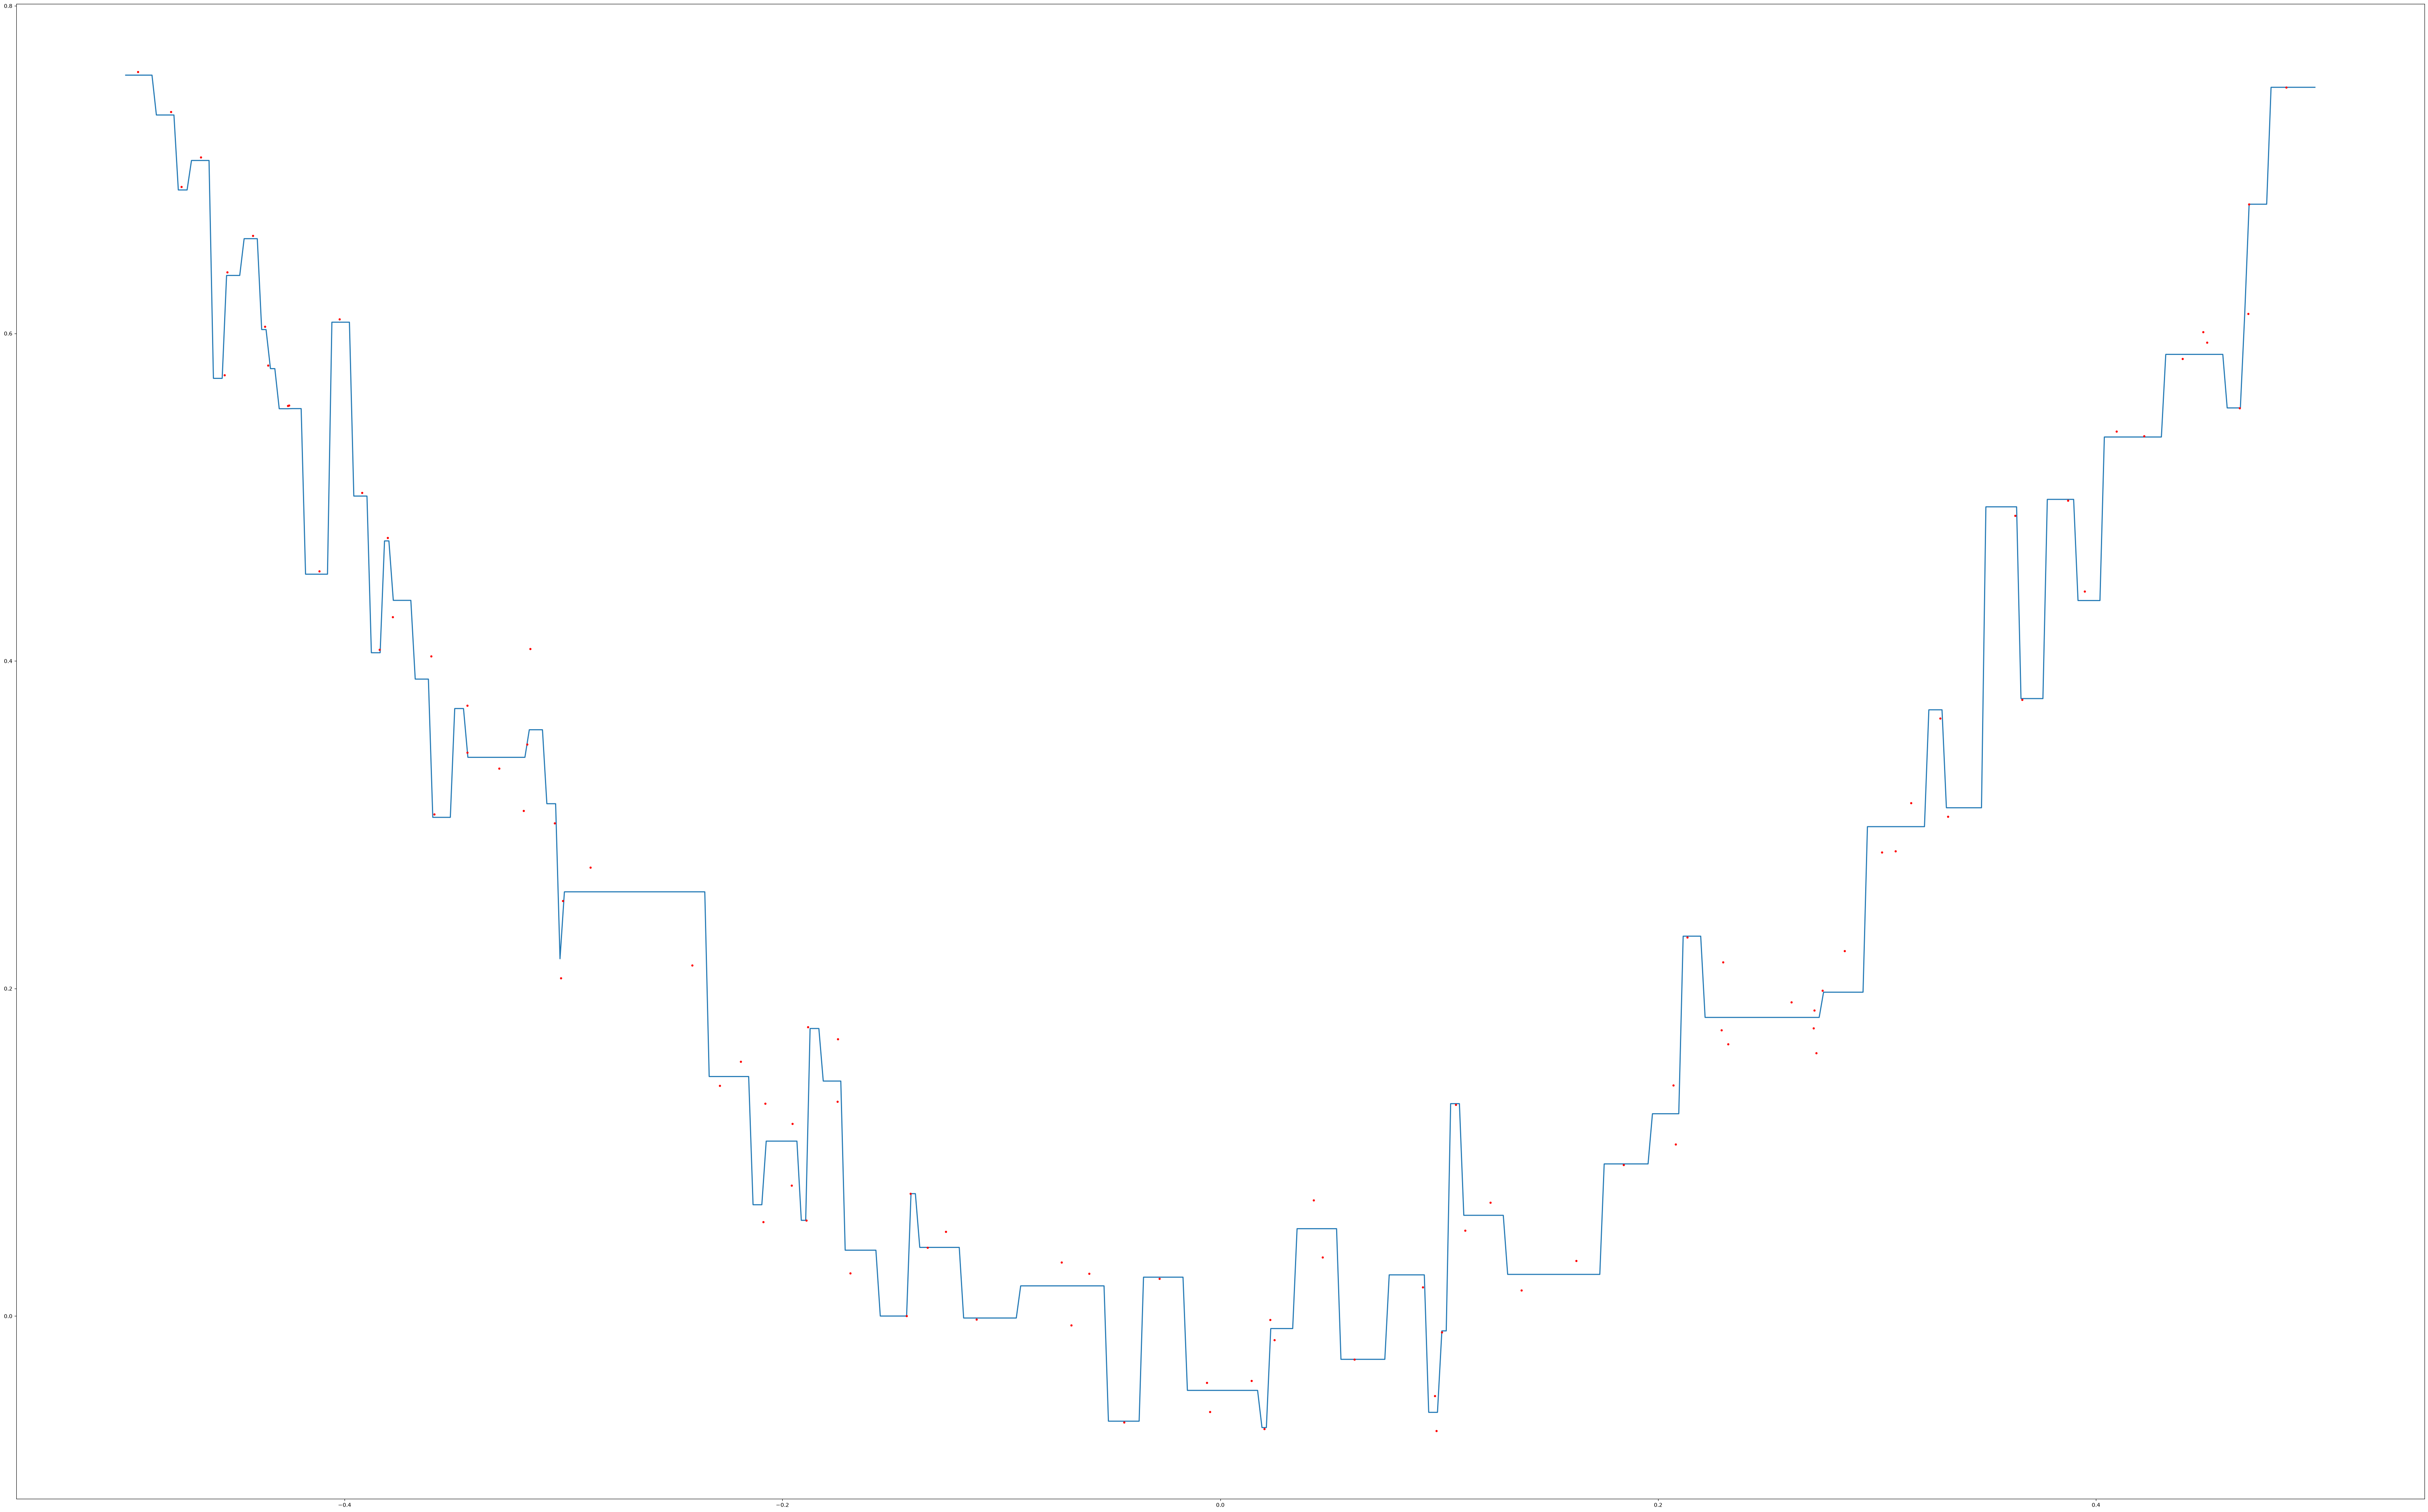

1


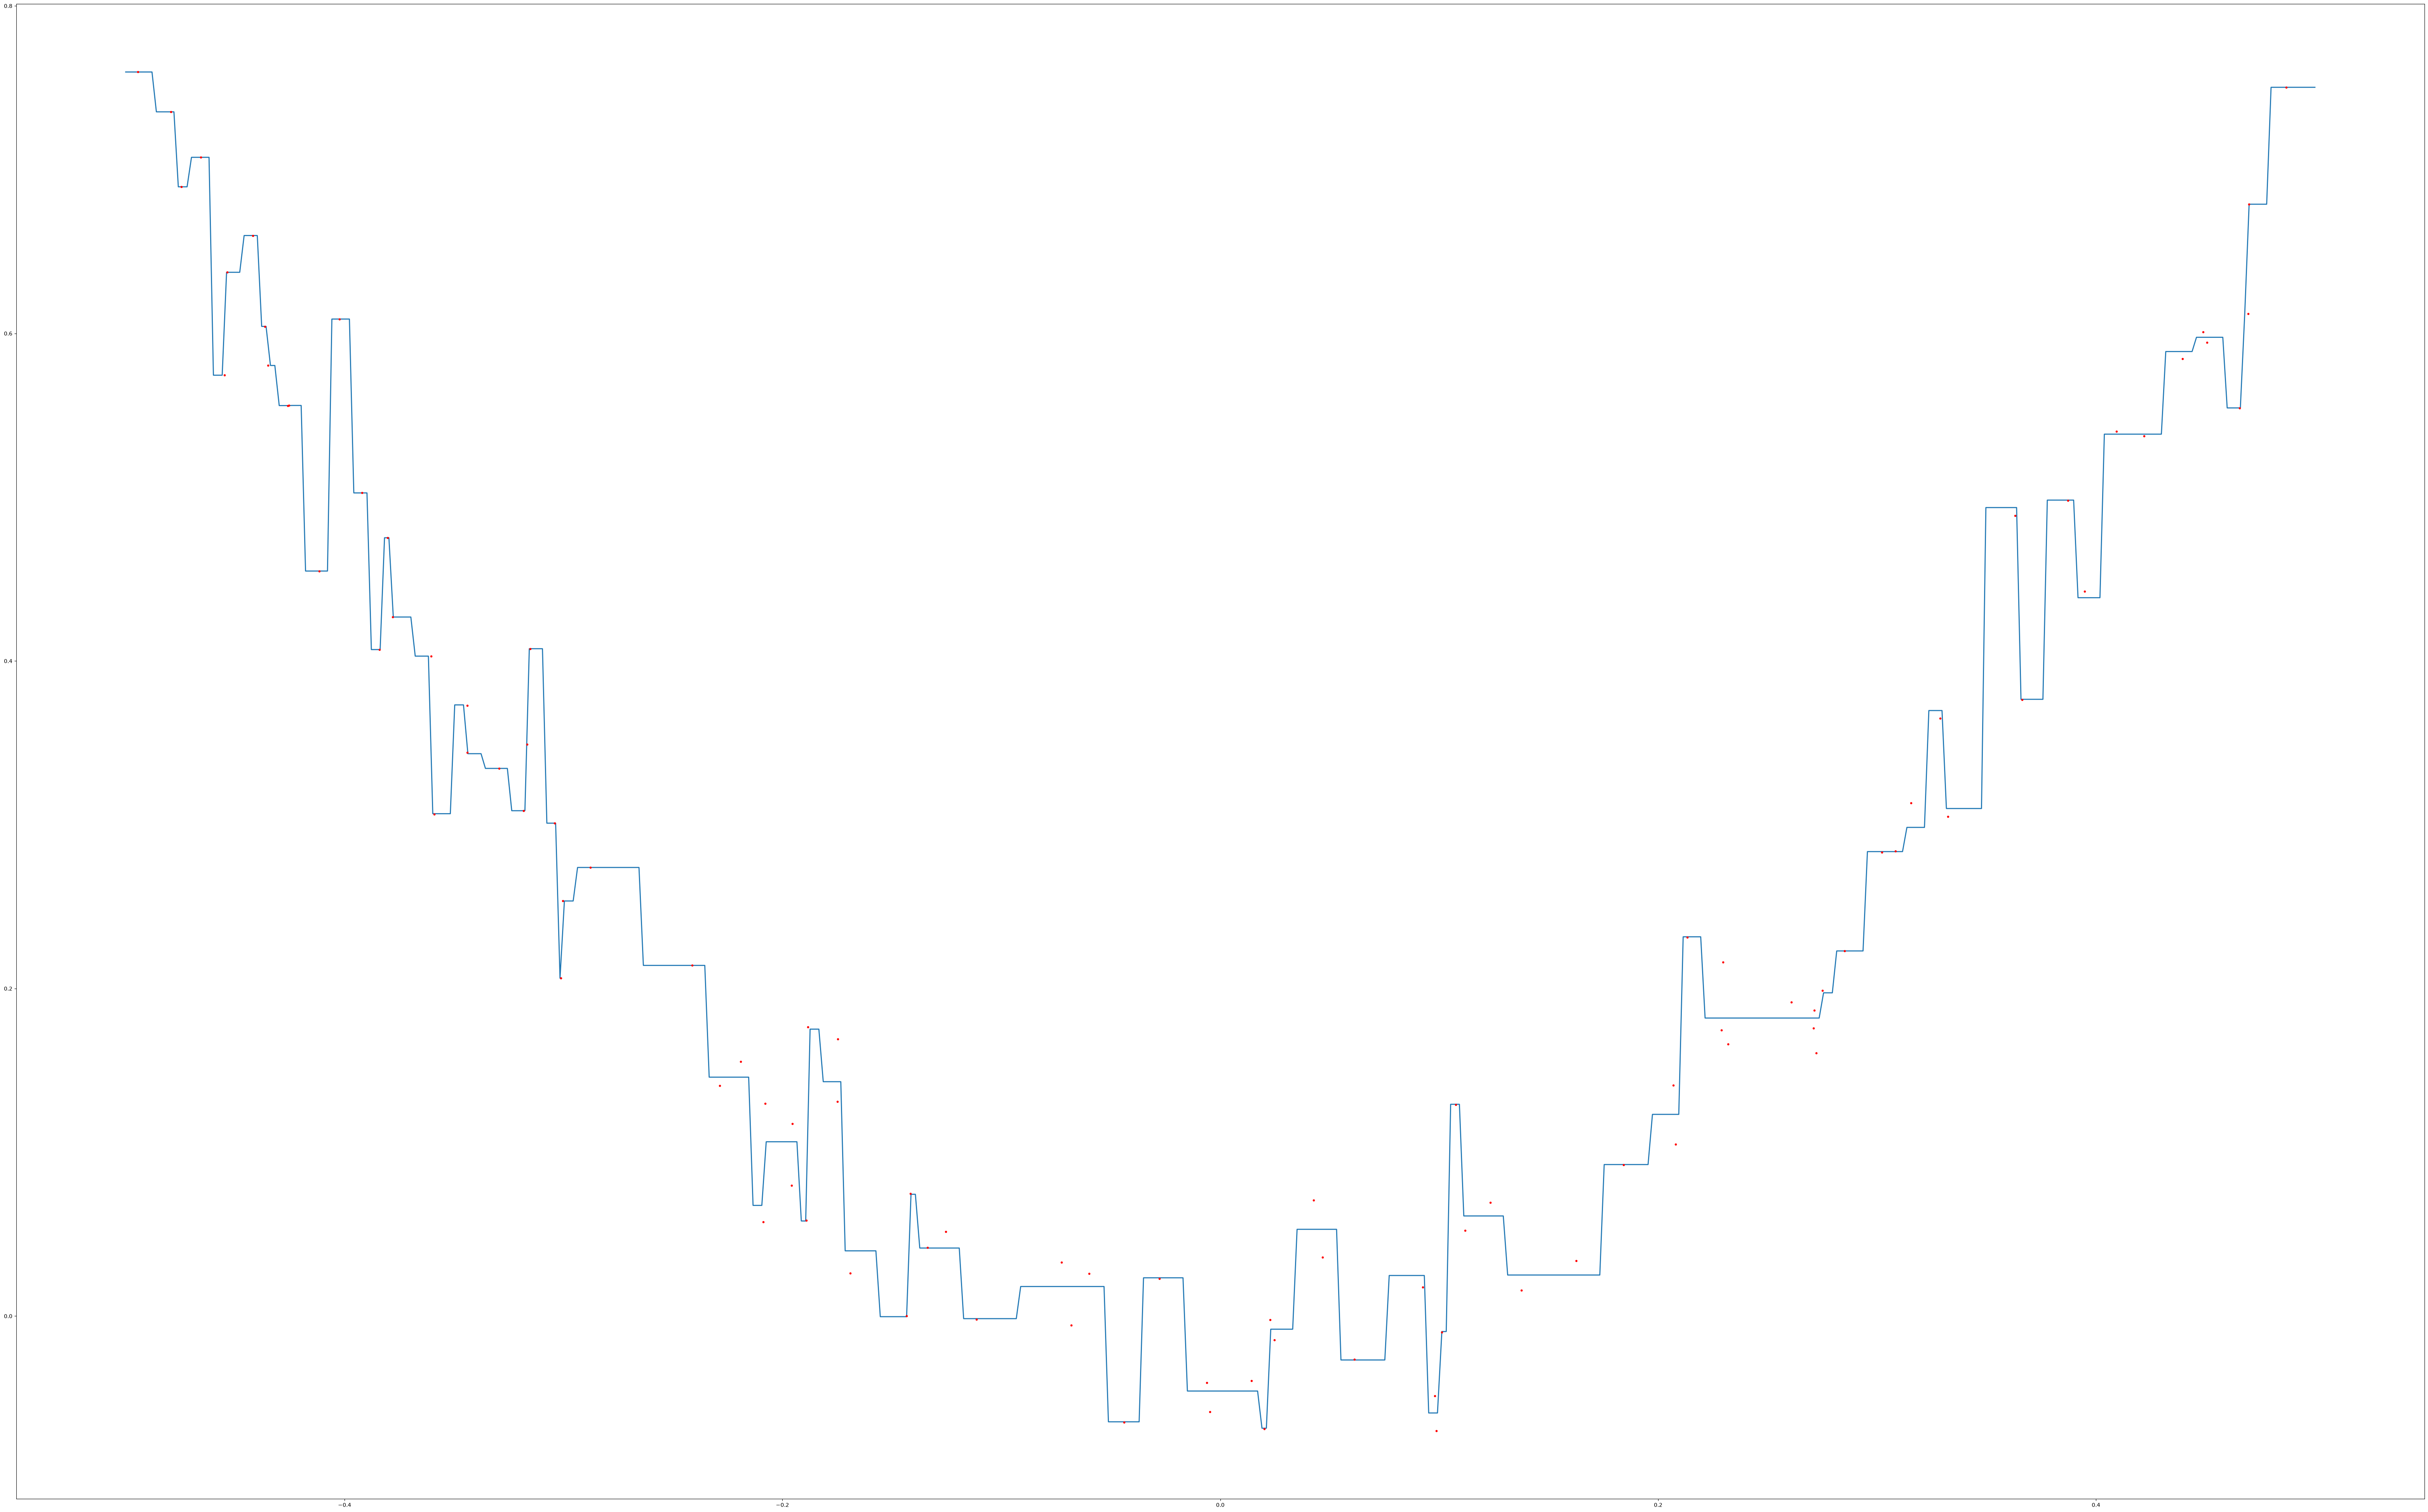

In [72]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
gradient_boost(X,y,5,lr=1)

## 4) Stacking

In [73]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import StackingClassifier

In [74]:
df = pd.read_csv('DataSets/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [75]:
X = df.drop(columns=['target'])
y = df['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=8)

estimators = [
    ('rf', RandomForestClassifier(n_estimators=10, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=10)),
    ('gbdt',GradientBoostingClassifier())
]

clf = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(), cv=10)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Accuracy Score", accuracy_score(y_test,y_pred))

Accuracy Score 1.0


# K-Means Clustering

### K-Means Clustering Code using library

In [76]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import pandas as pd

In [77]:
df = pd.read_csv('DataSets/student.csv')
df.head()

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110


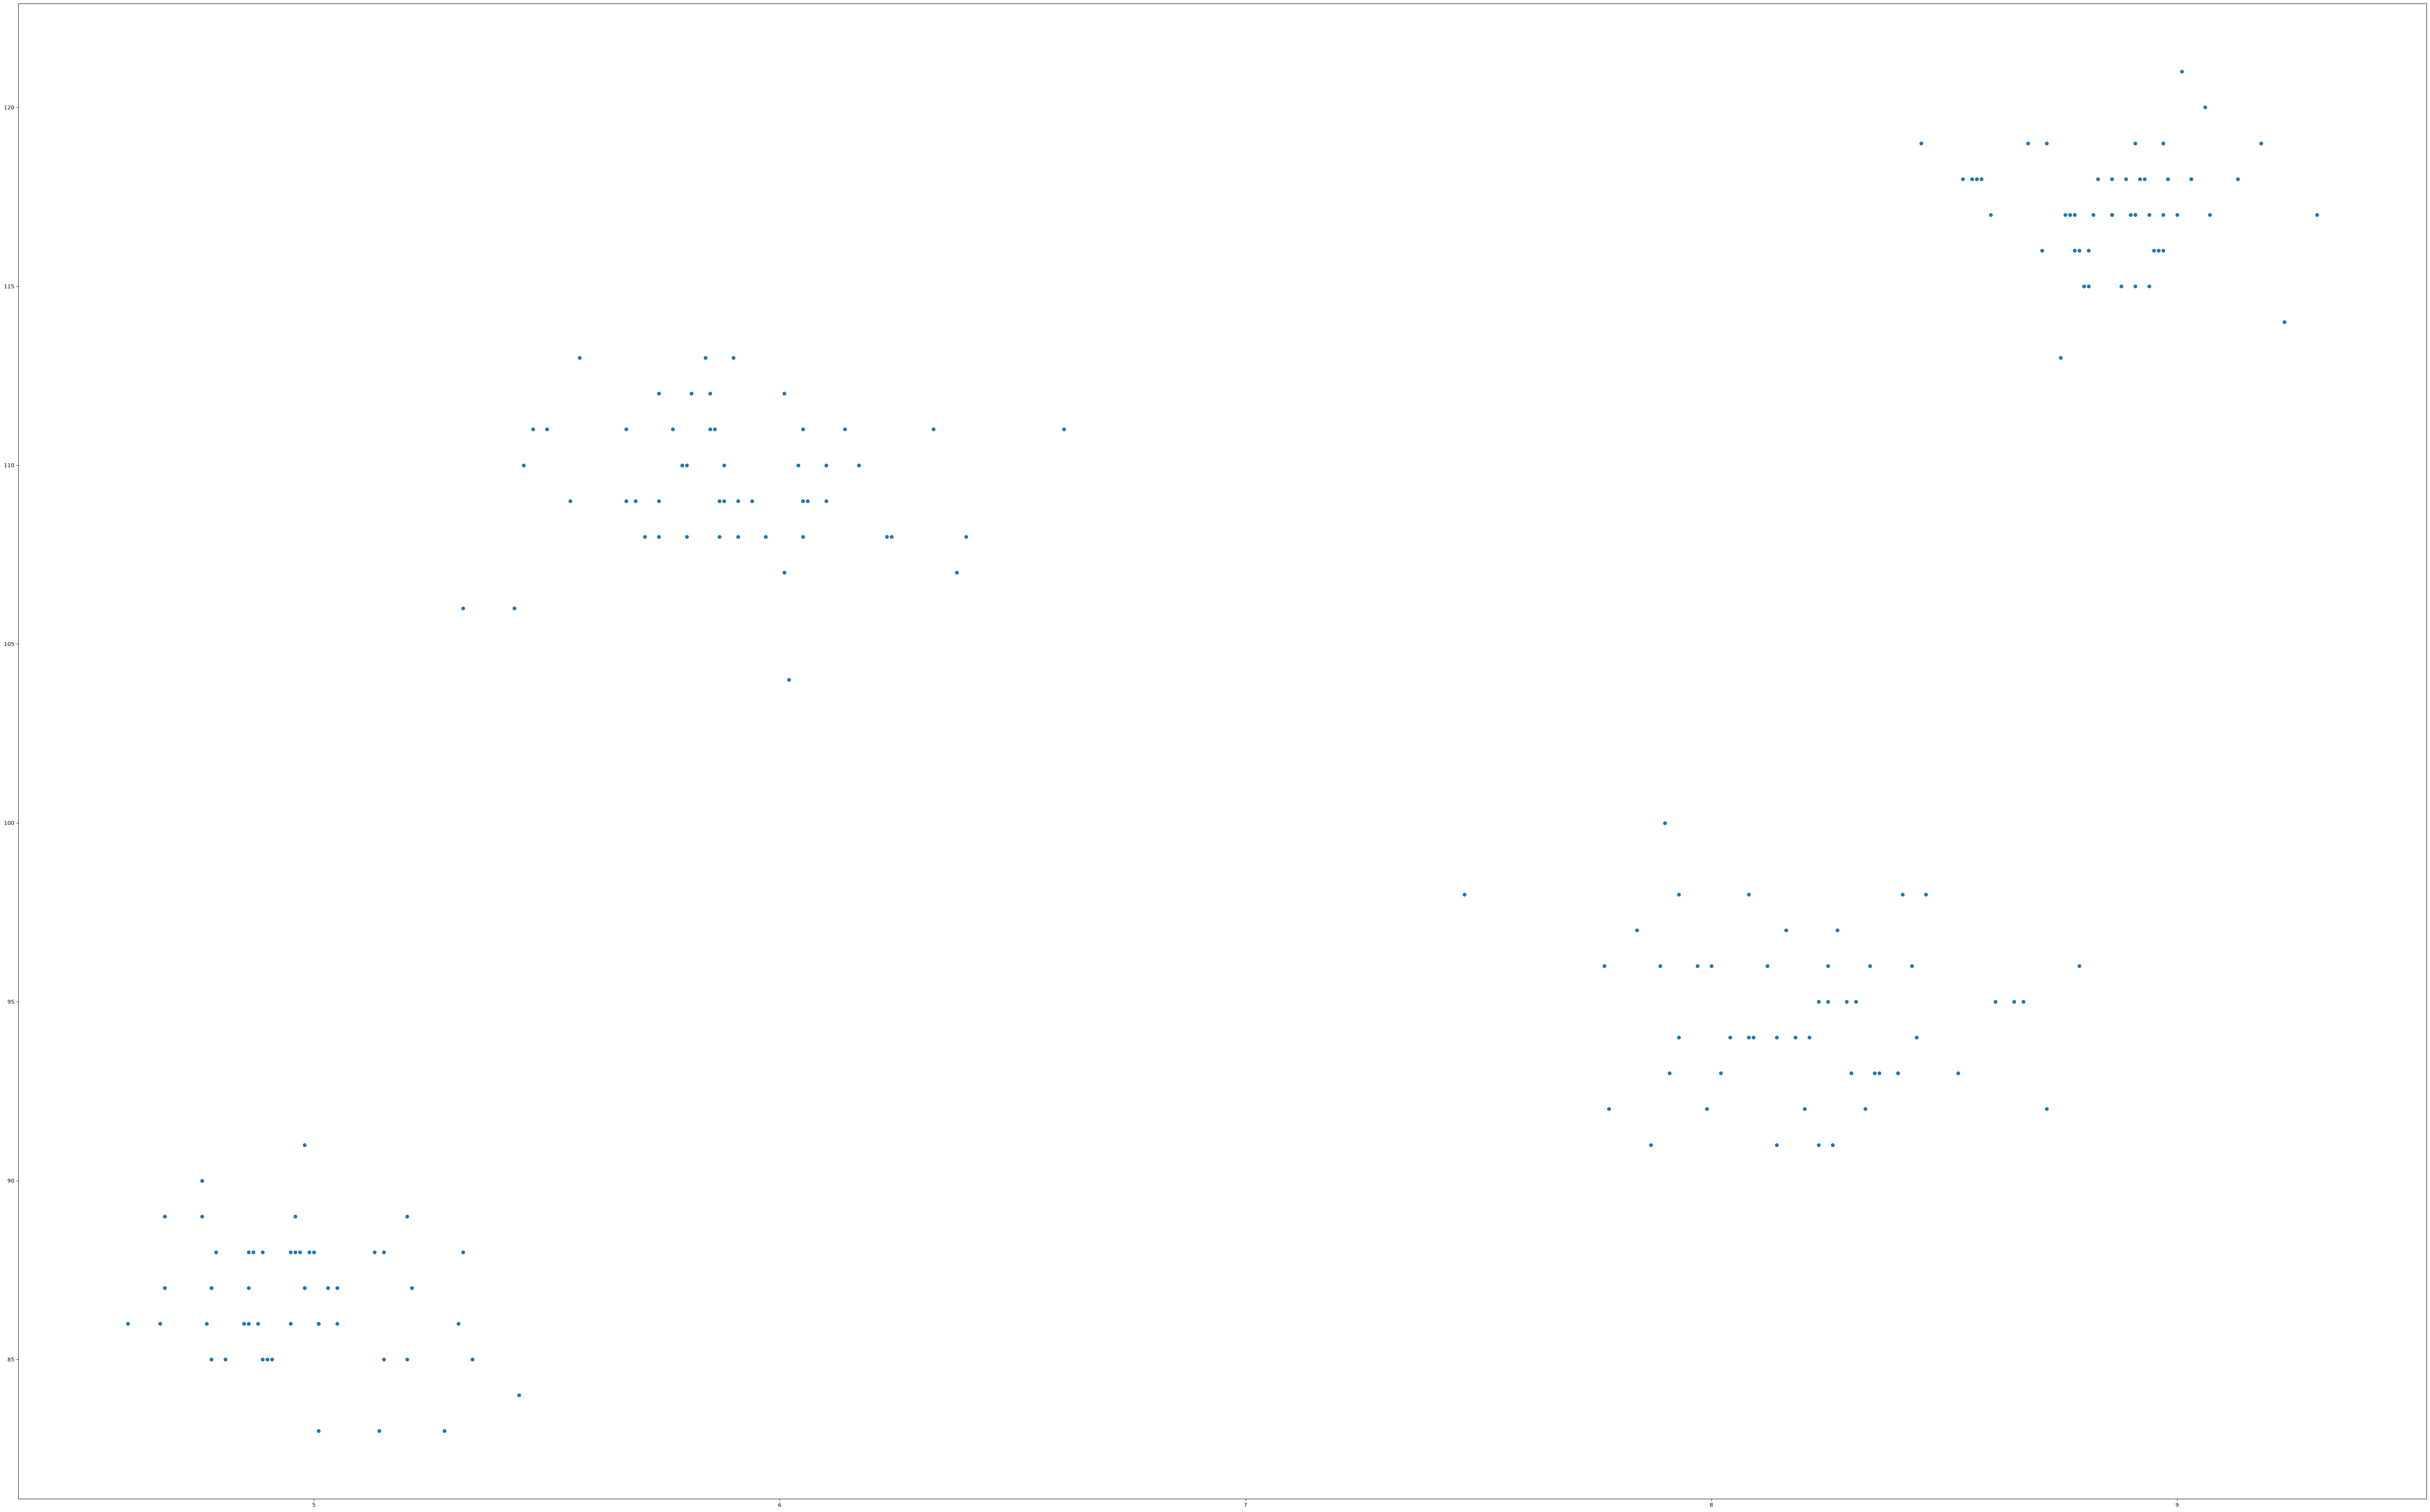

In [78]:
plt.scatter(df['cgpa'],df['iq'])

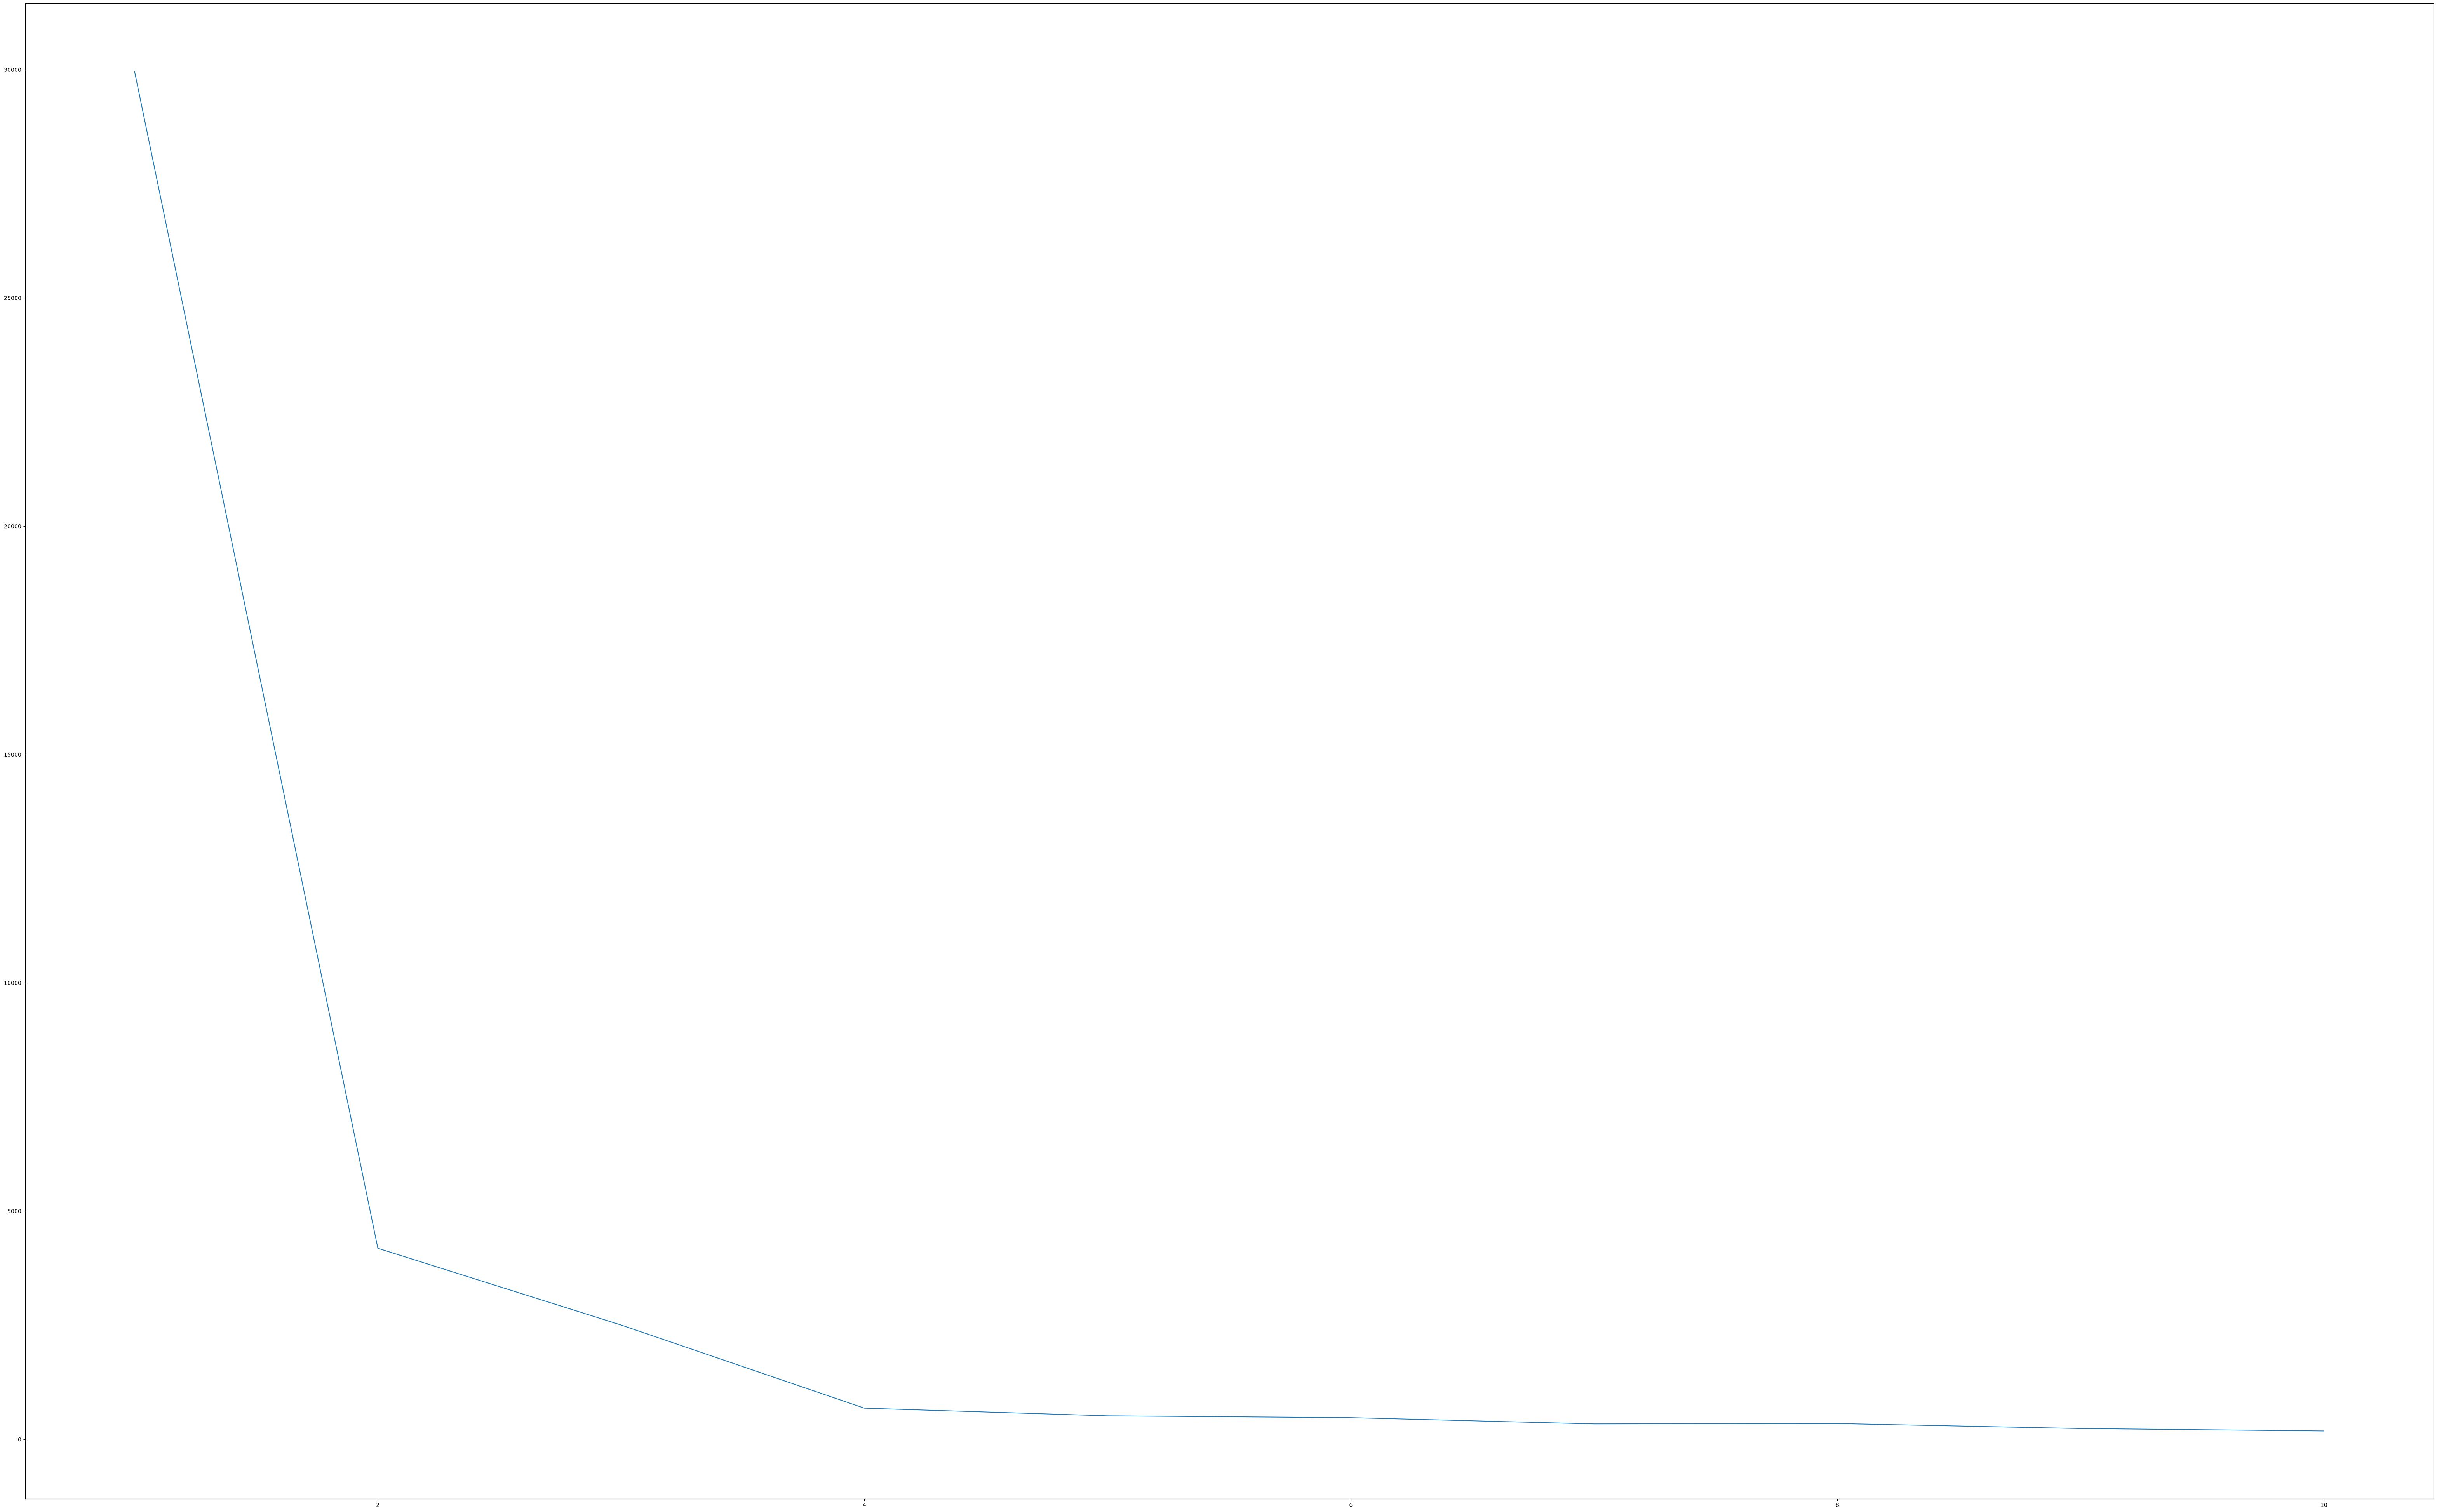

In [79]:
#finding best n using elbow method

wcss = []

for i in range(1,11):
    km = KMeans(n_clusters=i)
    km.fit_predict(df)
    wcss.append(km.inertia_)


plt.plot(range(1,11),wcss)

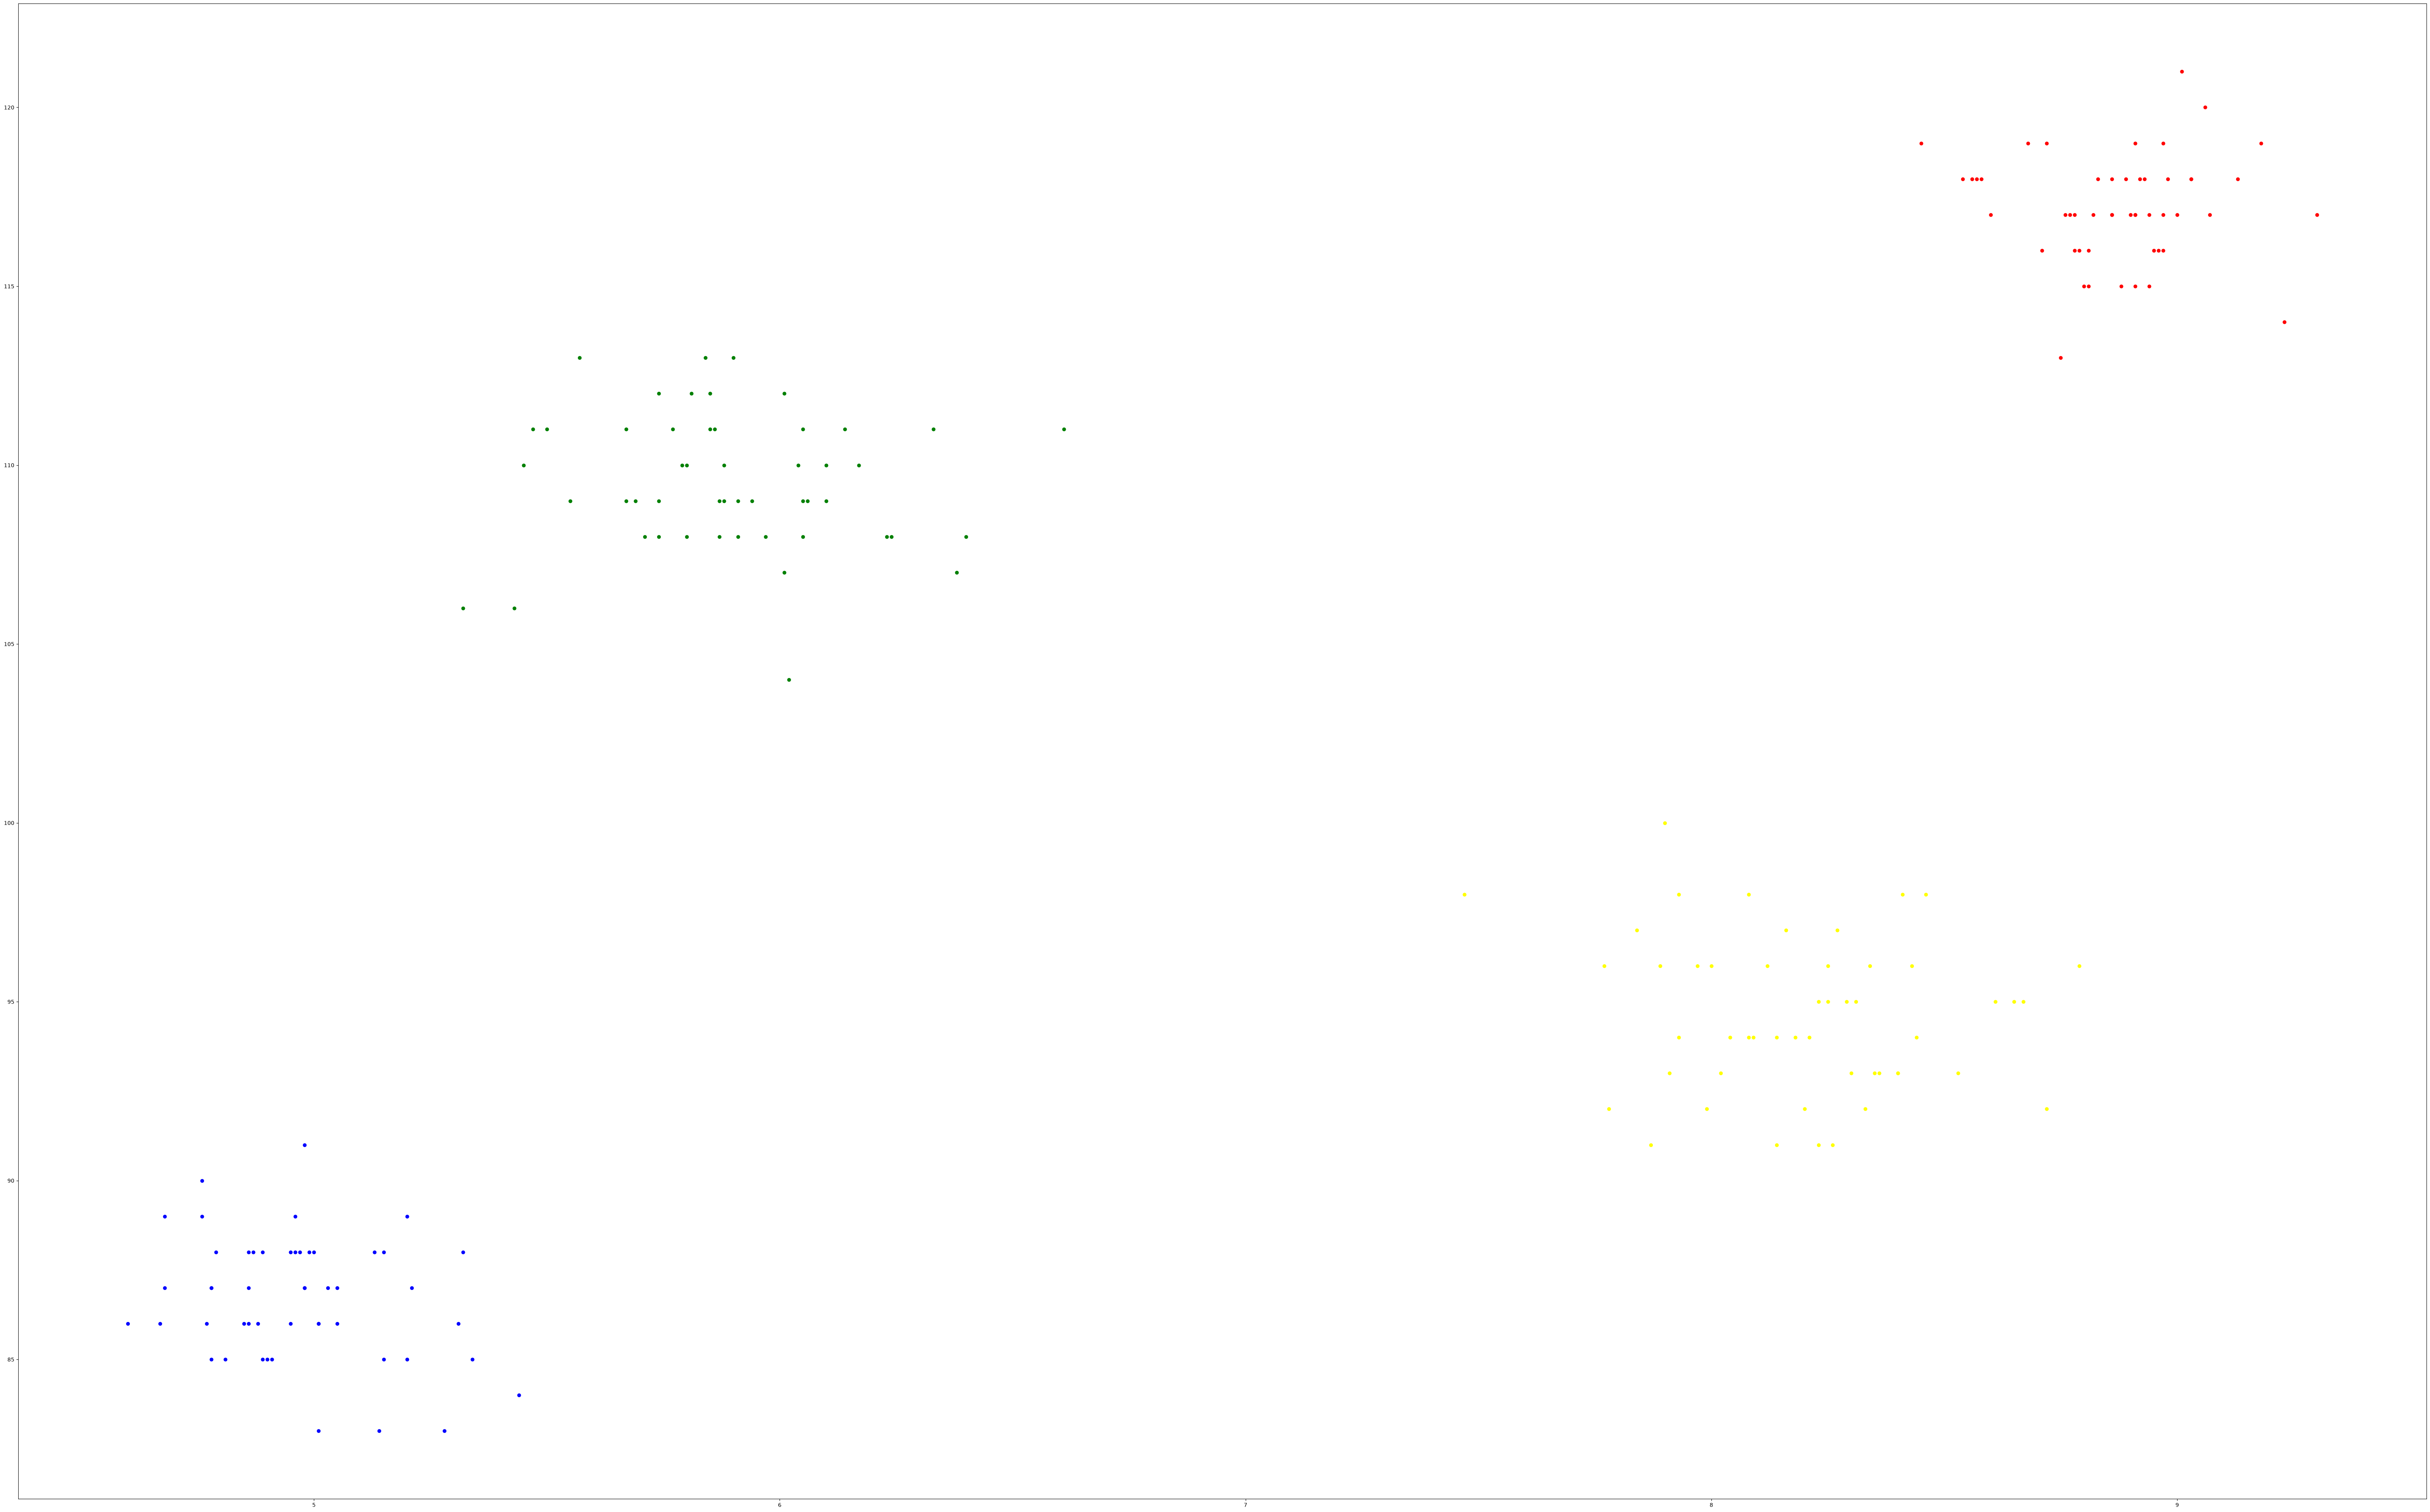

In [80]:
X = df.iloc[:,:].values
km = KMeans(n_clusters=4)
y_means = km.fit_predict(X)

plt.scatter(X[y_means == 0,0],X[y_means == 0,1],color='blue')
plt.scatter(X[y_means == 1,0],X[y_means == 1,1],color='red')
plt.scatter(X[y_means == 2,0],X[y_means == 2,1],color='green')
plt.scatter(X[y_means == 3,0],X[y_means == 3,1],color='yellow')

### K-Means Clustering Code from Scratch

   cgpa   iq  cluster
0  5.13   88        3
1  5.90  113        0
2  8.36   93        1
3  8.27   97        1
4  5.45  110        0


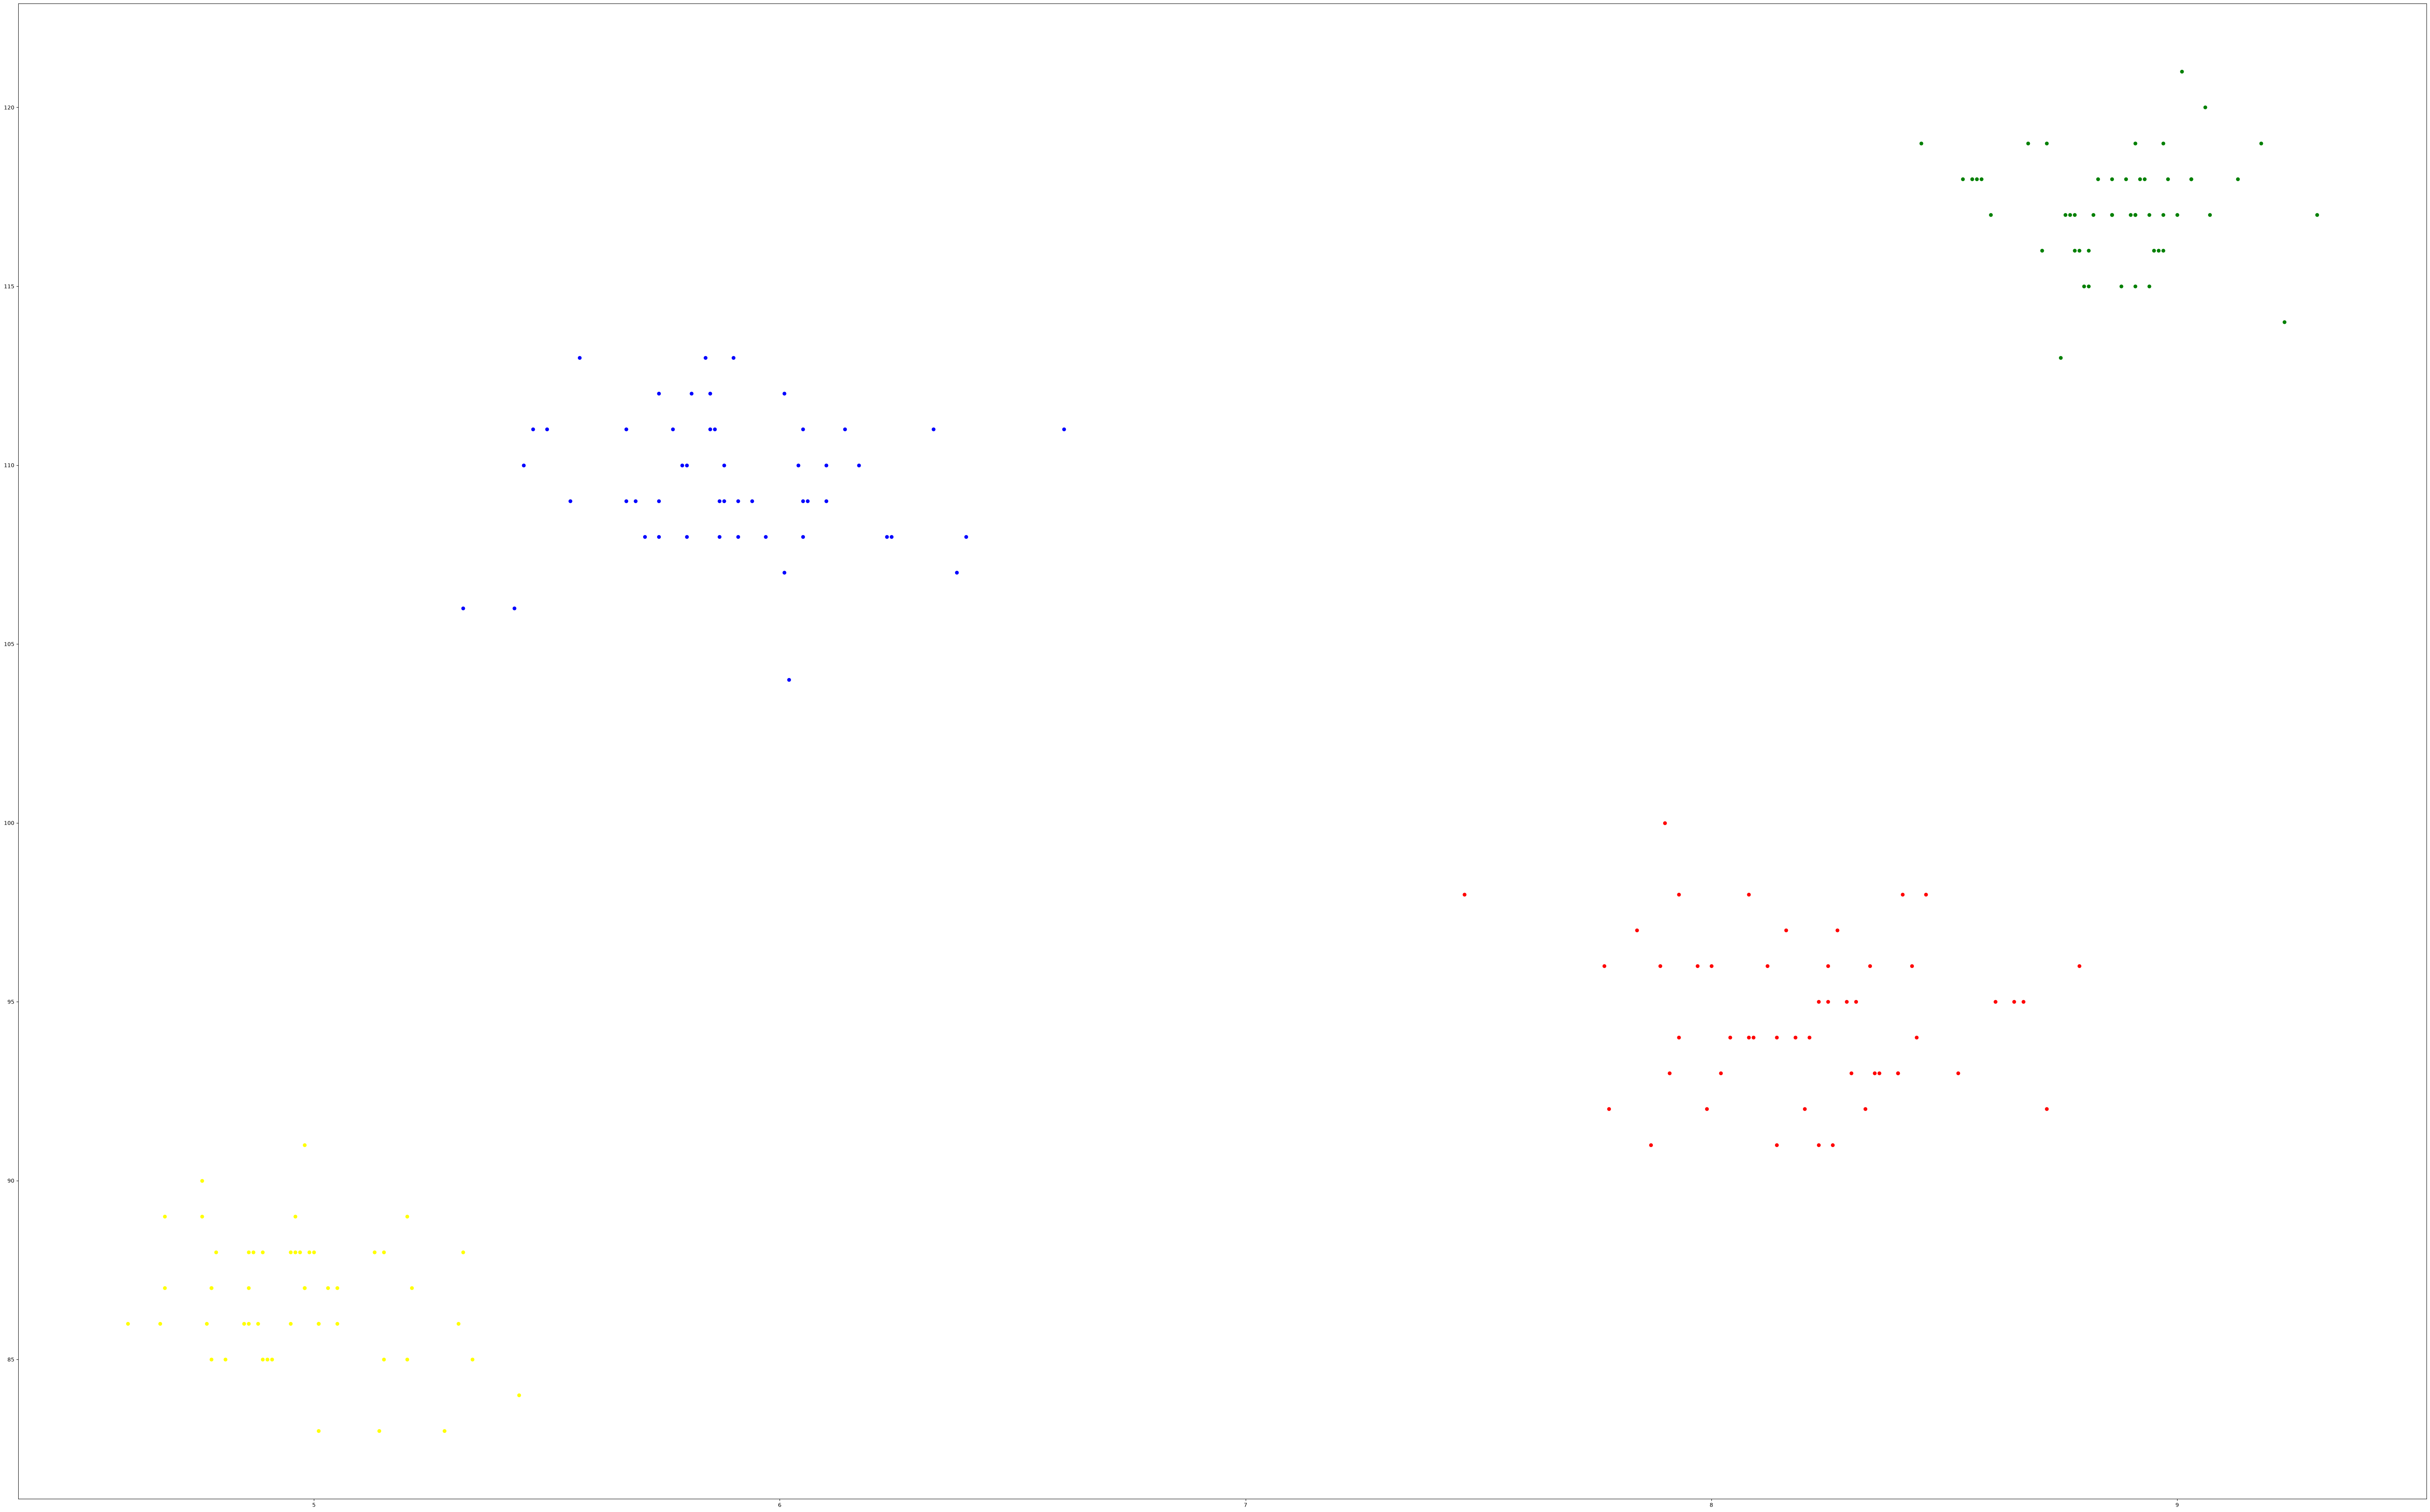

In [81]:
class MyKMeans:
    def __init__(self,n_clusters=2,max_iter=100):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.centroids = None

    def fit_predict(self,X):

        random_index = random.sample(range(0,X.shape[0]),self.n_clusters)
        self.centroids = X[random_index]

        for i in range(self.max_iter):
            # assign clusters
            cluster_group = self.assign_clusters(X)
            old_centroids = self.centroids
            # move centroids
            self.centroids = self.move_centroids(X,cluster_group)
            # check finish
            if (old_centroids == self.centroids).all():
                break

        return cluster_group

    def assign_clusters(self,X):
        cluster_group = []
        distances = []

        for row in X:
            for centroid in self.centroids:
                distances.append(np.sqrt(np.dot(row-centroid,row-centroid)))
            min_distance = min(distances)
            index_pos = distances.index(min_distance)
            cluster_group.append(index_pos)
            distances.clear()

        return np.array(cluster_group)

    def move_centroids(self,X,cluster_group):
        new_centroids = []

        cluster_type = np.unique(cluster_group)

        for type in cluster_type:
            new_centroids.append(X[cluster_group == type].mean(axis=0))

        return np.array(new_centroids)


X = df.iloc[:,:].values

mkmc = MyKMeans(n_clusters=3)
clusters = km.fit_predict(X)
df['cluster'] = clusters

print(df.head())

plt.scatter(df[df['cluster'] == 0]['cgpa'], df[df['cluster'] == 0]['iq'], color='blue')
plt.scatter(df[df['cluster'] == 1]['cgpa'], df[df['cluster'] == 1]['iq'], color='red')
plt.scatter(df[df['cluster'] == 2]['cgpa'], df[df['cluster'] == 2]['iq'], color='green')
plt.scatter(df[df['cluster'] == 3]['cgpa'], df[df['cluster'] == 3]['iq'], color='yellow')